# DERCONNECT real-data exploration and integration preparation
Checkpoint: November 6, 2026. This notebook is an offline inspection workflow, not dashboard ingestion or fault diagnosis. Clear all outputs before committing. Samples are file prefixes, not random or complete observations.

## A — Dataset overview and provenance
Instructor Haojian Jin supplied January–May 2026 data for five meters (coverage is reported, **not yet verified**). Authorized classifications: E2451 Instructional; E3020 Mixed; E3510/E7080/E7085 Office. Do not infer named buildings or electrical relationships. The approximately 3 GB local archive is not bundled or uploaded. Raw measurements and local reports must stay outside version control.

The dashboard fixtures are simulated hourly kW with simulated weather, occupancy, forecasts, labels and detections; these do not describe this archive. The browser CSV view accepts a separate provisional `timestamp,meter_id,kw` format, not arbitrary raw registers.

Unit documentation: [`data/Meter Reading Mapping.csv`](../data/Meter%20Reading%20Mapping.csv) is now the register/unit reference. Section B checks its names against file headers and its unit tokens against the existing numerical helpers. Documented units do not certify calibration, scaling, signs or phase relationships.

Install `requirements-derconnect.txt`, set `DERCONNECT_DATA_PATH` locally, then run all cells. The utility inventories ZIP metadata and streams a bounded prefix of each CSV/TSV. Parquet is optional and only read when the complete member fits the byte budget; larger Parquet needs local metadata/row-group work. Unsupported formats appear as explicit errors. No archive extraction occurs.

In [1]:
import os

os.environ["DERCONNECT_DATA_PATH"] = os.path.expanduser(
    "~/Desktop/Haojian_Data.zip"
)

from pathlib import Path
import os, sys, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/inspect_derconnect.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'tools'))
from inspect_derconnect import inspect, read_member, METERS, UNITS
path_text = os.environ.get('DERCONNECT_DATA_PATH', '')
DATA_PATH = Path(path_text).expanduser() if path_text else None
report = None
if DATA_PATH is None or not DATA_PATH.is_file():
    print('Real data unavailable. Set DERCONNECT_DATA_PATH to your local ZIP and restart/run all. No findings or plots generated.')
else:
    report = inspect(DATA_PATH, rows=2000, max_bytes=8*1024*1024)
    display(pd.Series({k:v for k,v in report.items() if k not in ['files', 'schema_variants']}))
    display(pd.DataFrame([{k:v for k,v in f.items() if k in ['name','meter','months_in_name','format','compressed_bytes','uncompressed_bytes','inspection_error']} for f in report['files']]))

archive_bytes                                                      3513736717
scope                       Per-file prefix samples; no full-data claims o...
file_count                                                                 25
compressed_bytes                                                   3513729939
uncompressed_bytes                                                11945502711
meters_observed_in_paths                  [E2451, E3020, E3510, E7080, E7085]
missing_expected_meters                                                    []
month_note                  Name tokens only; verify timestamp coverage be...
dtype: object

,name,meter,months_in_name,compressed_bytes,uncompressed_bytes,format
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,[2026-01],143619676,480616583,.csv
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,[2026-02],129225294,432020055,.csv
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,[2026-03],143337889,481096826,.csv
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,[2026-04],139456279,466089014,.csv
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,[2026-05],144269897,482143079,.csv
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,[2026-04],135525493,478406882,.csv
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,[2026-03],139615836,492953066,.csv
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,[2026-05],140057378,494228518,.csv
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,[2026-02],126936207,446297374,.csv
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,[2026-01],140532601,494013272,.csv


## B — Schema inspection
Compare every file's bounded prefix, including failures. String ingestion preserves missing encodings; inferred numeric counts are separate from storage dtype. Register names/units are now **documented by `data/Meter Reading Mapping.csv`**, separately from file metadata and engineering validation. The reviewed CSV headers match all 35 documented registers in all 25 files; `_time` and `DeviceID` are the only additional columns. The executable check below reports missing/unmapped fields on future inputs and rejects a mismatch between documented and helper units. `--` is preserved for PF and does not establish its numeric convention. Long-form `register,value,unit` files require an adapter; column-name matching alone cannot establish their availability.

In [22]:
import hashlib

def load_unit_documentation(mapping_path, expected_units):
    table = pd.read_csv(mapping_path, dtype=str, keep_default_na=False)
    if list(table.columns) != ['Register Name', 'Units']:
        raise ValueError('Mapping must contain exactly Register Name,Units columns.')
    if table.empty or table['Register Name'].duplicated().any() or table.eq('').any().any():
        raise ValueError('Mapping requires unique nonempty register names and unit tokens.')
    documented = table.set_index('Register Name')['Units'].to_dict()
    # '--' documents no physical unit; the helper's dimensionless label is an alias,
    # not evidence of PF ratio/percent scale, sign or true/displacement definition.
    canonical = {r: ('dimensionless' if u == '--' else u) for r, u in documented.items()}
    if canonical != expected_units:
        raise ValueError('Mapping and numerical-helper units differ; review before calculation.')
    return table, documented

MAPPING_PATH = ROOT / 'data/Meter Reading Mapping.csv'
UNIT_DOCUMENTATION, DOCUMENTED_UNITS = load_unit_documentation(MAPPING_PATH, UNITS)
MAPPING_SHA256 = hashlib.sha256(MAPPING_PATH.read_bytes()).hexdigest()
print('Documented unit source: data/Meter Reading Mapping.csv; SHA-256:', MAPPING_SHA256)
print('Documented registers:', len(DOCUMENTED_UNITS), '— helper unit map agrees, including PF -- alias.')
display(UNIT_DOCUMENTATION)
SCHEMA_UNIT_AUDIT = None
if report:
    display(pd.DataFrame([{'file':f['name'], 'columns':f.get('columns'), 'storage_dtypes':f.get('dtypes'), 'timestamp_candidates':f.get('timestamp_candidates'), 'error':f.get('inspection_error')} for f in report['files']]))
    print('Schema variants:', report['schema_variants'])
    SCHEMA_UNIT_AUDIT = pd.DataFrame([{
        'file': f['name'], 'columns_seen': len(f.get('columns', [])),
        'missing_documented_registers': sorted(set(DOCUMENTED_UNITS)-set(f.get('columns', []))),
        'unmapped_measurement_columns': sorted(set(f.get('columns', []))-set(DOCUMENTED_UNITS)-{'_time', 'DeviceID'}),
        'duplicate_columns': len(f.get('columns', []))-len(set(f.get('columns', []))),
        'inspection_error': f.get('inspection_error'),
    } for f in report['files']])
    display(SCHEMA_UNIT_AUDIT)
    print('The table reports header/register coverage; unit documentation does not validate scaling/calibration or observation completeness.')
else:
    print('Mapping documented; dataset unavailable, so no register/header match is claimed.')


Documented unit source: data/Meter Reading Mapping.csv; SHA-256: 863e8ee978e07f22fc2411fe3ca18359ca98ecb6600e61aa55ffab06242d7c92
Documented registers: 35 — helper unit map agrees, including PF -- alias.


,Register Name,Units
0,Active_Energy_in_Quadrant_I,kWh
1,Active_Energy_in_Quadrant_II,kWh
2,Active_Energy_in_Quadrant_III,kWh
3,Active_Energy_in_Quadrant_IV,kWh
4,Active_Power_A,W
5,Active_Power_B,W
6,Active_Power_C,W
7,Apparent_Power_A,VA
8,Apparent_Power_B,VA
9,Apparent_Power_C,VA


,file,columns,storage_dtypes,timestamp_candidates,error
0,Haojian_Data/E2451/E2451_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
1,Haojian_Data/E2451/E2451_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
2,Haojian_Data/E2451/E2451_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
3,Haojian_Data/E2451/E2451_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
4,Haojian_Data/E2451/E2451_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
5,Haojian_Data/E3020/E3020_2026-04.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
6,Haojian_Data/E3020/E3020_2026-03.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
7,Haojian_Data/E3020/E3020_2026-05.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
8,Haojian_Data/E3020/E3020_2026-02.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None
9,Haojian_Data/E3020/E3020_2026-01.csv,"[_time, DeviceID, Active_Energy_in_Quadrant_I,...","{'_time': 'str', 'DeviceID': 'str', 'Active_En...",[_time],None


Schema variants: [['_time', 'DeviceID', 'Active_Energy_in_Quadrant_I', 'Active_Energy_in_Quadrant_II', 'Active_Energy_in_Quadrant_III', 'Active_Energy_in_Quadrant_IV', 'Active_Power_A', 'Active_Power_B', 'Active_Power_C', 'Apparent_Power_A', 'Apparent_Power_B', 'Apparent_Power_C', 'Current_A', 'Current_B', 'Current_C', 'Current_Unbalance_Worst', 'Frequency', 'Power_Factor_A', 'Power_Factor_B', 'Power_Factor_C', 'Reactive_Power_A', 'Reactive_Power_B', 'Reactive_Power_C', 'THD_Current_A', 'THD_Current_B', 'THD_Current_C', 'THD_Current_N', 'THD_Voltage_A-N', 'THD_Voltage_B-N', 'THD_Voltage_C-N', 'Voltage_A-B', 'Voltage_A-N', 'Voltage_B-C', 'Voltage_B-N', 'Voltage_C-A', 'Voltage_C-N', 'Voltage_Unbalance_L-N_Worst']]


,file,columns_seen,missing_documented_registers,unmapped_measurement_columns,duplicate_columns,inspection_error
0,Haojian_Data/E2451/E2451_2026-01.csv,37,[],[],0,None
1,Haojian_Data/E2451/E2451_2026-02.csv,37,[],[],0,None
2,Haojian_Data/E2451/E2451_2026-03.csv,37,[],[],0,None
3,Haojian_Data/E2451/E2451_2026-04.csv,37,[],[],0,None
4,Haojian_Data/E2451/E2451_2026-05.csv,37,[],[],0,None
5,Haojian_Data/E3020/E3020_2026-04.csv,37,[],[],0,None
6,Haojian_Data/E3020/E3020_2026-03.csv,37,[],[],0,None
7,Haojian_Data/E3020/E3020_2026-05.csv,37,[],[],0,None
8,Haojian_Data/E3020/E3020_2026-02.csv,37,[],[],0,None
9,Haojian_Data/E3020/E3020_2026-01.csv,37,[],[],0,None


The table reports header/register coverage; unit documentation does not validate scaling/calibration or observation completeness.


## C — Timestamp and sampling analysis
ISO timestamps only: choose `--timestamp` for ambiguous candidates; epoch, split date/time and local formats require explicit parsing rules. Cadence is the modal positive interval in file order, separately per file/meter. Duplicates and backwards steps are retained as evidence. Gaps use sorted unique times and a 1.5× modal interval threshold; off-cadence uses 1% tolerance. These are diagnostics, not a verified schedule. Cross-file duplicates and full-month coverage remain untested.

Naive timestamps stay naive: do not localize without source confirmation. Campus `America/Los_Angeles` crosses DST on March 8, 2026; nonexistent local times require a documented rule. Explicit offsets identify instants but do not prove a timezone. No real-data use of the dashboard's wall-time-as-UTC shortcut.

In [3]:
if report:
    display(pd.DataFrame([{'file':f['name'], 'meter':f['meter'], **f.get('time', {}), 'note':f.get('time_warning')} for f in report['files']]))
    expected = {f'2026-{m:02}' for m in range(1,6)}
    for meter in METERS:
        observed = {token.replace('_','-') if len(token)==7 else token[:4]+'-'+token[4:] for f in report['files'] if f['meter']==meter for token in f['months_in_name']}
        print(meter, 'missing filename tokens:', sorted(expected-observed), 'unexpected:', sorted(observed-expected))
    print('Filename-month checks are provisional; use timestamps to verify actual coverage.')

,file,meter,parsed,invalid,naive,offset_aware,start,end,duplicate_timestamps,backwards,interval_counts_seconds,modal_interval_seconds,large_gaps,off_cadence,max_gap_seconds,warning,note
0,Haojian_Data/E2451/E2451_2026-01.csv,E2451,2000,0,0,2000,2026-01-01T08:00:00.173662+00:00,2026-01-01T09:06:38.294606+00:00,0,0,"[(2.000324, 5), (1.999874, 5), (1.999929, 5), ...",2.000324,0,0,2.004022,Offsets do not identify a campus timezone,None
1,Haojian_Data/E2451/E2451_2026-02.csv,E2451,2000,0,0,2000,2026-02-01T08:00:01.983799+00:00,2026-02-01T09:06:40.106640+00:00,0,0,"[(2.000529, 7), (2.000067, 6), (1.999802, 5), ...",2.000529,0,2,2.024472,Offsets do not identify a campus timezone,None
2,Haojian_Data/E2451/E2451_2026-03.csv,E2451,2000,0,0,2000,2026-03-01T08:00:01.025074+00:00,2026-03-01T09:06:39.164847+00:00,0,0,"[(1.999973, 5), (2.000434, 4), (2.000538, 4), ...",1.999973,0,322,2.045036,Offsets do not identify a campus timezone,None
3,Haojian_Data/E2451/E2451_2026-04.csv,E2451,2000,0,0,2000,2026-04-01T07:00:01.688498+00:00,2026-04-01T08:06:39.814754+00:00,0,0,"[(1.999855, 6), (2.000135, 6), (1.999827, 5), ...",1.999855,0,109,2.029708,Offsets do not identify a campus timezone,None
4,Haojian_Data/E2451/E2451_2026-05.csv,E2451,2000,0,0,2000,2026-05-01T07:00:00.322278+00:00,2026-05-01T08:06:38.481990+00:00,0,0,"[(2.00028, 6), (1.999836, 5), (2.000113, 5), (...",2.000280,0,16,2.023779,Offsets do not identify a campus timezone,None
5,Haojian_Data/E3020/E3020_2026-04.csv,E3020,2000,0,0,2000,2026-04-01T07:00:01.769625+00:00,2026-04-01T08:06:39.897169+00:00,0,0,"[(2.002963, 2), (1.978699, 2), (2.002466, 2), ...",2.002963,0,590,2.228446,Offsets do not identify a campus timezone,None
6,Haojian_Data/E3020/E3020_2026-03.csv,E3020,2000,0,0,2000,2026-03-01T08:00:01.106570+00:00,2026-03-01T09:06:39.265906+00:00,0,0,"[(2.000077, 3), (2.001187, 2), (2.000814, 2), ...",2.000077,0,694,2.177354,Offsets do not identify a campus timezone,None
7,Haojian_Data/E3020/E3020_2026-05.csv,E3020,2000,0,0,2000,2026-05-01T07:00:00.403158+00:00,2026-05-01T08:06:38.564396+00:00,0,0,"[(2.000229, 3), (2.002951, 3), (2.000533, 3), ...",2.000229,0,218,2.103268,Offsets do not identify a campus timezone,None
8,Haojian_Data/E3020/E3020_2026-02.csv,E3020,2000,0,0,2000,2026-02-01T08:00:00.064319+00:00,2026-02-01T09:06:38.214468+00:00,0,0,"[(2.00288, 3), (2.003294, 3), (1.999792, 3), (...",2.002880,0,430,2.072794,Offsets do not identify a campus timezone,None
9,Haojian_Data/E3020/E3020_2026-01.csv,E3020,2000,0,0,2000,2026-01-01T08:00:00.257808+00:00,2026-01-01T09:06:38.398942+00:00,0,0,"[(2.000298, 4), (1.998832, 3), (2.000385, 3), ...",2.000298,0,490,2.039254,Offsets do not identify a campus timezone,None


E2451 missing filename tokens: [] unexpected: []
E3020 missing filename tokens: [] unexpected: []
E3510 missing filename tokens: [] unexpected: []
E7080 missing filename tokens: [] unexpected: []
E7085 missing filename tokens: [] unexpected: []
Filename-month checks are provisional; use timestamps to verify actual coverage.


## D — Measurement availability and quality
The matrix means “column observed in a sampled schema”, not “valid data for the full period”. Unknown names and metadata remain in the schema table. Ranges, missing encodings and nonnumeric counts are bounded diagnostics; units are documented by the mapping CSV, while scaling/calibration/signs and engineering definitions still require confirmation. Do not treat counter energy as power.

In [23]:
if report:
    availability = pd.DataFrame({m:{r:any(r in f.get('columns',[]) for f in report['files'] if f['meter']==m) for r in UNITS} for m in METERS})
    display(availability)
    quality = pd.DataFrame([{'meter':f['meter'], 'file':f['name'], 'column':c, 'documented_unit':DOCUMENTED_UNITS.get(c), **q} for f in report['files'] for c,q in f.get('quality',{}).items()])
    display(quality)

,E2451,E3020,E3510,E7080,E7085
Active_Energy_in_Quadrant_I,True,True,True,True,True
Active_Energy_in_Quadrant_II,True,True,True,True,True
Active_Energy_in_Quadrant_III,True,True,True,True,True
Active_Energy_in_Quadrant_IV,True,True,True,True,True
Active_Power_A,True,True,True,True,True
Active_Power_B,True,True,True,True,True
Active_Power_C,True,True,True,True,True
Apparent_Power_A,True,True,True,True,True
Apparent_Power_B,True,True,True,True,True
Apparent_Power_C,True,True,True,True,True


,meter,file,column,documented_unit,missing,non_numeric,nonfinite,numeric_count,min,max,negative,adjacent_equal,decreases
0,E2451,Haojian_Data/E2451/E2451_2026-01.csv,_time,NaN,0,2000,0,0,NaN,NaN,0,0,0
1,E2451,Haojian_Data/E2451/E2451_2026-01.csv,DeviceID,NaN,0,2000,0,0,NaN,NaN,0,0,0
2,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_I,kWh,0,0,0,2000,3.073328e+06,3.073369e+06,0,1833,0
3,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_II,kWh,0,0,0,2000,3.000000e-05,3.000000e-05,0,1999,0
4,E2451,Haojian_Data/E2451/E2451_2026-01.csv,Active_Energy_in_Quadrant_III,kWh,0,0,0,2000,0.000000e+00,0.000000e+00,0,1999,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
920,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-C,V,0,0,0,2000,4.850290e+02,4.888888e+02,0,156,931
921,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_B-N,V,0,0,0,2000,2.797855e+02,2.820201e+02,0,157,929
922,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-A,V,0,0,0,2000,4.843855e+02,4.883060e+02,0,157,926
923,E7085,Haojian_Data/E7085/E7085_2026-05.csv,Voltage_C-N,V,0,0,0,2000,2.799835e+02,2.822246e+02,0,156,932


## E — Exploratory visualizations
Choose a successfully inspected file and an exact register. No automatic phase sum is calculated: phase compatibility, simultaneity, net/import conventions and register semantics need confirmation. Hour/day profiles below are retrospective sample means, not energy or complete daily totals. UTC hours for offset-aware timestamps are not campus occupancy hours. Short file prefixes rarely support weekly conclusions.

Run the selected-file cell for each meter and supported voltage/frequency/current/phase register. Compare building classes only with matched windows, cadences and confirmed units; no class comparison is valid from unmatched prefixes. Change `SELECTED_NAME` to select a file explicitly.

Bounded prefix: Haojian_Data/E2451/E2451_2026-01.csv limited: True


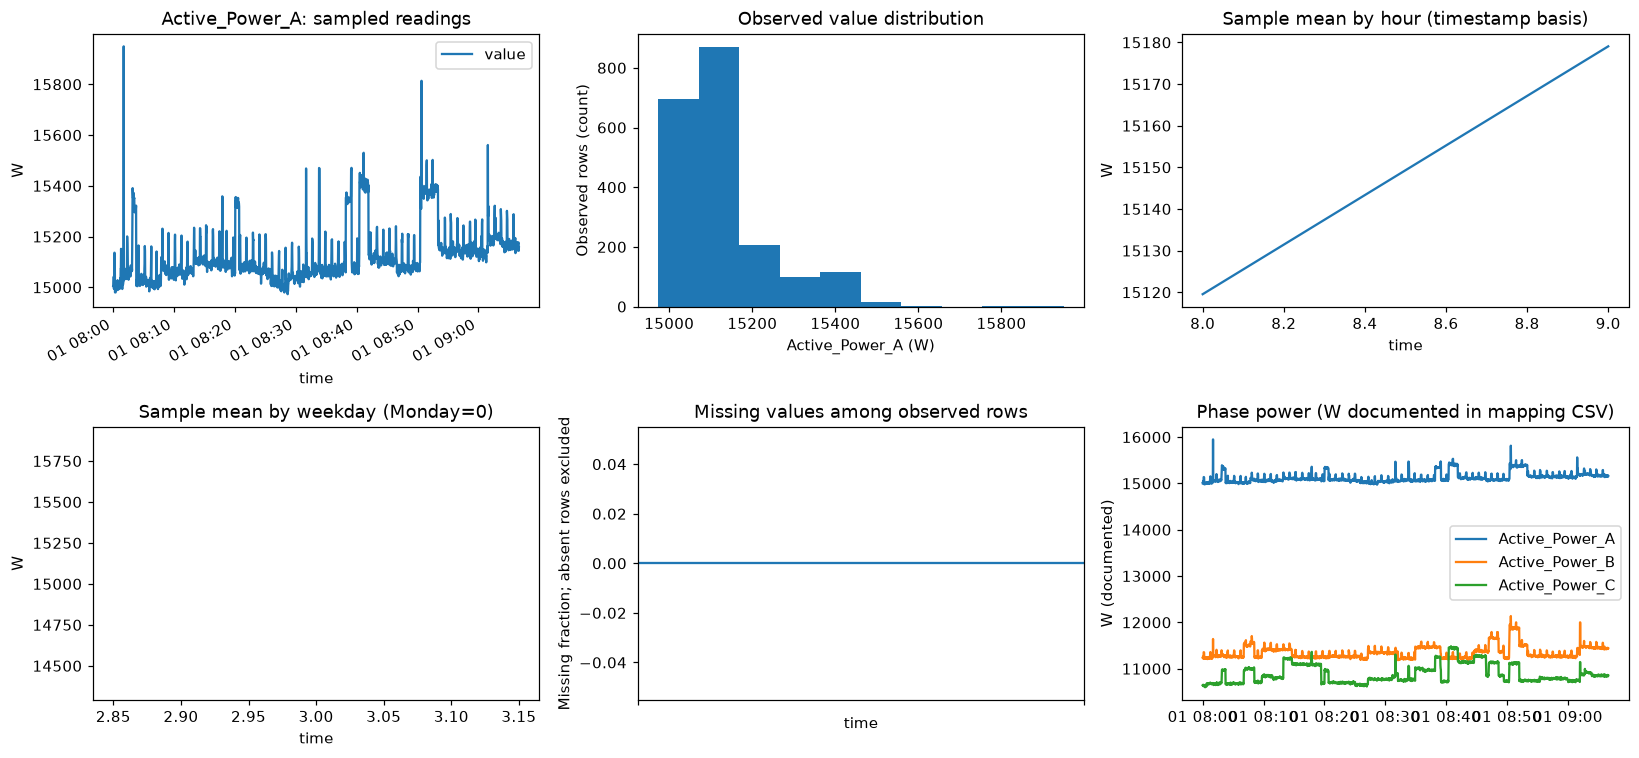

In [32]:
SELECTED_NAME = None
REGISTER = 'Active_Power_A'
frame = None
if report:
    candidates = [f for f in report['files'] if 'time_column' in f and REGISTER in f.get('columns', [])]
    selected = next((f for f in candidates if f['name']==SELECTED_NAME), None) if SELECTED_NAME else next(iter(candidates), None)
    if selected:
        with zipfile.ZipFile(DATA_PATH) as archive:
            frame, limited = read_member(archive, archive.getinfo(selected['name']), rows=2000)
        print('Bounded prefix:', selected['name'], 'limited:', limited)
    else:
        print('No supported timestamp/register pair. Inspect schema and select a register/parser; no plot generated.')
if frame is not None:
    if selected.get('time', {}).get('naive') and selected.get('time', {}).get('offset_aware'):
        print('Mixed time bases: resolve before plotting.')
    else:
        t = pd.to_datetime(frame[selected['time_column']], errors='coerce', utc=bool(selected.get('time',{}).get('offset_aware')))
        v = pd.to_numeric(frame[REGISTER], errors='coerce').replace([float('inf'), -float('inf')], float('nan'))
        sample = pd.DataFrame({'time':t, 'value':v}).dropna(subset=['time']).sort_values('time')
        unit = DOCUMENTED_UNITS.get(REGISTER, 'unit not documented')
        fig, axes = plt.subplots(2, 3, figsize=(15,7))
        sample.plot(x='time', y='value', ax=axes[0,0], title=f'{REGISTER}: sampled readings')
        sample['value'].plot.hist(ax=axes[0,1], title='Observed value distribution')
        sample.groupby(sample.time.dt.hour)['value'].mean().plot(ax=axes[0,2], title='Sample mean by hour (timestamp basis)')
        sample.groupby(sample.time.dt.dayofweek)['value'].mean().plot(ax=axes[1,0], title='Sample mean by weekday (Monday=0)')
        sample.set_index('time')['value'].isna().resample('h').mean().plot(ax=axes[1,1], title='Missing values among observed rows')
        phases = [c for c in ['Active_Power_A','Active_Power_B','Active_Power_C'] if c in frame]
        for c in phases:
            axes[1,2].plot(t, pd.to_numeric(frame[c], errors='coerce'), label=c)
        axes[1,2].set_title('Phase power (W documented in mapping CSV)')
        if phases: axes[1,2].legend()
        for ax in axes.flat: ax.set_ylabel(unit)
        axes[0,1].set_ylabel('Observed rows (count)')
        axes[0,1].set_xlabel(f'{REGISTER} ({unit})')
        axes[1,1].set_ylabel('Missing fraction; absent rows excluded')
        axes[1,2].set_ylabel('W (documented)')
        plt.tight_layout()
        plt.show()

## Preliminary DERCONNECT Dataset Findings

**Dataset source:** Initial DERCONNECT meter dataset shared by Haojian Jin, covering January–May 2026.

### Dataset structure

- The archive contains 25 monthly CSV files organized across five meter/device IDs: E2451, E3020, E3510, E7080, and E7085.
- The archive is approximately 3.5 GB compressed and 11.9 GB uncompressed.
- All five devices have a file for each month from January through May 2026.
- The inspected files share a consistent schema covering active energy, active and apparent power, voltage, current, frequency, power factor, reactive power, harmonic distortion, and phase unbalance.

### Preliminary data quality and sampling

- The sampled timestamps use the `_time` column and include UTC offsets.
- Observations appear to occur approximately every two seconds.
- The initial inspection examined 2,000 rows per monthly file.
- No invalid or duplicate timestamps were identified within those inspected samples.
- The selected measurement registers showed generally complete values in the sampled rows.
- Some registers were constant within the sampled intervals, requiring further investigation.

### Initial visualization

- Real active-power measurements were successfully visualized.
- Short-term load fluctuations and differences between electrical phases were visible.
- The current sampling window spans approximately 67 minutes per file, limiting conclusions about daily and weekly patterns.
- Longer-period aggregation is needed before comparing typical behavior across building types or identifying unusual consumption patterns.

### Implications for dashboard integration

- Raw two-second measurements are unnecessarily detailed for many campus-level dashboard visualizations.
- A reproducible aggregation layer will likely be needed for interactive building-level trends.
- Original-resolution measurements may remain useful for inspecting short-duration events.
- Building identities should remain tied to their provided device IDs until physical building names are verified.
- Real measurements should remain distinguishable from the existing synthetic demonstration dataset.

### Next steps

1. Perform memory-efficient full-period quality and coverage analysis.
2. Evaluate five-minute, fifteen-minute, and hourly aggregation.
3. Verify active-power phase aggregation and timestamp conventions.
4. Coordinate with the anomaly detection team on model input requirements.
5. Define a common data interface for real measurements, forecasts, anomaly scores, and detected events.

**Limitations:** These are preliminary findings based on bounded file-prefix samples, not a comprehensive analysis of the full five-month dataset. No operational electrical faults have been confirmed.

## F — Full Dataset Quality

This section reads every recognized CSV **through EOF**, in chunks, rather than extending the 2,000-row prefixes. It retains compact timestamp arrays for one device at a time, cadence-slot masks, register counters, 5/15/60-minute summaries and a bounded raw detail window in memory. The ZIP is never extracted; no report or aggregated dataset is exported. Expect a multi-minute scan of approximately 11.95 GB decompressed data; progress prints per file and every ten chunks. Rerunning the scan repeats the I/O.

**Explicit assumptions and denominators**
- `FG_MONTHS` and `FG_DEVICES` default to all 25 expected device/month combinations. File counts and unrecognized CSVs are reported; missing files produce zero coverage, not a successful complete-data claim.
- Expected cadence is provisionally **2 seconds**. Coverage is occupied, half-open two-second slots / expected slots in the **entire calendar month**, not rows / rows observed. Nearby jittered readings in the same slot count once. Sampling summaries use sorted unique intervals (median, 1st and 99th percentiles); off-cadence counts use a 10% tolerance around the configured cadence. Use these diagnostics to review the schedule; it is not inferred as an exact hardware guarantee.
- `FG_CALENDAR_TZ = 'America/Los_Angeles'` explicitly assumes campus-local filename months. Verify this with the data owner. Offset-aware source timestamps are converted to UTC; naive, missing and invalid timestamps are reported and excluded. Local month/day boundaries account for DST (March has a 23-hour day). Change this configuration if the month convention differs.
- Source file/device/month labels are validated against `_time` and `DeviceID`. Out-of-month rows and mismatched IDs are reported and excluded from coverage/aggregation, rather than silently reassigned. Exact timestamp duplicates are checked across chunks and files per device. Backwards steps describe file order; intervals describe sorted unique instants.
- Register missing/invalid counts cover **all source rows**, including rows with unusable time. Missing means blank/known missing token or absent register; invalid means nonnumeric/nonfinite. The percentage denominator is source rows × expected mapped registers. Timestamp/ID failures have separate counts. No zeros are substituted.
- Clock jitter can create isolated empty grid slots without a long interval between observations. Separate recording-gap diagnostics count intervals exceeding 1.5 × the configured cadence; cross-month intervals are assigned to the month of the later reading. Neither check establishes an outage.
- Longest missing-slot runs include leading/trailing month gaps. Count all runs, retaining only the longest `FG_MAX_GAPS_PER_MONTH` per device/month for bounded plotting. A gap is a recording issue to investigate, not proof of an outage. Repeated values and negative power also need source context.

The numerical helper is `tools/derconnect_full_quality.py`; it reuses the existing `METERS`, `UNITS` and missing-token mapping. Sections F and G do not run detectors, create baselines, or analyze building consumption patterns.

In [6]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo
from IPython.display import display

FG_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/derconnect_full_quality.py').is_file()), None)
if FG_ROOT is None:
    raise RuntimeError('Launch Jupyter from the repository root or notebooks directory.')
if str(FG_ROOT / 'tools') not in sys.path:
    sys.path.insert(0, str(FG_ROOT / 'tools'))
from derconnect_full_quality import scan_archive, aggregation_summary, PHASES, MONTHS
from inspect_derconnect import METERS, UNITS

# Reuse the path configured in Section A. No new private path is embedded here.
FG_DATA_PATH = DATA_PATH if 'DATA_PATH' in globals() else Path(os.environ.get('DERCONNECT_DATA_PATH', '')).expanduser()
FG_DEVICES = list(METERS)
FG_MONTHS = list(MONTHS)
FG_CALENDAR_TZ = 'America/Los_Angeles'  # Explicit assumption; confirm source-month convention.
FG_CADENCE_SECONDS = 2
FG_CHUNK_ROWS = 25000
FG_MIN_VALID_COVERAGE = 0.80  # Display rule, not an anomaly threshold; inspect sensitivity.
FG_MAX_GAPS_PER_MONTH = 100
FG_DETAIL_DEVICE = 'E2451'
FG_DETAIL_START = None  # None = start of first available source month; or ISO timestamp with Z/offset.
FG_DETAIL_HOURS = 2
FG_MAX_DETAIL_ROWS = 10000

# Keep these False until source documentation confirms all three assumptions.
# Statistical similarity between phases cannot verify additive electrical semantics.
FG_PHASE_REVIEW = {
    'same_device_and_timestamp': False,
    'distinct_additive_phases': False,
    'compatible_signed_power_W': False,
    'source_reference': '',
}
FULL_RESULT = None

In [7]:
FULL_RESULT = None  # Do not retain stale results if a repeated scan fails.
if FG_DATA_PATH is None or not Path(FG_DATA_PATH).is_file():
    print('Full dataset unavailable. Configure DATA_PATH in Section A. No full-data findings generated.')
else:
    FULL_RESULT = scan_archive(
        FG_DATA_PATH, devices=FG_DEVICES, months=FG_MONTHS,
        calendar_tz=FG_CALENDAR_TZ, cadence_s=FG_CADENCE_SECONDS,
        chunksize=FG_CHUNK_ROWS, minimum_coverage=FG_MIN_VALID_COVERAGE,
        phase_review=FG_PHASE_REVIEW, detail_device=FG_DETAIL_DEVICE,
        detail_start=FG_DETAIL_START, detail_hours=FG_DETAIL_HOURS,
        max_detail_rows=FG_MAX_DETAIL_ROWS, max_gaps_per_month=FG_MAX_GAPS_PER_MONTH)
    meta = FULL_RESULT['metadata']
    print(f"EOF reached for {meta['complete_files']} CSVs; expected {meta['expected_files']} device/month files.")
    if meta['unrecognized_csvs']:
        print('Unrecognized/out-of-scope CSVs (not scanned):', meta['unrecognized_csvs'])
    print('All retained results are temporary Python objects; no datasets/reports were saved.')
    print('Total active power:', 'enabled by documented phase review' if FULL_RESULT['total_enabled'] else 'unavailable — phase-sum assumptions unverified')

[1/25] E2451 2026-01: reading complete CSV in 25,000-row chunks
  E2451 2026-01: 25,000 rows scanned
  E2451 2026-01: 275,000 rows scanned
  E2451 2026-01: 525,000 rows scanned
  E2451 2026-01: 775,000 rows scanned
  E2451 2026-01: 1,025,000 rows scanned
  E2451 2026-01: 1,275,000 rows scanned
[1/25] E2451 2026-01: EOF reached (1,338,543 rows)
[2/25] E2451 2026-02: reading complete CSV in 25,000-row chunks
  E2451 2026-02: 25,000 rows scanned
  E2451 2026-02: 275,000 rows scanned
  E2451 2026-02: 525,000 rows scanned
  E2451 2026-02: 775,000 rows scanned
  E2451 2026-02: 1,025,000 rows scanned
[2/25] E2451 2026-02: EOF reached (1,202,349 rows)
[3/25] E2451 2026-03: reading complete CSV in 25,000-row chunks
  E2451 2026-03: 25,000 rows scanned
  E2451 2026-03: 275,000 rows scanned
  E2451 2026-03: 525,000 rows scanned
  E2451 2026-03: 775,000 rows scanned
  E2451 2026-03: 1,025,000 rows scanned
  E2451 2026-03: 1,275,000 rows scanned
[3/25] E2451 2026-03: EOF reached (1,336,696 rows)
[4

In [25]:
if FULL_RESULT is not None:
    fq = FULL_RESULT['summary']
    display(fq[['device', 'month', 'files', 'rows', 'expected_slots', 'observed_slots',
                'coverage_pct', 'missing_slots', 'missing_timestamps', 'invalid_timestamps',
                'naive_timestamps', 'duplicate_rows', 'backwards_steps', 'device_id_mismatch',
                'outside_source_month', 'interval_median_s', 'interval_p01_s', 'interval_p99_s',
                'off_cadence_intervals', 'recording_gap_count', 'max_observed_interval_s', 'gap_count', 'max_gap_s',
                'missing_measurement_pct', 'invalid_measurement_pct', 'potential_issues']])
    fm = FULL_RESULT['measurements'].copy()
    fm['documented_unit'] = fm.register.map(DOCUMENTED_UNITS)
    display(fm[['device', 'month', 'register', 'documented_unit', 'rows', 'finite', 'missing', 'invalid',
                'absent_column_rows', 'missing_pct', 'invalid_pct', 'min', 'max', 'negative', 'equal_adjacent']])
    print('Potential issues needing review (these checks do not diagnose electrical faults):')
    display(fq.loc[fq.potential_issues.ne('No issues under configured checks'),
                   ['device', 'month', 'potential_issues']])
    repeated = fm.loc[(fm.finite > 1) & (fm['min'] == fm['max']),
                     ['device', 'month', 'register', 'finite', 'equal_adjacent']]
    print(f'{len(repeated)} register/month entries are constant among finite values; counters or unused channels may legitimately be constant.')
    display(repeated)

,device,month,files,rows,expected_slots,observed_slots,coverage_pct,missing_slots,missing_timestamps,invalid_timestamps,...,interval_p01_s,interval_p99_s,off_cadence_intervals,recording_gap_count,max_observed_interval_s,gap_count,max_gap_s,missing_measurement_pct,invalid_measurement_pct,potential_issues
0,E2451,2026-01,1,1338543,1339200,1338320,99.934289,880,0,0,...,1.997336,2.002850,105,26,1176.546156,294,1174.0,0.0,0.0,"missing_slots, recording_gap_count"
1,E2451,2026-02,1,1202349,1209600,1201950,99.367560,7650,0,0,...,1.979435,2.020699,103,16,13204.457291,453,13202.0,0.0,0.0,"missing_slots, recording_gap_count"
2,E2451,2026-03,1,1336696,1337400,1335511,99.858756,1889,0,0,...,1.976966,2.023224,117,19,1230.805125,1250,1230.0,0.0,0.0,"missing_slots, recording_gap_count"
3,E2451,2026-04,1,1294677,1296000,1294150,99.857253,1850,0,0,...,1.978059,2.022137,129,22,1271.704112,594,1270.0,0.0,0.0,"missing_slots, recording_gap_count"
4,E2451,2026-05,1,1338436,1339200,1338202,99.925478,998,0,0,...,1.997209,2.002987,121,31,1274.751078,306,1272.0,0.0,0.0,"missing_slots, recording_gap_count"
5,E3020,2026-01,1,1338566,1339200,1335189,99.700493,4011,0,0,...,1.961290,2.044506,525,2,1176.505971,3425,1174.0,0.0,0.0,"missing_slots, recording_gap_count"
6,E3020,2026-02,1,1208965,1209600,1205920,99.695767,3680,0,0,...,1.958022,2.045428,519,1,1198.362584,3083,1196.0,0.0,0.0,"missing_slots, recording_gap_count"
7,E3020,2026-03,1,1336712,1337400,1333328,99.695529,4072,0,0,...,1.960802,2.042411,616,4,1230.700366,3433,1230.0,0.0,0.0,"missing_slots, recording_gap_count"
8,E3020,2026-04,1,1294696,1296000,1291217,99.630941,4783,0,0,...,1.963302,2.039705,660,6,1271.599867,3527,1270.0,0.0,0.0,"missing_slots, recording_gap_count"
9,E3020,2026-05,1,1338464,1339200,1335843,99.749328,3357,0,0,...,1.969239,2.031454,370,3,1274.668561,2665,1272.0,0.0,0.0,"missing_slots, recording_gap_count"


,device,month,register,documented_unit,rows,finite,missing,invalid,absent_column_rows,missing_pct,invalid_pct,min,max,negative,equal_adjacent
0,E2451,2026-01,Active_Energy_in_Quadrant_I,kWh,1338543,1338543,0,0,0,0.0,0.0,3.073328e+06,3.125208e+06,0,1131042
1,E2451,2026-01,Active_Energy_in_Quadrant_II,kWh,1338543,1338543,0,0,0,0.0,0.0,3.000000e-05,3.000000e-05,0,1338542
2,E2451,2026-01,Active_Energy_in_Quadrant_III,kWh,1338543,1338543,0,0,0,0.0,0.0,0.000000e+00,0.000000e+00,0,1338542
3,E2451,2026-01,Active_Energy_in_Quadrant_IV,kWh,1338543,1338543,0,0,0,0.0,0.0,0.000000e+00,0.000000e+00,0,1338542
4,E2451,2026-01,Active_Power_A,W,1338543,1338543,0,0,0,0.0,0.0,1.404938e+04,6.420300e+04,0,76373
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,E7085,2026-05,Voltage_C-A,V,1338453,1338453,0,0,0,0.0,0.0,4.774439e+02,4.971628e+02,0,100632
871,E7085,2026-05,Voltage_C-N,V,1338453,1338453,0,0,0,0.0,0.0,2.765525e+02,2.872131e+02,0,100695
872,E7085,2026-05,Frequency,Hz,1338453,1338453,0,0,0,0.0,0.0,5.992310e+01,6.007827e+01,0,102396
873,E7085,2026-05,Current_Unbalance_Worst,%,1338453,1338453,0,0,0,0.0,0.0,1.940000e-03,3.246500e-01,0,105057


Potential issues needing review (these checks do not diagnose electrical faults):


,device,month,potential_issues
0,E2451,2026-01,"missing_slots, recording_gap_count"
1,E2451,2026-02,"missing_slots, recording_gap_count"
2,E2451,2026-03,"missing_slots, recording_gap_count"
3,E2451,2026-04,"missing_slots, recording_gap_count"
4,E2451,2026-05,"missing_slots, recording_gap_count"
5,E3020,2026-01,"missing_slots, recording_gap_count"
6,E3020,2026-02,"missing_slots, recording_gap_count"
7,E3020,2026-03,"missing_slots, recording_gap_count"
8,E3020,2026-04,"missing_slots, recording_gap_count"
9,E3020,2026-05,"missing_slots, recording_gap_count"


99 register/month entries are constant among finite values; counters or unused channels may legitimately be constant.


,device,month,register,finite,equal_adjacent
1,E2451,2026-01,Active_Energy_in_Quadrant_II,1338543,1338542
2,E2451,2026-01,Active_Energy_in_Quadrant_III,1338543,1338542
3,E2451,2026-01,Active_Energy_in_Quadrant_IV,1338543,1338542
22,E2451,2026-01,THD_Current_N,1338543,1338542
36,E2451,2026-02,Active_Energy_in_Quadrant_II,1202349,1202348
...,...,...,...,...,...
808,E7085,2026-04,Active_Energy_in_Quadrant_IV,1294685,1294684
827,E7085,2026-04,THD_Current_N,1294685,1294684
841,E7085,2026-05,Active_Energy_in_Quadrant_II,1338453,1338452
842,E7085,2026-05,Active_Energy_in_Quadrant_III,1338453,1338452


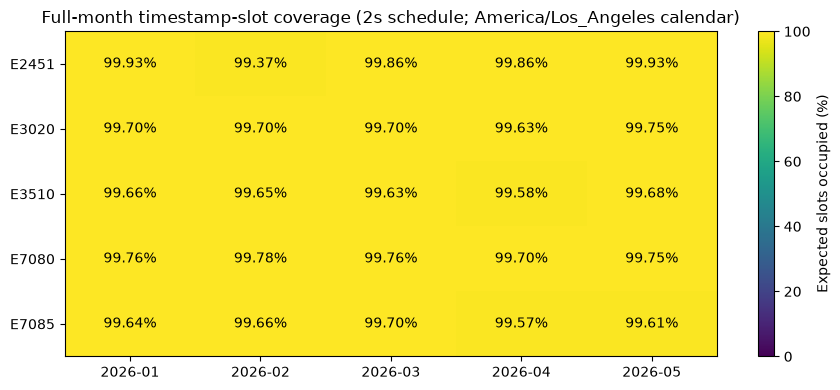

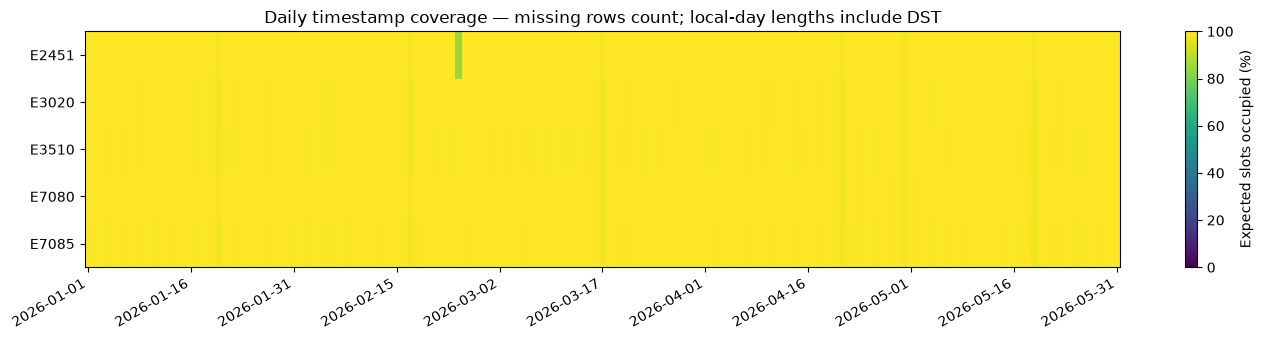

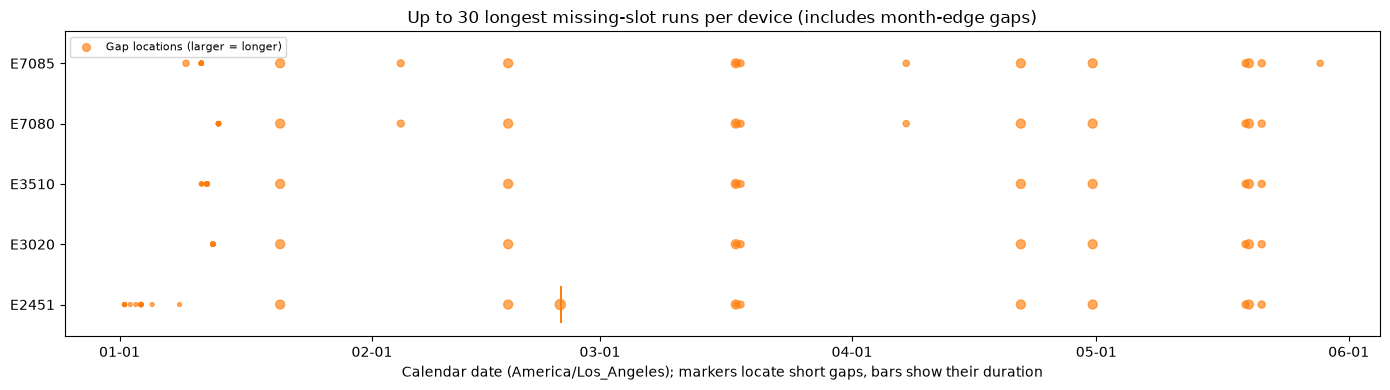

,device,month,start_utc,end_utc,missing_slots,duration_s
172,E2451,2026-02,2026-02-24 11:05:40+00:00,2026-02-24 14:45:42+00:00,6601,13202.0
1470,E3510,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:50+00:00,637,1274.0
2494,E7085,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:50+00:00,637,1274.0
450,E2451,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
984,E3020,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
1925,E7080,2026-05,2026-05-20 00:45:36+00:00,2026-05-20 01:06:48+00:00,636,1272.0
388,E2451,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
855,E3020,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
1349,E3510,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0
1871,E7080,2026-04,2026-04-22 00:33:52+00:00,2026-04-22 00:55:02+00:00,635,1270.0


Elapsed recording gaps (>1.5 × configured cadence); unlike slot holes, these measure time between actual readings:


,device,month,start_utc,end_utc,interval_s,duration_s
39,E2451,2026-02,2026-02-24 11:05:40.404071+00:00,2026-02-24 14:45:42.861362+00:00,13204.457291,13202.457291
203,E7085,2026-05,2026-05-20 00:45:36.569289+00:00,2026-05-20 01:06:51.528037+00:00,1276.958748,1274.958748
157,E3510,2026-05,2026-05-20 00:45:36.548054+00:00,2026-05-20 01:06:51.505241+00:00,1276.957187,1274.957187
104,E2451,2026-05,2026-05-20 00:45:36.414080+00:00,2026-05-20 01:06:49.165158+00:00,1274.751078,1272.751078
128,E3020,2026-05,2026-05-20 00:45:36.497540+00:00,2026-05-20 01:06:49.166101+00:00,1274.668561,1272.668561
176,E7080,2026-05,2026-05-20 00:45:36.497630+00:00,2026-05-20 01:06:49.166165+00:00,1274.668535,1272.668535
77,E2451,2026-04,2026-04-22 00:33:52.408079+00:00,2026-04-22 00:55:02.112191+00:00,1271.704112,1269.704112
170,E7080,2026-04,2026-04-22 00:33:52.514538+00:00,2026-04-22 00:55:02.114453+00:00,1271.599915,1269.599915
122,E3020,2026-04,2026-04-22 00:33:52.514472+00:00,2026-04-22 00:55:02.114339+00:00,1271.599867,1269.599867
150,E3510,2026-04,2026-04-22 00:33:52.576406+00:00,2026-04-22 00:55:02.119615+00:00,1271.543209,1269.543209


In [9]:
if FULL_RESULT is not None:
    matrix = FULL_RESULT['summary'].pivot(index='device', columns='month', values='coverage_pct').reindex(index=FG_DEVICES, columns=FG_MONTHS)
    fig, ax = plt.subplots(figsize=(9, 4))
    image = ax.imshow(matrix.to_numpy(), vmin=0, vmax=100, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    for r in range(len(matrix.index)):
        for c in range(len(matrix.columns)):
            value = matrix.iloc[r, c]
            ax.text(c, r, f'{value:.2f}%', ha='center', va='center', color='black' if value > 60 else 'white')
    ax.set_title(f'Full-month timestamp-slot coverage ({FG_CADENCE_SECONDS}s schedule; {FG_CALENDAR_TZ} calendar)')
    fig.colorbar(image, ax=ax, label='Expected slots occupied (%)')
    plt.tight_layout(); plt.show()

    daily_matrix = FULL_RESULT['daily'].pivot(index='device', columns='date', values='coverage_pct').reindex(index=FG_DEVICES)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    image = ax.imshow(daily_matrix.to_numpy(), vmin=0, vmax=100, cmap='viridis', aspect='auto')
    ticks = np.arange(0, len(daily_matrix.columns), max(1, len(daily_matrix.columns)//10))
    ax.set_xticks(ticks, [daily_matrix.columns[i] for i in ticks], rotation=30, ha='right')
    ax.set_yticks(range(len(daily_matrix.index)), daily_matrix.index)
    ax.set_title('Daily timestamp coverage — missing rows count; local-day lengths include DST')
    fig.colorbar(image, ax=ax, label='Expected slots occupied (%)')
    plt.tight_layout(); plt.show()

    # All gap counts are retained; show at most 30 longest runs per device.
    fgaps = FULL_RESULT['gaps']
    fig, ax = plt.subplots(figsize=(14, 4))
    for y, device in enumerate(FG_DEVICES):
        shown = fgaps.loc[fgaps.device.eq(device)].nlargest(30, 'duration_s')
        if len(shown):
            sizes = 8 + 12*np.log10(np.maximum(shown.duration_s.to_numpy()/FG_CADENCE_SECONDS, 1))
            ax.scatter(mdates.date2num(shown.start_utc.dt.to_pydatetime()), np.full(len(shown), y),
                       s=sizes, color='tab:orange', alpha=.65, label='Gap locations (larger = longer)' if y == 0 else None)
        for gap in shown.itertuples():
            left = mdates.date2num(gap.start_utc.to_pydatetime())
            width = (gap.end_utc-gap.start_utc).total_seconds()/86400
            ax.broken_barh([(left, width)], (y-.3, .6), facecolors='tab:orange')
    ax.set_yticks(range(len(FG_DEVICES)), FG_DEVICES)
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(tz=ZoneInfo(FG_CALENDAR_TZ)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d', tz=ZoneInfo(FG_CALENDAR_TZ)))
    ax.set_title('Up to 30 longest missing-slot runs per device (includes month-edge gaps)')
    ax.set_xlabel(f'Calendar date ({FG_CALENDAR_TZ}); markers locate short gaps, bars show their duration')
    ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()
    display(fgaps.nlargest(20, 'duration_s'))
    observation_gaps = FULL_RESULT['observation_gaps']
    print('Elapsed recording gaps (>1.5 × configured cadence); unlike slot holes, these measure time between actual readings:')
    display(observation_gaps.nlargest(20, 'duration_s'))


In [10]:
if FULL_RESULT is not None:
    fq = FULL_RESULT['summary']
    weighted = fq.observed_slots.sum() / fq.expected_slots.sum() * 100
    print(f"Full scan: {int(fq.rows.sum()):,} source rows; timestamp-slot coverage {weighted:.3f}% under the configured schedule/calendar.")
    print(f"Duplicate rows: {int(fq.duplicate_rows.sum()):,}; missing-slot runs: {int(fq.gap_count.sum()):,}; longest run: {fq.max_gap_s.max():,.1f} seconds.")
    print(f"Missing/invalid/naive source timestamps: {int(fq.missing_timestamps.sum()):,} / {int(fq.invalid_timestamps.sum()):,} / {int(fq.naive_timestamps.sum()):,}.")
    print(f"Missing/invalid mapped measurement values: {int(fq.missing_measurement_values.sum()):,} / {int(fq.invalid_measurement_values.sum()):,}.")
    print(f"Elapsed recording gaps (>1.5 × cadence): {int(fq.recording_gap_count.sum()):,}; largest observed interval: {fq.max_observed_interval_s.max():,.3f} seconds.")
    print('These are recording/measurement diagnostics. They do not establish outages, faults, anomalous behavior or fault-free history.')

Full scan: 32,580,214 source rows; timestamp-slot coverage 99.704% under the configured schedule/calendar.
Duplicate rows: 0; missing-slot runs: 70,939; longest run: 13,202.0 seconds.
Missing/invalid/naive source timestamps: 0 / 0 / 0.
Missing/invalid mapped measurement values: 0 / 0.
Elapsed recording gaps (>1.5 × cadence): 207; largest observed interval: 13,204.457 seconds.
These are recording/measurement diagnostics. They do not establish outages, faults, anomalous behavior or fault-free history.


### Section F — Full Dataset Quality: Key Findings

We analyzed all **25 DERCONNECT CSV files**, containing approximately **32.6 million electricity meter readings** across five devices from January to May 2026.

#### Main Findings

- **High data coverage (99.7%):** Nearly all expected two-second timestamp slots contained readings, indicating that the dataset is largely complete under our assumed sampling schedule.
- **Consistent data structure:** No invalid or duplicate timestamps, incorrect device IDs, or missing/invalid measurement values were found in the recorded data.
- **Recording gaps:** We identified **207 intervals longer than 3 seconds**, with the longest lasting approximately **3 hours and 40 minutes**. These represent periods where measurements may be missing.
- **Missing timestamp slots:** Approximately **70,939 missing-slot runs** were identified. Many may result from slight differences in timestamp timing rather than actual recording interruptions.
- **Constant measurements:** We found **99 register/month combinations** where values remained unchanged. Some may represent unused measurement channels or naturally stable measurements and do not necessarily indicate errors.

#### What Do These Findings Mean?

Overall, the DERCONNECT dataset appears **reliable enough for further analysis and dashboard development**. However, high overall coverage does not guarantee that every individual time period is complete.

The recording gaps and constant measurements should be investigated when relevant, but they do not automatically indicate electrical faults or equipment failures.

#### Recommended Next Steps

1. **Investigate significant gaps:** Identify which devices and timestamps contain the longest recording interruptions.
2. **Preserve missing periods:** Avoid replacing missing readings with zero, since this could incorrectly suggest that electricity consumption dropped.
3. **Track data coverage:** Calculate the percentage of available measurements within each aggregated time interval.
4. **Review constant registers:** Determine which measurements remain unchanged and whether they are useful for analysis.
5. **Proceed with temporal aggregation:** Compare 5-minute, 15-minute, and hourly measurements to determine appropriate resolutions for dashboard visualizations.

#### Dashboard Implications

These findings will help us build a dashboard that distinguishes **missing or incomplete measurements from actual unusual electricity consumption**.

By tracking data availability and preserving recording gaps, we can prevent misleading visualizations and provide building managers and electrical engineers with more reliable information when investigating potential anomalies.

## G — Temporal Aggregation Analysis

Reuse Section F's in-memory summaries; **no second full-data scan and no dataset export**. Active power is converted from **W to kW** using the documented W units in `data/Meter Reading Mapping.csv`: `kW = W / 1000`. The prior helper uses exactly this conversion, so no numerical correction is required. This documents units and verifies the conversion arithmetic, not instrument scaling/calibration/signs. Phases A/B/C remain separate. `Total_Active_Power` is calculated only when the documented `FG_PHASE_REVIEW` is complete; all three phase values must be finite in the same accepted row. Never sum phase averages computed from different missing-data subsets.

Intervals are half-open, UTC-aligned **5-minute, 15-minute and hourly bins**. The 15/60-minute means use valid sample sums/counts, not averages of partially populated five-minute means. Min/max and within-bin standard deviation use original finite observations. These are **observed-sample statistics**, not energy or time-weighted estimates across gaps; no interpolation or zero filling occurs. The scanner keeps empty bins and per-channel slot coverage. The 80% valid-slot coverage display rule is configurable, not an anomaly threshold or proof that the remaining observations represent the whole bin. Exact-duplicate bins are withheld conservatively at every resolution.

`max_observed_kw` summarizes the maxima of eligible bins; `maximum_bin_mean_kw` shows how averaging reduces observed peaks. Within-bin range and standard deviation reveal fluctuations concealed by a mean line. Compare these metrics using the same coverage rule and recognize that different bin sizes can admit different data subsets. A coarser average cannot recover a short missing or transient event.

In [11]:
AGGREGATION_COMPARISON = None
if FULL_RESULT is None:
    print('Run Section F with the full archive before aggregation analysis.')
else:
    AGGREGATION_COMPARISON = aggregation_summary(FULL_RESULT)
    display(AGGREGATION_COMPARISON)
    print(f'Mean/min/max/std are withheld below {FG_MIN_VALID_COVERAGE:.0%} valid-slot coverage or in exact-duplicate bins.')
    print('Negative kW remains signed; peak-reduction percentage is unavailable when the observed maximum is nonpositive.')

,device,interval_minutes,channel,bins,displayed_bins,mean_bin_coverage_pct,min_observed_kw,max_observed_kw,maximum_bin_mean_kw,peak_reduction_pct,median_within_bin_range_kw,median_within_bin_std_kw,duplicate_bins_withheld
0,E2451,5,Active_Power_A,43476,43402,99.796562,12.875011,69.864422,51.062302,26.912296,0.755381,0.163006,0
1,E2451,5,Active_Power_B,43476,43402,99.796562,10.730782,65.623492,46.088587,29.768158,0.781694,0.176303,0
2,E2451,5,Active_Power_C,43476,43402,99.796562,10.272666,63.995566,46.674750,27.065651,0.902043,0.215002,0
3,E2451,15,Active_Power_A,14492,14465,99.796562,12.875011,69.864422,49.289054,29.450423,3.442332,0.435933,0
4,E2451,15,Active_Power_B,14492,14465,99.796562,10.730782,65.623492,44.448402,32.267546,2.791533,0.408318,0
5,E2451,15,Active_Power_C,14492,14465,99.796562,10.272666,63.995566,43.432575,32.131900,2.743766,0.446990,0
6,E2451,60,Active_Power_A,3623,3613,99.796562,12.875011,69.864422,48.261876,30.920668,12.018883,1.281029,0
7,E2451,60,Active_Power_B,3623,3613,99.796562,10.730782,65.623492,43.114157,34.300727,12.176521,1.197420,0
8,E2451,60,Active_Power_C,3623,3613,99.796562,10.272666,63.995566,41.638993,34.934567,12.144539,1.172991,0
9,E3020,5,Active_Power_A,43476,43333,99.694805,16.403768,67.963297,46.630115,31.389269,2.991959,0.617791,0


Mean/min/max/std are withheld below 80% valid-slot coverage or in exact-duplicate bins.
Negative kW remains signed; peak-reduction percentage is unavailable when the observed maximum is nonpositive.


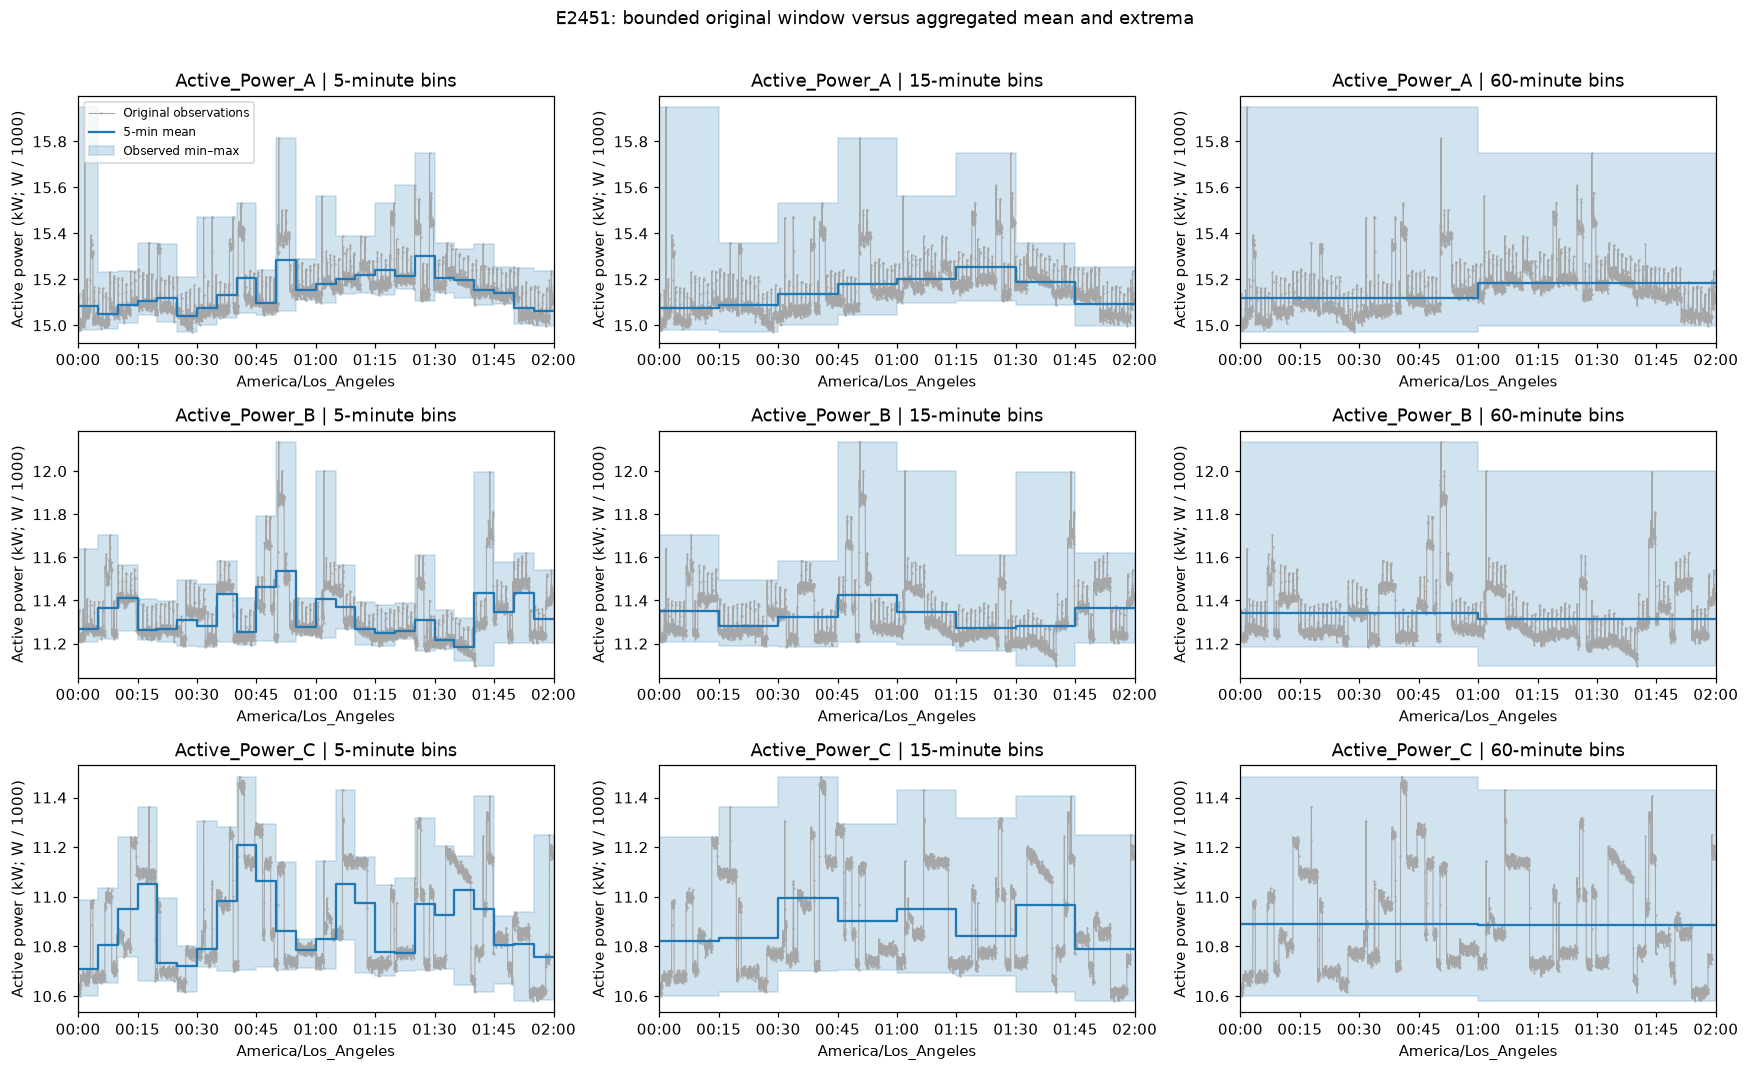

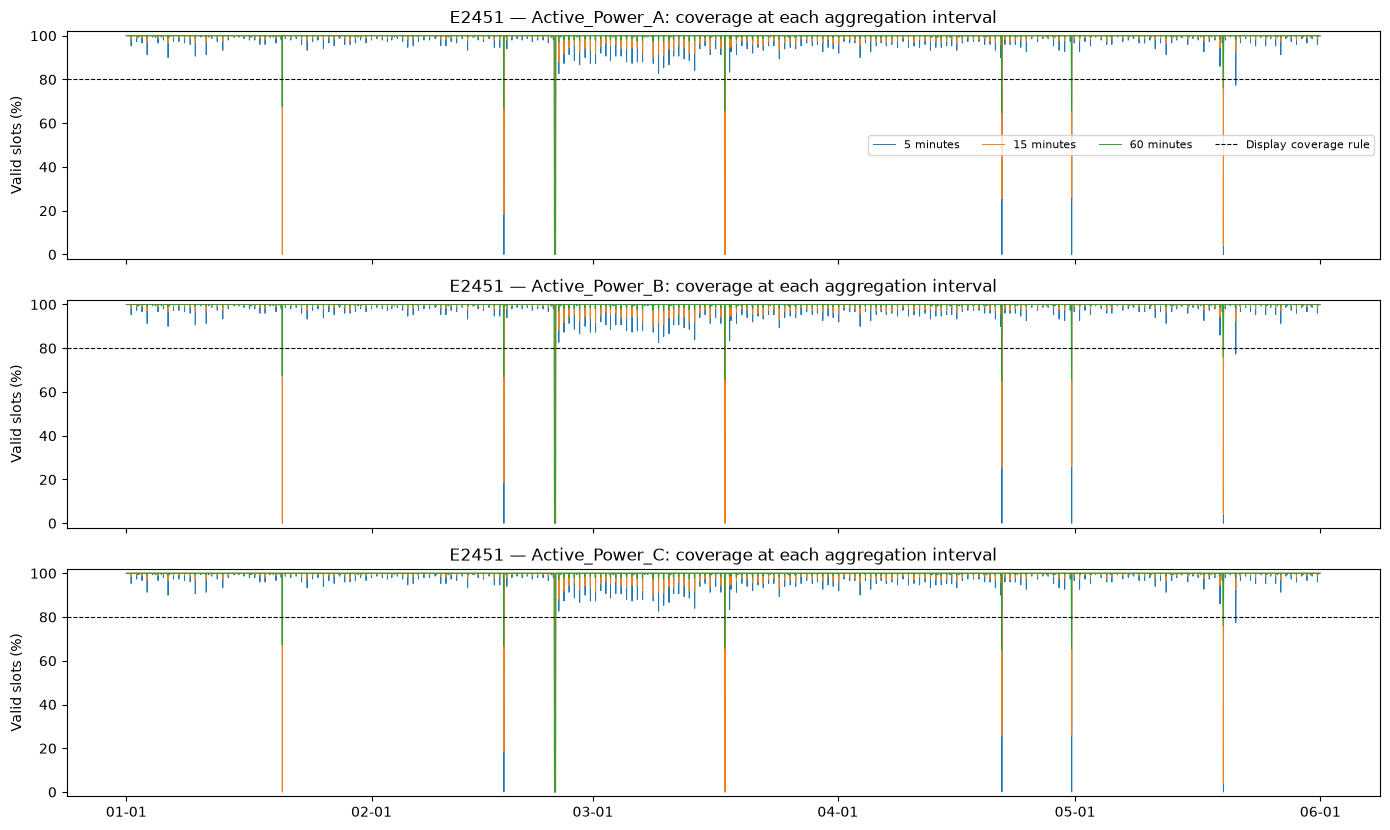

In [26]:
if FULL_RESULT is not None:
    raw = FULL_RESULT['detail']
    meta = FULL_RESULT['metadata']
    if raw.empty:
        print('No accepted measurements in the selected bounded raw window; choose FG_DETAIL_DEVICE/START and rerun F.')
    else:
        fig, axes = plt.subplots(len(FULL_RESULT['channels']), 3, figsize=(16, 3.2*len(FULL_RESULT['channels'])), squeeze=False)
        # Break raw lines at recording gaps rather than connecting across missing periods.
        cuts = np.flatnonzero(np.diff(raw.index.asi8)/1e9 > 1.5*FG_CADENCE_SECONDS) + 1
        segments = np.split(np.arange(len(raw)), cuts)
        for row, channel in enumerate(FULL_RESULT['channels']):
            for col, minutes in enumerate((5, 15, 60)):
                ax = axes[row, col]
                for k, indices in enumerate(segments):
                    ax.plot(raw.index[indices], raw[channel].iloc[indices], color='0.65', linewidth=.7, marker='.', markersize=1,
                            label='Original observations' if k == 0 else None)
                bins = FULL_RESULT['aggregates'][(FG_DETAIL_DEVICE, minutes)]
                window = bins.loc[(bins.index >= meta['detail_start'].floor(f'{minutes}min')) & (bins.index < meta['detail_end'])]
                if len(window):
                    x = window.index.append(pd.DatetimeIndex([window.index[-1]+pd.Timedelta(minutes=minutes)]))
                    mean = window[channel+'__mean_kw'].to_numpy()
                    low = window[channel+'__min_kw'].to_numpy()
                    high = window[channel+'__max_kw'].to_numpy()
                    ax.step(x, np.r_[mean, mean[-1]], where='post', label=f'{minutes}-min mean', color='tab:blue')
                    ax.fill_between(x, np.r_[low, low[-1]], np.r_[high, high[-1]], step='post', alpha=.2, color='tab:blue', label='Observed min–max')
                ax.set_title(f'{channel} | {minutes}-minute bins')
                ax.set_ylabel('Active power (kW; W / 1000)')
                ax.set_xlim(meta['detail_start'], meta['detail_end'])
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=ZoneInfo(FG_CALENDAR_TZ)))
                ax.set_xlabel(FG_CALENDAR_TZ)
                if row == 0 and col == 0: ax.legend(fontsize=8)
        fig.suptitle(f'{FG_DETAIL_DEVICE}: bounded original window versus aggregated mean and extrema', y=1.01)
        plt.tight_layout(); plt.show()
        if meta['detail_truncated']:
            print('Raw detail row cap reached; original trace is truncated. Reduce detail duration or review the row cap and rerun F.')

    fig, axes = plt.subplots(len(FULL_RESULT['channels']), 1, figsize=(14, 2.8*len(FULL_RESULT['channels'])), squeeze=False, sharex=True)
    for row, channel in enumerate(FULL_RESULT['channels']):
        ax = axes[row, 0]
        for minutes in (5, 15, 60):
            bins = FULL_RESULT['aggregates'][(FG_DETAIL_DEVICE, minutes)]
            ax.plot(bins.index, bins[channel+'__coverage_pct'], linewidth=.7, label=f'{minutes} minutes')
        ax.axhline(FG_MIN_VALID_COVERAGE*100, color='black', linestyle='--', linewidth=.8, label='Display coverage rule')
        ax.set_ylim(-2, 102); ax.set_ylabel('Valid slots (%)')
        ax.set_title(f'{FG_DETAIL_DEVICE} — {channel}: coverage at each aggregation interval')
        if row == 0: ax.legend(ncol=4, fontsize=8)
    axes[-1, 0].xaxis.set_major_locator(mdates.AutoDateLocator(tz=ZoneInfo(FG_CALENDAR_TZ)))
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d', tz=ZoneInfo(FG_CALENDAR_TZ)))
    plt.tight_layout(); plt.show()

In [13]:
if AGGREGATION_COMPARISON is not None:
    focus = AGGREGATION_COMPARISON.loc[AGGREGATION_COMPARISON.device.eq(FG_DETAIL_DEVICE)]
    print('Measured peak averaging effects for the selected device (eligible bins only):')
    display(focus[['channel', 'interval_minutes', 'displayed_bins', 'mean_bin_coverage_pct',
                   'max_observed_kw', 'maximum_bin_mean_kw', 'peak_reduction_pct',
                   'median_within_bin_range_kw', 'median_within_bin_std_kw']])
    print('Use the computed values above when describing findings; no full-dataset result is assumed in advance.')
    print('Coverage measures recording/finite-value availability, not whether consumption is normal.')

Measured peak averaging effects for the selected device (eligible bins only):


,channel,interval_minutes,displayed_bins,mean_bin_coverage_pct,max_observed_kw,maximum_bin_mean_kw,peak_reduction_pct,median_within_bin_range_kw,median_within_bin_std_kw
0,Active_Power_A,5,43402,99.796562,69.864422,51.062302,26.912296,0.755381,0.163006
1,Active_Power_B,5,43402,99.796562,65.623492,46.088587,29.768158,0.781694,0.176303
2,Active_Power_C,5,43402,99.796562,63.995566,46.674750,27.065651,0.902043,0.215002
3,Active_Power_A,15,14465,99.796562,69.864422,49.289054,29.450423,3.442332,0.435933
4,Active_Power_B,15,14465,99.796562,65.623492,44.448402,32.267546,2.791533,0.408318
5,Active_Power_C,15,14465,99.796562,63.995566,43.432575,32.131900,2.743766,0.446990
6,Active_Power_A,60,3613,99.796562,69.864422,48.261876,30.920668,12.018883,1.281029
7,Active_Power_B,60,3613,99.796562,65.623492,43.114157,34.300727,12.176521,1.197420
8,Active_Power_C,60,3613,99.796562,63.995566,41.638993,34.934567,12.144539,1.172991


Use the computed values above when describing findings; no full-dataset result is assumed in advance.
Coverage measures recording/finite-value availability, not whether consumption is normal.


### Section G — Temporal Aggregation: Key Findings

We explored how the DERCONNECT electricity measurements can be summarized into **5-minute, 15-minute, and hourly intervals**, rather than using the original two-second readings for every visualization.

The goal was to understand how different time intervals affect the visibility of electricity consumption patterns and determine which resolutions would be most useful for our dashboard.

#### Main Findings

- **5-minute intervals preserve more detail:** Short-term changes in electricity demand remain more visible compared to longer intervals.
- **15-minute intervals provide a balance:** They reduce the number of data points while retaining some short-term fluctuations, making them a useful option for dashboard charts.
- **Hourly intervals simplify long-term trends:** They make overall electricity demand easier to visualize, but averaging can hide sudden spikes or short-duration changes.
- **Minimum and maximum values preserve important information:** Even when average demand appears stable, the observed minimum and maximum measurements can reveal fluctuations that would otherwise be hidden.
- **Data coverage remains important:** Each aggregated interval should include the percentage of available measurements so incomplete periods are not mistaken for normal electricity behavior.
- **Individual electrical phases remain separate:** Measurements from phases A, B, and C were preserved. Total active power was not calculated because the phase aggregation assumptions still require verification.

These observations were supported by a two-hour sample from device E2451. The results illustrate how aggregation affects the measurements, although other devices and periods may behave differently.

#### What Do These Findings Mean?

Temporal aggregation helps make the large DERCONNECT dataset easier to visualize and interpret. However, **using longer time intervals reduces the visibility of short-term electrical changes**.

For example, a sudden increase in electricity demand may be clearly visible in the original two-second measurements but become less noticeable when averaged over an hour.

This means our dashboard should use different time resolutions depending on what the user wants to investigate.

#### Recommended Dashboard Visualizations

| Dashboard Feature | Suggested Resolution | Purpose |
|---|---|---|
| Long-term electricity demand | Hourly | Understand overall consumption trends |
| General demand monitoring | 15 minutes | Observe demand changes without overcrowding charts |
| Detailed demand analysis | 5 minutes | Examine shorter-term fluctuations and peaks |
| Electrical anomaly investigation | Original ~2 seconds | Inspect individual phase measurements and sudden changes |

These are preliminary recommendations that can be adjusted after further analysis.

#### Recommended Next Steps

1. **Evaluate additional time windows:** Compare aggregation results across other devices and periods to determine whether the same patterns hold.
2. **Preserve peak measurements:** Include observed minimum and maximum power alongside averages to avoid hiding important fluctuations.
3. **Track measurement coverage:** Identify incomplete intervals and display missing periods appropriately.
4. **Verify phase aggregation:** Confirm how phases A, B, and C should be combined before calculating total active power.
5. **Proceed with building consumption analysis:** Investigate daily and weekly electricity patterns to better understand typical behavior across the five meters.

#### Dashboard Implications

These findings help determine **how real DERCONNECT measurements should be displayed without losing important electrical information**.

For building managers, hourly and 15-minute measurements can provide a clearer overview of electricity demand and potential unusual consumption.

For electrical engineers, shorter intervals and individual phase measurements can provide more detailed evidence when investigating detected anomalies.

Ultimately, using multiple time resolutions will allow our dashboard to support both **general electricity monitoring and detailed anomaly investigation**, helping users better understand the nature and potential significance of unusual electrical behavior.

*Note: Section G only evaluates aggregation methods. It does not implement anomaly detection, historical baselines, or the final dashboard data pipeline.*

## H — Daily and Weekly Electricity Demand Patterns

Added November 11, 2026 (America/Los_Angeles). Sections A–G retain their numerical findings; affected unit labels are refreshed against the mapping CSV. E's short prefix profiles and G's aggregation comparison are **not** repeated: H/K use the complete-period hourly summaries already built by F to examine calendar patterns and matched-meter behavior. I adds distributions and dated peaks; J examines electrical-channel behavior beyond schema presence. No model, detector, synthetic event, dashboard adapter or backend is implemented.

**Evidence and execution:** historical outputs in A–G are previous runs, not live Python objects. Rerun F before H–K. If the archive or `FULL_RESULT` is unavailable, new numerical findings are explicitly skipped; L remains a code-based planning assessment. The code does not load all CSVs at once. H/K reuse F; I/J share **one additional full chunked pass**, because F retains neither full electrical series nor raw power quantiles/peak timestamps. That pass uses F's parsers, source-month/ID rules, unit mapping and duplicate flags. It does not rescan F's quality analysis or export data. `tools/derconnect_additional_eda.py` is an offline notebook helper only.

**Interpretation rules:** use the configured `FG_CALENDAR_TZ` (currently an unverified America/Los_Angeles filename-calendar assumption). UTC instants remain timezone-aware; local groups handle the March DST change. Phase power stays separate; no phase is a whole-meter total. No historical period is assumed fault-free. W is documented in the mapping CSV; W→kW division by 1,000 is checked and unchanged. Instrument scaling/calibration and signed meaning remain unresolved. Power means are observed-sample summaries, not energy. Missing bins remain NaN. No interpolation, zero fill, arbitrary trimming, absolute-value conversion or fault classification occurs.

H gives equal weight to each eligible hourly mean (F already weights readings within an hour). A configurable second rule requires ≥80% of expected elapsed hours to have eligible means in a day/week/month; it is a display choice, not an engineering limit. Full calendar denominators include missing hours; partial Monday weeks at dataset edges are withheld. Profiles report their contributing hour counts; unequal seasonal/day coverage remains a limitation. Weekends mean Saturday/Sunday, not a verified operating schedule or holiday calendar.

In [14]:
from derconnect_additional_eda import (
    calendar_tables, scan_measurements, distribution_tables,
    matched_comparison, ELECTRICAL, POWER,
)
from IPython.display import Markdown
HL_POWER_CHANNEL = 'Active_Power_A'  # Plot focus only; all available phases are tabulated.
HL_PERIOD_MIN_FRACTION = 0.80
HL_HISTOGRAM_BINS = 4096
HL_CHUNK_ROWS = 25000
HL_TABLES = None
HL_EXTRA = None
HL_RAW_POWER = HL_BIN_POWER = None
HL_READY = globals().get('FULL_RESULT') is not None
if HL_READY:
    HL_TABLES = calendar_tables(FULL_RESULT, HL_PERIOD_MIN_FRACTION)
    HL_TZ = FULL_RESULT['metadata']['calendar_tz']
    HL_DEVICES = sorted(FULL_RESULT['summary'].device.unique())
    print('Current run:', FULL_RESULT['metadata']['complete_files'], 'CSVs through EOF;',
          FULL_RESULT['metadata']['expected_files'], 'expected device/month files.')
    print('Power plot focus:', HL_POWER_CHANNEL, '(not a meter total). Calendar:', HL_TZ)
    print('Total phase sum verified:', FULL_RESULT['total_enabled'])
    for name in ['profiles', 'daily', 'weekly', 'monthly']:
        print(name, '— all meters/channels; full table retained in HL_TABLES')
        display(HL_TABLES[name].head(15))
else:
    print('H–K numerical analysis unavailable: rerun F with the local archive. L is planning only.')

Current run: 25 CSVs through EOF; 25 expected device/month files.
Power plot focus: Active_Power_A (not a meter total). Calendar: America/Los_Angeles
Total phase sum verified: False
profiles — all meters/channels; full table retained in HL_TABLES


,device,channel,weekend,hour,mean_kw,median_kw,valid_hours
0,E2451,Active_Power_A,False,0,18.727917,18.138705,107
1,E2451,Active_Power_A,False,1,19.027130,18.023185,107
2,E2451,Active_Power_A,False,2,18.919062,17.799602,107
3,E2451,Active_Power_A,False,3,18.943213,17.799940,106
4,E2451,Active_Power_A,False,4,20.069891,19.210752,106
5,E2451,Active_Power_A,False,5,27.044019,28.587554,106
6,E2451,Active_Power_A,False,6,34.439025,34.708296,106
7,E2451,Active_Power_A,False,7,36.303929,36.862748,107
8,E2451,Active_Power_A,False,8,37.926359,37.957622,107
9,E2451,Active_Power_A,False,9,39.558558,39.245271,107


daily — all meters/channels; full table retained in HL_TABLES


,device,channel,local_day,mean_kw,peak_hourly_mean_kw,valid_hours,expected_hours,eligible_hours_pct,partial_calendar_period
0,E2451,Active_Power_A,2026-01-01 00:00:00-08:00,21.785887,25.921036,24,24,100.0,False
1,E2451,Active_Power_A,2026-01-02 00:00:00-08:00,22.687747,30.616796,24,24,100.0,False
2,E2451,Active_Power_A,2026-01-03 00:00:00-08:00,17.604206,20.607645,24,24,100.0,False
3,E2451,Active_Power_A,2026-01-04 00:00:00-08:00,18.544222,23.293824,24,24,100.0,False
4,E2451,Active_Power_A,2026-01-05 00:00:00-08:00,31.965365,41.491743,24,24,100.0,False
5,E2451,Active_Power_A,2026-01-06 00:00:00-08:00,33.492270,41.706943,24,24,100.0,False
6,E2451,Active_Power_A,2026-01-07 00:00:00-08:00,31.914347,40.027642,24,24,100.0,False
7,E2451,Active_Power_A,2026-01-08 00:00:00-08:00,33.299931,41.194045,24,24,100.0,False
8,E2451,Active_Power_A,2026-01-09 00:00:00-08:00,30.796468,38.666472,24,24,100.0,False
9,E2451,Active_Power_A,2026-01-10 00:00:00-08:00,16.890973,19.272418,24,24,100.0,False


weekly — all meters/channels; full table retained in HL_TABLES


,device,channel,week,mean_kw,peak_hourly_mean_kw,valid_hours,expected_hours,eligible_hours_pct,partial_calendar_period
0,E2451,Active_Power_A,2025-12-29,NaN,NaN,96,96,100.000000,True
1,E2451,Active_Power_A,2026-01-05,27.927364,41.706943,168,168,100.000000,False
2,E2451,Active_Power_A,2026-01-12,25.959798,40.520957,168,168,100.000000,False
3,E2451,Active_Power_A,2026-01-19,25.302249,40.058841,167,168,99.404762,False
4,E2451,Active_Power_A,2026-01-26,26.790430,39.517061,168,168,100.000000,False
5,E2451,Active_Power_A,2026-02-02,27.969672,39.633656,168,168,100.000000,False
6,E2451,Active_Power_A,2026-02-09,26.843142,40.517289,168,168,100.000000,False
7,E2451,Active_Power_A,2026-02-16,26.422199,40.899879,167,168,99.404762,False
8,E2451,Active_Power_A,2026-02-23,28.826514,42.354921,164,168,97.619048,False
9,E2451,Active_Power_A,2026-03-02,31.932695,45.973416,167,167,100.000000,False


monthly — all meters/channels; full table retained in HL_TABLES


,device,channel,month,mean_kw,peak_hourly_mean_kw,valid_hours,expected_hours,eligible_hours_pct,partial_calendar_period
0,E2451,Active_Power_A,2026-01,25.972659,41.706943,743,744,99.865591,False
1,E2451,Active_Power_A,2026-02,27.497377,42.354921,667,672,99.255952,False
2,E2451,Active_Power_A,2026-03,30.202779,45.973416,742,743,99.865410,False
3,E2451,Active_Power_A,2026-04,32.660618,47.550515,718,720,99.722222,False
4,E2451,Active_Power_A,2026-05,32.396089,48.261876,743,744,99.865591,False
5,E2451,Active_Power_B,2026-01,21.875698,36.542494,743,744,99.865591,False
6,E2451,Active_Power_B,2026-02,22.867381,37.827196,667,672,99.255952,False
7,E2451,Active_Power_B,2026-03,25.453906,41.161610,742,743,99.865410,False
8,E2451,Active_Power_B,2026-04,27.780858,42.972096,718,720,99.722222,False
9,E2451,Active_Power_B,2026-05,27.893253,43.114157,743,744,99.865591,False


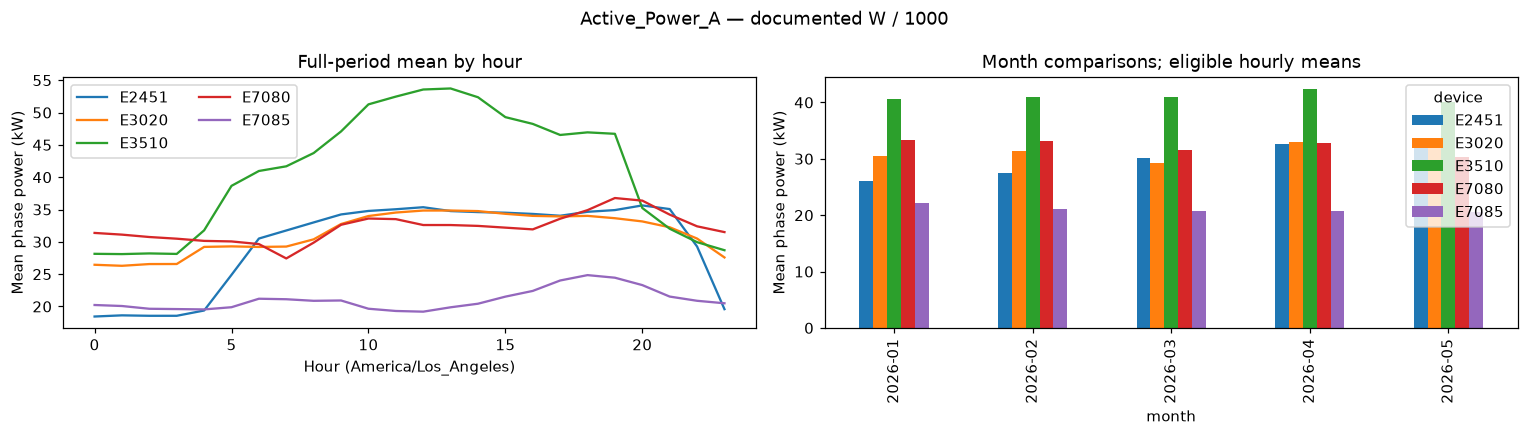

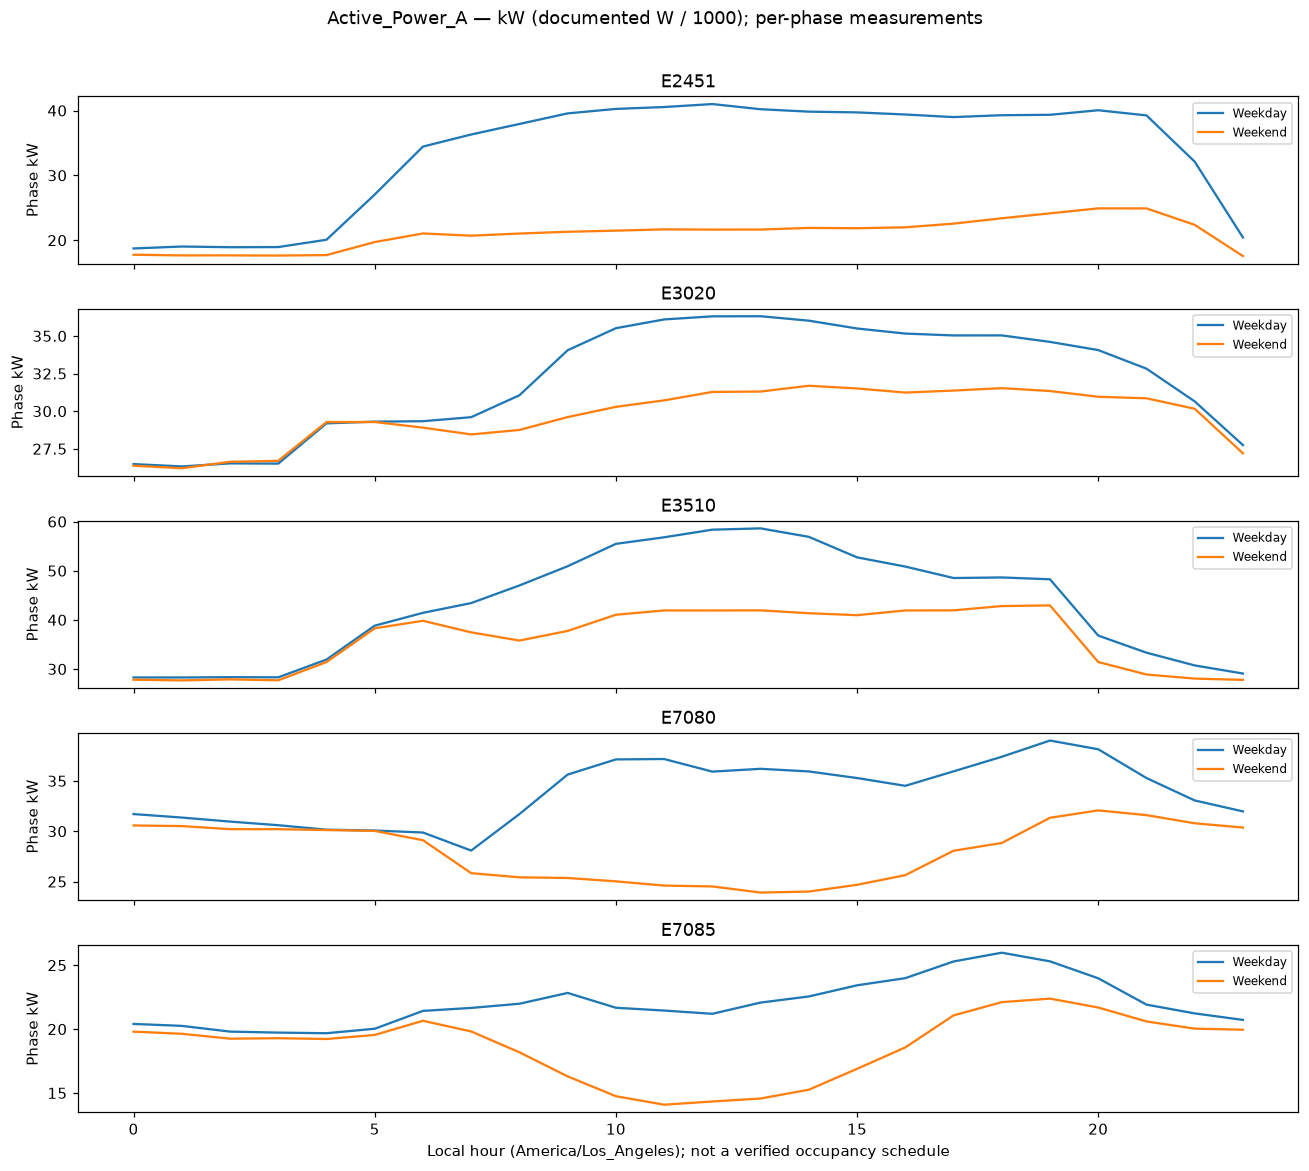

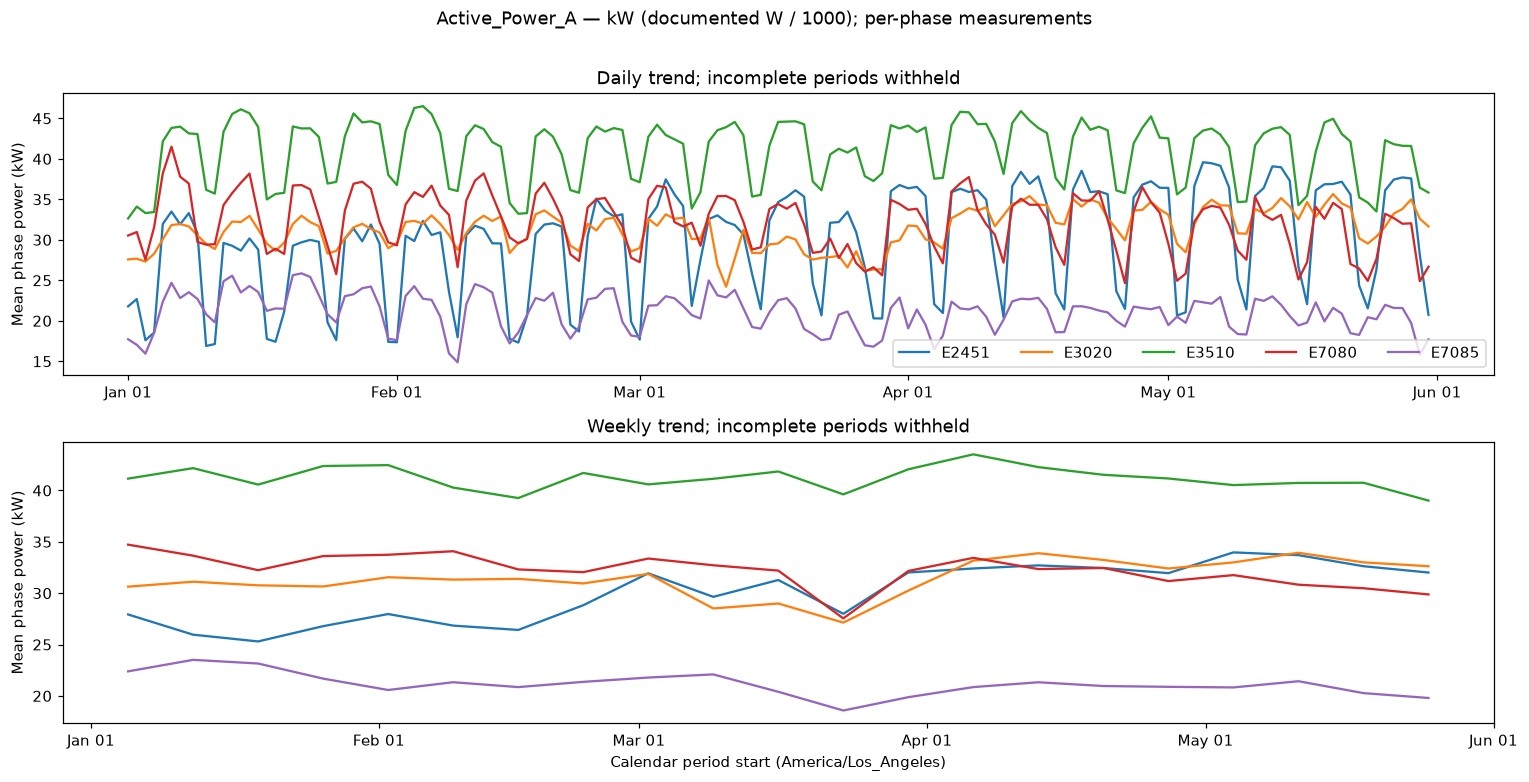

In [27]:
if HL_TABLES is not None:
    hours = HL_TABLES['hours'].query('channel == @HL_POWER_CHANNEL')
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for device, group in hours.groupby('device'):
        profile = group.groupby('hour').mean_kw.mean().reindex(range(24))
        axes[0].plot(profile.index, profile, label=device)
    axes[0].set(xlabel=f'Hour ({HL_TZ})', ylabel='Mean phase power (kW)', title='Full-period mean by hour')
    axes[0].legend(ncol=2)
    monthly = HL_TABLES['monthly'].query('channel == @HL_POWER_CHANNEL')
    monthly.pivot(index='month', columns='device', values='mean_kw').plot.bar(ax=axes[1])
    axes[1].set(ylabel='Mean phase power (kW)', title='Month comparisons; eligible hourly means')
    fig.suptitle(HL_POWER_CHANNEL + ' — documented W / 1000'); plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(len(HL_DEVICES), 1, figsize=(12, 2.1*len(HL_DEVICES)), sharex=True, squeeze=False)
    fig.suptitle(HL_POWER_CHANNEL+' — kW (documented W / 1000); per-phase measurements', y=1.01)
    for ax, device in zip(axes[:, 0], HL_DEVICES):
        profile = HL_TABLES['profiles'].query('device == @device and channel == @HL_POWER_CHANNEL')
        for weekend, label in [(False, 'Weekday'), (True, 'Weekend')]:
            part = profile.loc[profile.weekend.eq(weekend)].set_index('hour').reindex(range(24))
            ax.plot(part.index, part.mean_kw, label=label)
        ax.set(title=device, ylabel='Phase kW'); ax.legend(fontsize=8)
    axes[-1, 0].set_xlabel(f'Local hour ({HL_TZ}); not a verified occupancy schedule')
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(2, 1, figsize=(14, 7))
    fig.suptitle(HL_POWER_CHANNEL+' — kW (documented W / 1000); per-phase measurements', y=1.01)
    for device in HL_DEVICES:
        for ax, name, key in [(axes[0], 'daily', 'local_day'), (axes[1], 'weekly', 'week')]:
            part = HL_TABLES[name].query('device == @device and channel == @HL_POWER_CHANNEL')
            ax.plot(part[key], part.mean_kw, label=device)
            ax.set(ylabel='Mean phase power (kW)', title=name.capitalize() + ' trend; incomplete periods withheld')
    axes[0].legend(ncol=5); axes[-1].set_xlabel(f'Calendar period start ({HL_TZ})')
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=ZoneInfo(HL_TZ)))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    plt.tight_layout(); plt.show()

In [16]:
if HL_TABLES is not None:
    focus = HL_TABLES['hours'].query('channel == @HL_POWER_CHANNEL')
    means = focus.groupby(['device', 'weekend']).mean_kw.mean().unstack().reindex(columns=[False, True])
    means.columns = ['weekday_mean_kw', 'weekend_mean_kw']
    means['weekend_minus_weekday_kw'] = means.weekend_mean_kw - means.weekday_mean_kw
    counts = focus.groupby(['device', 'weekend']).mean_kw.count().unstack().reindex(columns=[False, True])
    counts.columns = ['weekday_valid_hours', 'weekend_valid_hours']
    display(means.join(counts))
    monthly = HL_TABLES['monthly'].query('channel == @HL_POWER_CHANNEL')
    paired_means = means[['weekday_mean_kw','weekend_mean_kw']].dropna()
    lower_weekends = int((paired_means.weekend_mean_kw < paired_means.weekday_mean_kw).sum())
    statements = [f'Weekend mean phase power is lower than weekday mean at {lower_weekends}/{len(paired_means)} meters with both day types represented.']
    for device in HL_DEVICES:
        part = monthly.loc[monthly.device.eq(device)].dropna(subset=['mean_kw'])
        if not part.empty:
            highest, lowest = part.loc[part.mean_kw.idxmax()], part.loc[part.mean_kw.idxmin()]
            statements.append(f'{device}: largest observed monthly mean in {highest.month}; smallest in {lowest.month}.')
    display(Markdown('**H — Computed findings (' + HL_POWER_CHANNEL + ').** ' + ' '.join(statements) +
        ' The signed weekday/weekend contrasts above describe the observed calendar, without establishing an occupancy cause. '
        'Daily/weekly lines support the existing Buildings daily-profile and historical-comparison views; monthly comparisons '
        'help choose comparison periods. These phase-specific values cannot yet populate building electricity-use totals.'))

,weekday_mean_kw,weekend_mean_kw,weekend_minus_weekday_kw,weekday_valid_hours,weekend_valid_hours
device,,,,,
E2451,33.386853,21.010376,-12.376477,2558,1055
E3020,32.045323,29.655074,-2.390248,2562,1055
E3510,42.973760,36.110777,-6.862983,2562,1055
E7080,33.876932,28.033766,-5.843166,2562,1055
E7085,22.015863,18.664319,-3.351543,2562,1055


**H — Computed findings (Active_Power_A).** Weekend mean phase power is lower than weekday mean at 5/5 meters with both day types represented. E2451: largest observed monthly mean in 2026-04; smallest in 2026-01. E3020: largest observed monthly mean in 2026-04; smallest in 2026-03. E3510: largest observed monthly mean in 2026-04; smallest in 2026-05. E7080: largest observed monthly mean in 2026-01; smallest in 2026-05. E7085: largest observed monthly mean in 2026-01; smallest in 2026-05. The signed weekday/weekend contrasts above describe the observed calendar, without establishing an occupancy cause. Daily/weekly lines support the existing Buildings daily-profile and historical-comparison views; monthly comparisons help choose comparison periods. These phase-specific values cannot yet populate building electricity-use totals.

## I — Power Distribution and Peak Demand Analysis

The single additional pass below computes accepted-row min/max/mean/population standard deviation and **bounded raw median/p95**. Deterministic equal-width 4,096-bin histograms use F's device/register range; tables report the interval containing the inverse-empirical-CDF quantile. Bounds can be wide when extremes stretch the range; increase bins if necessary. They are not exact pandas-interpolated raw quantiles or a sample of the raw data. Exact quantiles of eligible 15-minute means are reported separately. Source changed outside F's ranges causes an error requiring F to rerun.

Raw statistics exclude F's duplicate five-minute bins and invalid time/ID/source-month rows but include finite observations in low-coverage bins. Aggregate statistics use F's coverage rule; these are explicitly **different populations**, so their ratio is not an unbiased peak-reduction estimate. G already measured smoothing across resolutions; I instead compares distributions, calendar maxima and peak timing. Daily/monthly raw peaks are **highest recorded observations**, not guaranteed physical, tariff/billing or complete-period peaks. No high value is labeled anomalous. Tied raw daily maxima use the earliest UTC timestamp; 15-minute peaks use interval starts, not instantaneous times. Peak-hour counts include every observed daily peak, including incomplete days; inspect coverage alongside them.

In [17]:
HL_EXTRA = None
if HL_READY:
    if FG_DATA_PATH is None or not Path(FG_DATA_PATH).is_file():
        print('I/J raw electrical summaries unavailable: local archive missing; H/K can still reuse live F summaries.')
    else:
        HL_EXTRA = scan_measurements(FG_DATA_PATH, FULL_RESULT, chunksize=HL_CHUNK_ROWS,
                                     histogram_bins=HL_HISTOGRAM_BINS)
        print('Supplemental scan provenance:', HL_EXTRA['metadata'])
        HL_RAW_POWER, HL_BIN_POWER = distribution_tables(FULL_RESULT, HL_EXTRA)
        print('Raw accepted observations — min/max/mean/std exact; median/p95 bounded (kW):')
        display(HL_RAW_POWER[['device', 'register', 'finite_rows', 'min_kw', 'max_kw', 'mean_kw',
                             'median_low_kw', 'median_high_kw', 'p95_low_kw', 'p95_high_kw', 'std_kw']])
        print('Eligible 15-minute means — exact descriptive quantiles; not raw readings:')
        display(HL_BIN_POWER)

Additional electrical/statistics scan: E2451 2026-01 EOF (1 CSVs)
Additional electrical/statistics scan: E2451 2026-02 EOF (2 CSVs)
Additional electrical/statistics scan: E2451 2026-03 EOF (3 CSVs)
Additional electrical/statistics scan: E2451 2026-04 EOF (4 CSVs)
Additional electrical/statistics scan: E2451 2026-05 EOF (5 CSVs)
Additional electrical/statistics scan: E3020 2026-01 EOF (6 CSVs)
Additional electrical/statistics scan: E3020 2026-02 EOF (7 CSVs)
Additional electrical/statistics scan: E3020 2026-03 EOF (8 CSVs)
Additional electrical/statistics scan: E3020 2026-04 EOF (9 CSVs)
Additional electrical/statistics scan: E3020 2026-05 EOF (10 CSVs)
Additional electrical/statistics scan: E3510 2026-01 EOF (11 CSVs)
Additional electrical/statistics scan: E3510 2026-02 EOF (12 CSVs)
Additional electrical/statistics scan: E3510 2026-03 EOF (13 CSVs)
Additional electrical/statistics scan: E3510 2026-04 EOF (14 CSVs)
Additional electrical/statistics scan: E3510 2026-05 EOF (15 CSVs)
Addi

,device,register,finite_rows,min_kw,max_kw,mean_kw,median_low_kw,median_high_kw,p95_low_kw,p95_high_kw,std_kw
0,E2451,Active_Power_A,6510701,12.875011,69.864422,29.786220,29.111984,29.125898,44.848074,44.861987,10.429748
1,E2451,Active_Power_B,6510701,10.730782,65.623492,25.216395,24.172527,24.185929,39.235859,39.249260,9.518788
2,E2451,Active_Power_C,6510701,10.272666,63.995566,24.991494,24.477232,24.490348,38.130928,38.144044,9.178371
25,E3020,Active_Power_A,6517403,16.403768,67.963297,31.353901,30.275496,30.288084,39.867381,39.879969,5.015341
26,E3020,Active_Power_B,6517403,16.424309,73.363703,34.903812,35.204856,35.218757,43.531686,43.545588,5.657470
27,E3020,Active_Power_C,6517403,13.739629,64.548277,28.280510,27.520979,27.533383,35.025674,35.038078,4.041849
50,E3510,Active_Power_A,6517397,22.956787,94.790328,40.984027,39.897998,39.915536,61.206043,61.223581,11.405217
51,E3510,Active_Power_B,6517397,13.979438,84.311023,32.225656,31.133065,31.150236,52.991490,53.008660,12.028125
52,E3510,Active_Power_C,6517397,18.909840,88.943711,40.122847,40.214089,40.231187,57.466085,57.483183,9.995089
75,E7080,Active_Power_A,6517368,15.326229,77.225437,32.176747,31.481077,31.496189,43.147626,43.162739,6.132916


Eligible 15-minute means — exact descriptive quantiles; not raw readings:


,device,channel,eligible_bins,min_kw,max_kw,mean_kw,median_kw,p95_kw,std_kw,iqr_kw
0,E2451,Active_Power_A,14465,13.520523,49.289054,29.783591,29.129752,45.015952,10.318825,19.176623
1,E2451,Active_Power_B,14465,10.885909,44.448402,25.214181,24.178941,39.247616,9.391204,17.591072
2,E2451,Active_Power_C,14465,10.409816,43.432575,24.989841,24.447232,38.294988,9.049595,16.555422
3,E3020,Active_Power_A,14478,16.957580,45.116129,31.351892,30.469946,39.089911,4.369660,6.400467
4,E3020,Active_Power_B,14478,17.221241,49.789901,34.901955,35.428325,42.429855,5.005983,5.931911
5,E3020,Active_Power_C,14478,14.611479,40.549011,28.279491,27.774140,33.982682,3.091609,3.767196
6,E3510,Active_Power_A,14479,24.655872,69.457271,40.981145,40.182365,59.886137,10.844106,19.643424
7,E3510,Active_Power_B,14479,16.257559,60.381014,32.222994,31.395850,52.068034,11.544468,21.528716
8,E3510,Active_Power_C,14479,20.726585,63.988872,40.120379,40.618422,55.760060,9.380584,17.541051
9,E7080,Active_Power_A,14480,16.763238,53.302815,32.175485,31.549626,42.673016,5.852147,6.821905


Monthly highest recorded raw observations (all phases; exact source instants):


,device,channel,local_day,observed_peak_kw,peak_utc,peak_local,peak_local_hour,month,timestamp_day_coverage_pct
21,E2451,Active_Power_A,2026-01-08,64.203004,2026-01-08 19:01:00.245975+00:00,2026-01-08 11:01:00.245975-08:00,11,2026-01,99.986111
144,E2451,Active_Power_A,2026-02-18,62.753531,2026-02-18 20:07:19.208064+00:00,2026-02-18 12:07:19.208064-08:00,12,2026-02,99.965278
186,E2451,Active_Power_A,2026-03-04,65.825039,2026-03-04 20:48:33.906839+00:00,2026-03-04 12:48:33.906839-08:00,12,2026-03,99.916667
312,E2451,Active_Power_A,2026-04-15,68.209703,2026-04-15 16:51:56.048784+00:00,2026-04-15 09:51:56.048784-07:00,9,2026-04,99.969907
375,E2451,Active_Power_A,2026-05-06,69.864422,2026-05-06 20:48:28.708645+00:00,2026-05-06 13:48:28.708645-07:00,13,2026-05,99.997685
...,...,...,...,...,...,...,...,...,...
1835,E7085,Active_Power_C,2026-01-08,52.203289,2026-01-09 01:00:25.088804+00:00,2026-01-08 17:00:25.088804-08:00,17,2026-01,99.662037
1961,E7085,Active_Power_C,2026-02-19,52.516703,2026-02-19 21:58:20.761953+00:00,2026-02-19 13:58:20.761953-08:00,13,2026-02,99.770833
2000,E7085,Active_Power_C,2026-03-04,52.300363,2026-03-04 17:28:45.673894+00:00,2026-03-04 09:28:45.673894-08:00,9,2026-03,99.807870
2099,E7085,Active_Power_C,2026-04-06,51.780031,2026-04-06 17:03:45.937891+00:00,2026-04-06 10:03:45.937891-07:00,10,2026-04,99.835648


Daily peaks retained in HL_DAILY_PEAKS, including coverage. First 15 rows:


,device,channel,local_day,observed_peak_kw,peak_utc,peak_local,peak_local_hour,month,timestamp_day_coverage_pct
0,E2451,Active_Power_A,2026-01-01,34.843664,2026-01-01 22:35:37.983484+00:00,2026-01-01 14:35:37.983484-08:00,14,2026-01,99.983796
1,E2451,Active_Power_B,2026-01-01,33.637469,2026-01-01 22:35:31.981937+00:00,2026-01-01 14:35:31.981937-08:00,14,2026-01,99.983796
2,E2451,Active_Power_C,2026-01-01,33.024973,2026-01-01 22:35:35.983164+00:00,2026-01-01 14:35:35.983164-08:00,14,2026-01,99.983796
3,E2451,Active_Power_A,2026-01-02,42.841766,2026-01-03 03:32:55.421514+00:00,2026-01-02 19:32:55.421514-08:00,19,2026-01,99.974537
4,E2451,Active_Power_B,2026-01-02,40.468125,2026-01-03 03:32:55.421514+00:00,2026-01-02 19:32:55.421514-08:00,19,2026-01,99.974537
5,E2451,Active_Power_C,2026-01-02,41.247020,2026-01-03 03:32:55.421514+00:00,2026-01-02 19:32:55.421514-08:00,19,2026-01,99.974537
6,E2451,Active_Power_A,2026-01-03,30.013082,2026-01-03 22:51:05.945062+00:00,2026-01-03 14:51:05.945062-08:00,14,2026-01,99.967593
7,E2451,Active_Power_B,2026-01-03,28.566006,2026-01-03 22:51:05.945062+00:00,2026-01-03 14:51:05.945062-08:00,14,2026-01,99.967593
8,E2451,Active_Power_C,2026-01-03,30.583799,2026-01-03 22:51:05.945062+00:00,2026-01-03 14:51:05.945062-08:00,14,2026-01,99.967593
9,E2451,Active_Power_A,2026-01-04,34.716754,2026-01-05 02:04:45.244780+00:00,2026-01-04 18:04:45.244780-08:00,18,2026-01,99.993056


Daily raw observation versus sustained interval peak (different coverage-selected populations):


,device,channel,local_day,observed_peak_kw,peak_utc,peak_local,peak_local_hour,month,timestamp_day_coverage_pct,maximum_15min_mean_kw,interval_start_utc,eligible_15min_bins,expected_15min_bins,observed_minus_interval_peak_kw
0,E2451,Active_Power_A,2026-01-01,34.843664,2026-01-01 22:35:37.983484+00:00,2026-01-01 14:35:37.983484-08:00,14,2026-01,99.983796,26.439606,2026-01-01 15:15:00+00:00,96,96,8.404058
1,E2451,Active_Power_A,2026-01-02,42.841766,2026-01-03 03:32:55.421514+00:00,2026-01-02 19:32:55.421514-08:00,19,2026-01,99.974537,31.024115,2026-01-03 03:15:00+00:00,96,96,11.817651
2,E2451,Active_Power_A,2026-01-03,30.013082,2026-01-03 22:51:05.945062+00:00,2026-01-03 14:51:05.945062-08:00,14,2026-01,99.967593,21.061026,2026-01-04 06:00:00+00:00,96,96,8.952056
3,E2451,Active_Power_A,2026-01-04,34.716754,2026-01-05 02:04:45.244780+00:00,2026-01-04 18:04:45.244780-08:00,18,2026-01,99.993056,23.534888,2026-01-05 04:30:00+00:00,96,96,11.181866
4,E2451,Active_Power_A,2026-01-05,60.178559,2026-01-05 22:56:53.811524+00:00,2026-01-05 14:56:53.811524-08:00,14,2026-01,99.979167,41.937642,2026-01-05 19:45:00+00:00,96,96,18.240917
5,E2451,Active_Power_A,2026-01-06,60.474723,2026-01-06 18:45:38.495442+00:00,2026-01-06 10:45:38.495442-08:00,10,2026-01,99.951389,42.900528,2026-01-06 18:45:00+00:00,96,96,17.574195
6,E2451,Active_Power_A,2026-01-07,59.162516,2026-01-07 23:52:30.034034+00:00,2026-01-07 15:52:30.034034-08:00,15,2026-01,99.990741,40.710298,2026-01-07 19:30:00+00:00,96,96,18.452218
7,E2451,Active_Power_A,2026-01-08,64.203004,2026-01-08 19:01:00.245975+00:00,2026-01-08 11:01:00.245975-08:00,11,2026-01,99.986111,43.677541,2026-01-08 18:45:00+00:00,96,96,20.525463
8,E2451,Active_Power_A,2026-01-09,56.230848,2026-01-09 18:57:45.180609+00:00,2026-01-09 10:57:45.180609-08:00,10,2026-01,99.951389,39.875069,2026-01-09 18:45:00+00:00,96,96,16.355779
9,E2451,Active_Power_A,2026-01-10,29.588479,2026-01-11 02:58:29.061366+00:00,2026-01-10 18:58:29.061366-08:00,18,2026-01,99.997685,19.698875,2026-01-11 05:00:00+00:00,96,96,9.889604


Monthly max raw reading versus max eligible 15-minute mean; not tariff demand:


observed_peak_kw  maximum_15min_mean_kw
device channel        month                                           
E2451  Active_Power_A 2026-01         64.203004              43.677541
                      2026-02         62.753531              43.602411
                      2026-03         65.825039              46.437247
                      2026-04         68.209703              48.653496
                      2026-05         69.864422              49.289054
...                                         ...                    ...
E7085  Active_Power_C 2026-01         52.203289              30.175555
                      2026-02         52.516703              30.219355
                      2026-03         52.300363              29.434978
                      2026-04         51.780031              29.641007
                      2026-05         50.913434              29.917820

[75 rows x 2 columns]

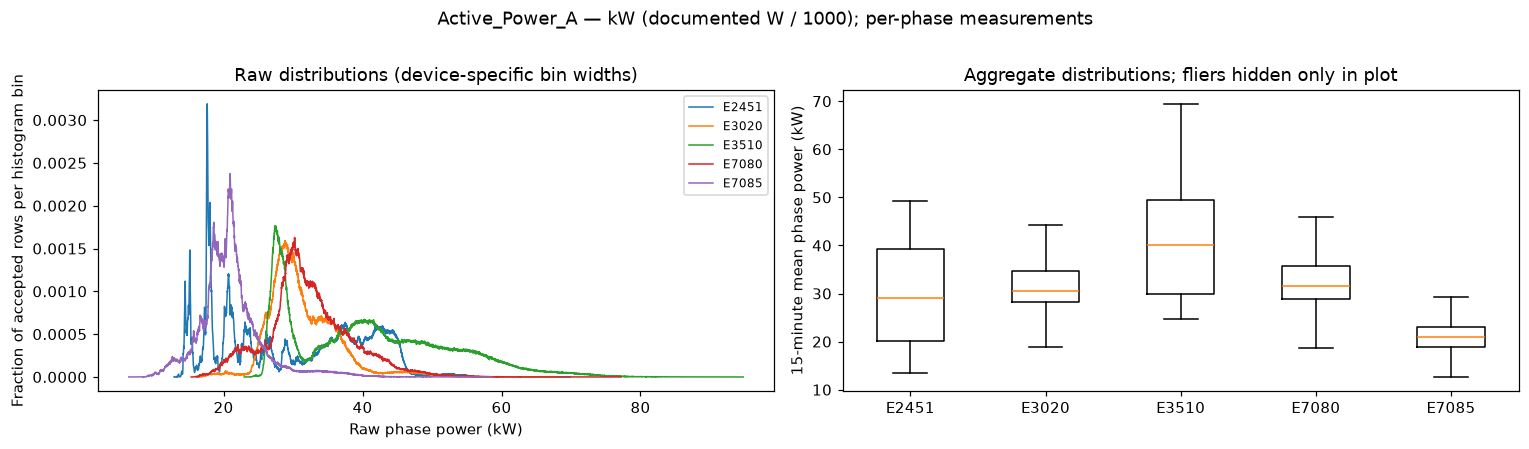

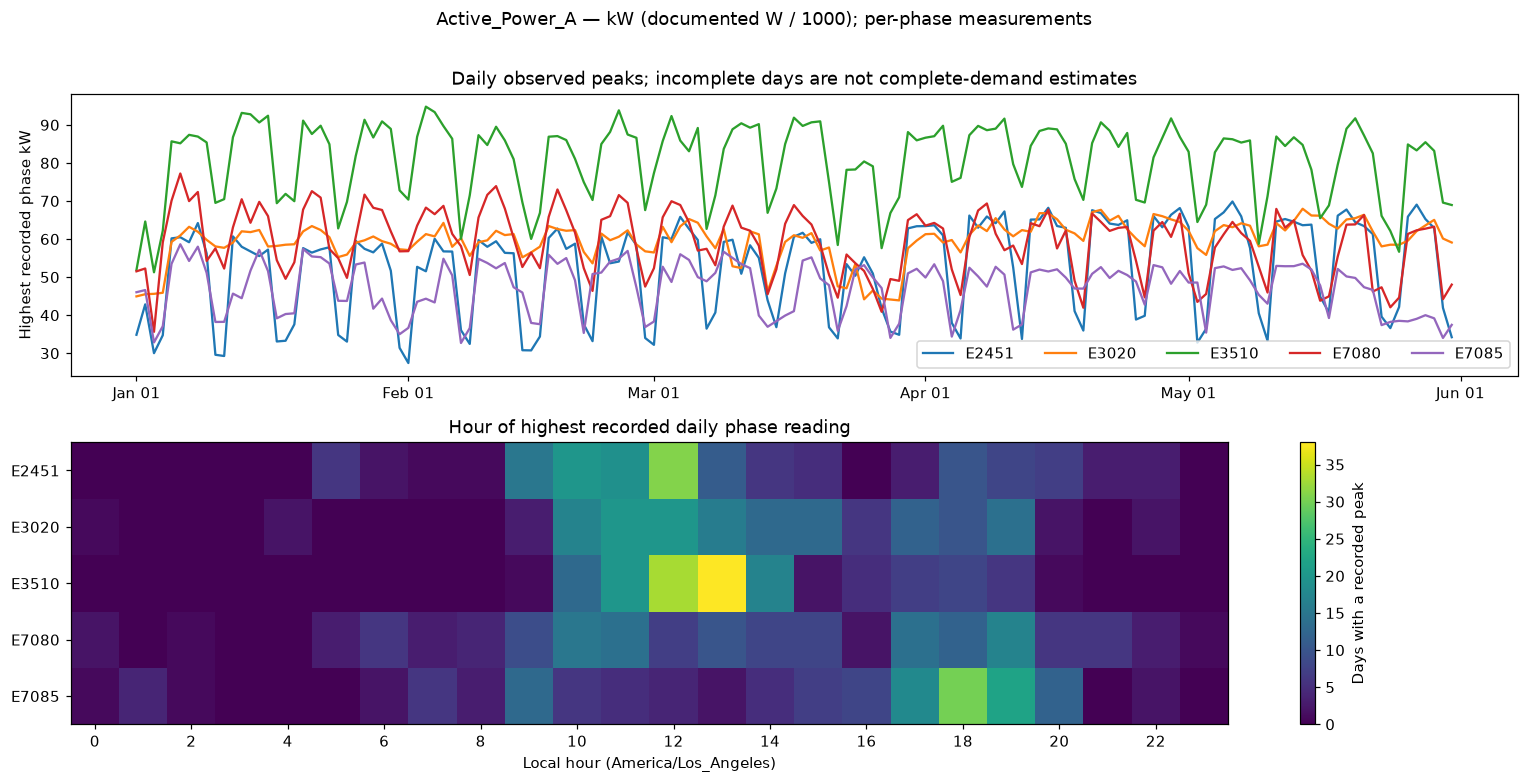

**I — Computed findings (Active_Power_A).** E2451: maximum recorded 69.86 kW; maximum eligible 15-minute mean 49.29 kW; most frequent local daily-peak hour(s) 12:00. E3020: maximum recorded 67.96 kW; maximum eligible 15-minute mean 45.12 kW; most frequent local daily-peak hour(s) 11:00, 12:00. E3510: maximum recorded 94.79 kW; maximum eligible 15-minute mean 69.46 kW; most frequent local daily-peak hour(s) 13:00. E7080: maximum recorded 77.23 kW; maximum eligible 15-minute mean 53.30 kW; most frequent local daily-peak hour(s) 19:00. E7085: maximum recorded 58.63 kW; maximum eligible 15-minute mean 35.24 kW; most frequent local daily-peak hour(s) 18:00.

**I — Interpretation.** The raw and aggregate tables separate momentary observations from sustained 15-minute demand. Raw peak timestamps support the measured part of Buildings → Peak demand analysis; histogram and boxplot summaries inform axis ranges and descriptive statistics, but the application currently has no power-distribution panel. Historical maxima can be compared without forecasts; the current normal-peak threshold, expected trace and event markers cannot be carried over. Variability (standard deviation/IQR) is descriptive, not fault evidence.

In [28]:
if HL_EXTRA is not None:
    HL_DAILY_PEAKS = HL_EXTRA['daily_peaks'].copy()
    if len(HL_DAILY_PEAKS):
        # Attach F's full-day timestamp-slot availability; not finite-channel coverage.
        coverage = FULL_RESULT['daily'].rename(columns={'date': 'local_day', 'coverage_pct': 'timestamp_day_coverage_pct'})
        HL_DAILY_PEAKS = HL_DAILY_PEAKS.merge(coverage[['device', 'local_day', 'timestamp_day_coverage_pct']],
                                             on=['device', 'local_day'], validate='many_to_one')
        HL_MONTHLY_PEAKS = HL_DAILY_PEAKS.sort_values(['observed_peak_kw', 'peak_utc'], ascending=[False, True]).drop_duplicates(['device', 'channel', 'month'])
        print('Monthly highest recorded raw observations (all phases; exact source instants):')
        display(HL_MONTHLY_PEAKS.sort_values(['device', 'channel', 'month']))
        print('Daily peaks retained in HL_DAILY_PEAKS, including coverage. First 15 rows:')
        display(HL_DAILY_PEAKS.head(15))

    interval_peaks = []
    for (device, minutes), bins in FULL_RESULT['aggregates'].items():
        if minutes != 15: continue
        local_days = bins.index.tz_convert(HL_TZ).strftime('%Y-%m-%d')
        for channel in FULL_RESULT['channels']:
            values = bins[channel+'__mean_kw']
            for day, group in values.groupby(local_days):
                valid = group.dropna()
                if len(valid):
                    interval_peaks.append(dict(device=device, channel=channel, local_day=day,
                        maximum_15min_mean_kw=valid.max(), interval_start_utc=valid.idxmax(),
                        eligible_15min_bins=len(valid), expected_15min_bins=len(group)))
    HL_INTERVAL_PEAKS = pd.DataFrame(interval_peaks, columns=['device', 'channel', 'local_day',
        'maximum_15min_mean_kw', 'interval_start_utc', 'eligible_15min_bins', 'expected_15min_bins'])
    HL_PEAK_COMPARISON = HL_DAILY_PEAKS.merge(HL_INTERVAL_PEAKS, on=['device','channel','local_day'], how='outer', validate='one_to_one')
    HL_PEAK_COMPARISON['observed_minus_interval_peak_kw'] = HL_PEAK_COMPARISON.observed_peak_kw - HL_PEAK_COMPARISON.maximum_15min_mean_kw
    print('Daily raw observation versus sustained interval peak (different coverage-selected populations):')
    display(HL_PEAK_COMPARISON.head(15))
    print('Monthly max raw reading versus max eligible 15-minute mean; not tariff demand:')
    HL_PEAK_COMPARISON['month'] = HL_PEAK_COMPARISON.local_day.str[:7]
    display(HL_PEAK_COMPARISON.groupby(['device','channel','month'])[
        ['observed_peak_kw','maximum_15min_mean_kw']].max())

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(HL_POWER_CHANNEL+' — kW (documented W / 1000); per-phase measurements', y=1.01)
    boxdata, labels = [], []
    for device in HL_DEVICES:
        frame = FULL_RESULT['aggregates'][(device, 15)]
        values = frame[HL_POWER_CHANNEL+'__mean_kw'].dropna()
        if len(values): boxdata.append(values.to_numpy()); labels.append(device)
        hist, low, high = HL_EXTRA['histograms'][(device, HL_POWER_CHANNEL)]
        if hist.sum():
            centers = (low + (np.arange(len(hist))+.5)*(high-low)/len(hist))/1000
            axes[0].plot(centers, hist/hist.sum(), label=device, linewidth=1)
    axes[0].set(xlabel='Raw phase power (kW)', ylabel='Fraction of accepted rows per histogram bin', title='Raw distributions (device-specific bin widths)')
    if axes[0].get_legend_handles_labels()[0]: axes[0].legend(fontsize=8)
    else: axes[0].text(.5,.5,'Unavailable: no accepted finite values',ha='center',transform=axes[0].transAxes)
    if boxdata: axes[1].boxplot(boxdata, tick_labels=labels, showfliers=False)
    axes[1].set(ylabel='15-minute mean phase power (kW)', title='Aggregate distributions; fliers hidden only in plot')
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(2, 1, figsize=(14, 7))
    fig.suptitle(HL_POWER_CHANNEL+' — kW (documented W / 1000); per-phase measurements', y=1.01)
    for device in HL_DEVICES:
        part = HL_DAILY_PEAKS.query('device == @device and channel == @HL_POWER_CHANNEL')
        # Reindex to the full calendar so missing days break the line.
        calendar = HL_TABLES['daily'].query('device == @device and channel == @HL_POWER_CHANNEL')
        days = calendar.local_day.dt.strftime('%Y-%m-%d')
        series = part.set_index('local_day').observed_peak_kw.reindex(days)
        axes[0].plot(calendar.local_day, series.to_numpy(), label=device)
    axes[0].set(ylabel='Highest recorded phase kW', title='Daily observed peaks; incomplete days are not complete-demand estimates')
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=ZoneInfo(HL_TZ)))
    axes[0].legend(ncol=5)
    part = HL_DAILY_PEAKS.query('channel == @HL_POWER_CHANNEL')
    hours = pd.crosstab(part.device, part.peak_local_hour).reindex(index=HL_DEVICES, columns=range(24), fill_value=0)
    im = axes[1].imshow(hours, aspect='auto', interpolation='nearest')
    axes[1].set(yticks=range(len(HL_DEVICES)), yticklabels=HL_DEVICES, xticks=range(0,24,2),
                xticklabels=range(0,24,2), xlabel=f'Local hour ({HL_TZ})', title='Hour of highest recorded daily phase reading')
    fig.colorbar(im, ax=axes[1], label='Days with a recorded peak')
    plt.tight_layout(); plt.show()
    peak_findings = []
    for device in HL_DEVICES:
        observed = HL_RAW_POWER.query('device == @device and register == @HL_POWER_CHANNEL')
        averaged = HL_BIN_POWER.query('device == @device and channel == @HL_POWER_CHANNEL')
        daily = HL_DAILY_PEAKS.query('device == @device and channel == @HL_POWER_CHANNEL')
        if len(observed) and len(averaged) and len(daily):
            modes = ', '.join(str(int(h)).zfill(2)+':00' for h in daily.peak_local_hour.mode())
            peak_findings.append(f"{device}: maximum recorded {observed.iloc[0].max_kw:.2f} kW; "
                f"maximum eligible 15-minute mean {averaged.iloc[0].max_kw:.2f} kW; "
                f"most frequent local daily-peak hour(s) {modes}.")
    display(Markdown('**I — Computed findings ('+HL_POWER_CHANNEL+').** '+' '.join(peak_findings)))
    display(Markdown('**I — Interpretation.** The raw and aggregate tables separate momentary observations from sustained 15-minute demand. '
        'Raw peak timestamps support the measured part of Buildings → Peak demand analysis; histogram and boxplot summaries inform axis ranges '
        'and descriptive statistics, but the application currently has no power-distribution panel. '
        'Historical maxima can be compared without forecasts; the current normal-peak threshold, expected trace and event markers cannot be carried over. '
        'Variability (standard deviation/IQR) is descriptive, not fault evidence.'))

## J — Electrical Measurements and Phase Comparisons

D already tested sampled schema availability and F already counted full-file quality problems. J **reuses** those results, then adds accepted-row distributions, full-period 15-minute electrical traces and matched A/B/C comparisons. The F counters cover all source rows; the new finite statistics cover accepted rows outside duplicate bins. Different denominators are deliberately labeled. A missing field, no accepted finite values, whole-period constant, and only some constant months are distinct states; a constant channel may still be physically meaningful.

**Units are documented; engineering definitions remain separate:** `data/Meter Reading Mapping.csv` matches all 35 electrical register names in each of the 25 reviewed CSV headers. W, kWh, V, A, Hz, VA, VAR and % are documented tokens. PF is literally `--`; no ratio/percent or signed interpretation is inferred. The numerical helper agrees (its `dimensionless` PF label is only an alias for `--`).

| Exact registers | Documented units | Remaining engineering validation |
|---|---|---|
| `Active_Power_A/B/C` | W → kW | Signed import/export convention, phase wiring and whether phases are distinct/additive; no total without documented F phase review |
| `Voltage_A-N/B-N/C-N`; `Voltage_A-B/B-C/C-A` | V | RMS definition, line-neutral versus line-line wiring, nominal voltage, scale/calibration; do not combine the two groups |
| `Current_A/B/C` | A | RMS definition, CT ratios, phase order and calibration |
| `Frequency` | Hz | Measurement source, resolution and whether a stable value is quantization/default or actual readings |
| `Power_Factor_A/B/C` | `--` (no physical unit specified) | Numeric convention (ratio/percent is unspecified), sign convention, displacement versus true PF; retain signed values; no arithmetic sum across phases |
| `THD_Current_A/B/C/N`; `THD_Voltage_A-N/B-N/C-N` | % | No ratio-to-percent multiplication: use recorded percent values. THD-F versus THD-R, bandwidth/harmonic orders and instrument validity at low current |
| `Current_Unbalance_Worst`; `Voltage_Unbalance_L-N_Worst` | % | Definition, phase basis and averaging; a phase spread plot is not a standards-compliant unbalance calculation |

The mapping documents unit names, not measurement accuracy, CT/PT scaling, wiring, calibration or acceptable engineering limits. In particular, THD/unbalance numeric values are already in documented percent units: do not multiply by 100 or reclassify them as fractions based on magnitude. No manufacturer register manual, CT/PT documentation or validated limits were supplied locally. These are explicit missing inputs. Values are not clipped to a guessed PF, voltage, frequency or THD range and are not classified as faults. The 15-minute means/min/max are display statistics, not compliance power-quality measurements. Full-period figures below use documented units. The existing Buildings Power quality card is a placeholder, not a functioning measurement renderer; current/PF/THD need additional display development.

In [29]:
if HL_EXTRA is not None:
    q = FULL_RESULT['measurements'].query('register in @ELECTRICAL').copy()
    q['constant_month'] = q.finite.gt(0) & q['min'].eq(q['max'])
    HL_ELECTRICAL_AVAILABILITY = q.groupby(['device', 'register']).agg(
        source_rows=('rows', 'sum'), absent_column_rows=('absent_column_rows', 'sum'),
        source_missing_values=('missing', 'sum'), source_invalid_values=('invalid', 'sum'),
        source_finite_values=('finite', 'sum'), constant_months=('constant_month', 'sum')).reset_index()
    HL_ELECTRICAL_AVAILABILITY = HL_ELECTRICAL_AVAILABILITY.merge(
        HL_EXTRA['statistics'].query('register in @ELECTRICAL'), on=['device', 'register'], validate='one_to_one')
    def channel_state(row):
        if row.source_rows == 0: return 'No source rows'
        if row.absent_column_rows == row.source_rows: return 'Absent column'
        if row.finite_rows == 0: return 'No accepted finite observations'
        if row.constant: return 'Constant accepted values; review usability'
        if row.constant_months: return 'Variable overall; some constant months need review'
        return 'Variable; units documented; engineering validation pending'
    HL_ELECTRICAL_AVAILABILITY['documented_unit'] = HL_ELECTRICAL_AVAILABILITY.register.map(DOCUMENTED_UNITS)
    HL_ELECTRICAL_AVAILABILITY['unit_source'] = 'Meter Reading Mapping.csv'
    HL_ELECTRICAL_AVAILABILITY['review_state'] = HL_ELECTRICAL_AVAILABILITY.apply(channel_state, axis=1)
    print('All electrical channels; full table retained in HL_ELECTRICAL_AVAILABILITY:')
    display(HL_ELECTRICAL_AVAILABILITY)
    display(HL_ELECTRICAL_AVAILABILITY.groupby(['register', 'review_state']).device.agg(list).reset_index())
    print('No-register-data rows stay in the table; unavailable traces are skipped with a visible message.')

All electrical channels; full table retained in HL_ELECTRICAL_AVAILABILITY:


,device,register,source_rows,absent_column_rows,source_missing_values,source_invalid_values,source_finite_values,constant_months,mapped_unit,finite_rows,min,max,mean,std,median_low,median_high,p95_low,p95_high,constant,documented_unit,unit_source,review_state
0,E2451,Current_A,6510701,0,0,0,6510701,0,A,6510701,47.49739,332.48526,114.509062,40.626196,113.734805,113.804382,171.275081,171.344658,False,A,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
1,E2451,Current_B,6510701,0,0,0,6510701,0,A,6510701,39.38615,326.82205,101.058551,39.273980,100.157510,100.227684,156.718383,156.788557,False,A,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
2,E2451,Current_C,6510701,0,0,0,6510701,0,A,6510701,40.63369,329.56259,105.611433,37.964508,109.550569,109.621108,156.741349,156.811888,False,A,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
3,E2451,Current_Unbalance_Worst,6510701,0,0,0,6510701,0,%,6510701,0.00004,0.56419,0.100338,0.056776,0.088188,0.088326,0.207327,0.207464,False,%,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
4,E2451,Frequency,6510701,0,0,0,6510701,0,Hz,6510701,59.83461,60.07828,60.000192,0.017788,60.000586,60.000646,60.028725,60.028785,False,Hz,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,E7085,Voltage_B-C,6517345,0,0,0,6517345,0,V,6517345,474.67450,497.75406,490.252741,2.897789,490.209253,490.214887,494.908558,494.914192,False,V,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
106,E7085,Voltage_B-N,6517345,0,0,0,6517345,0,V,6517345,273.61346,287.11331,282.824198,1.668629,282.805619,282.808914,285.504929,285.508225,False,V,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
107,E7085,Voltage_C-A,6517345,0,0,0,6517345,0,V,6517345,474.26245,497.40259,490.069423,2.921490,490.013112,490.018761,494.736050,494.741700,False,V,Meter Reading Mapping.csv,Variable; units documented; engineering valida...
108,E7085,Voltage_C-N,6517345,0,0,0,6517345,0,V,6517345,274.16611,287.36975,283.125975,1.681151,283.095329,283.098553,285.819225,285.822448,False,V,Meter Reading Mapping.csv,Variable; units documented; engineering valida...


,register,review_state,device
0,Current_A,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
1,Current_B,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
2,Current_C,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
3,Current_Unbalance_Worst,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
4,Frequency,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
5,Power_Factor_A,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
6,Power_Factor_B,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
7,Power_Factor_C,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
8,THD_Current_A,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"
9,THD_Current_B,Variable; units documented; engineering valida...,"[E2451, E3020, E3510, E7080, E7085]"


No-register-data rows stay in the table; unavailable traces are skipped with a visible message.


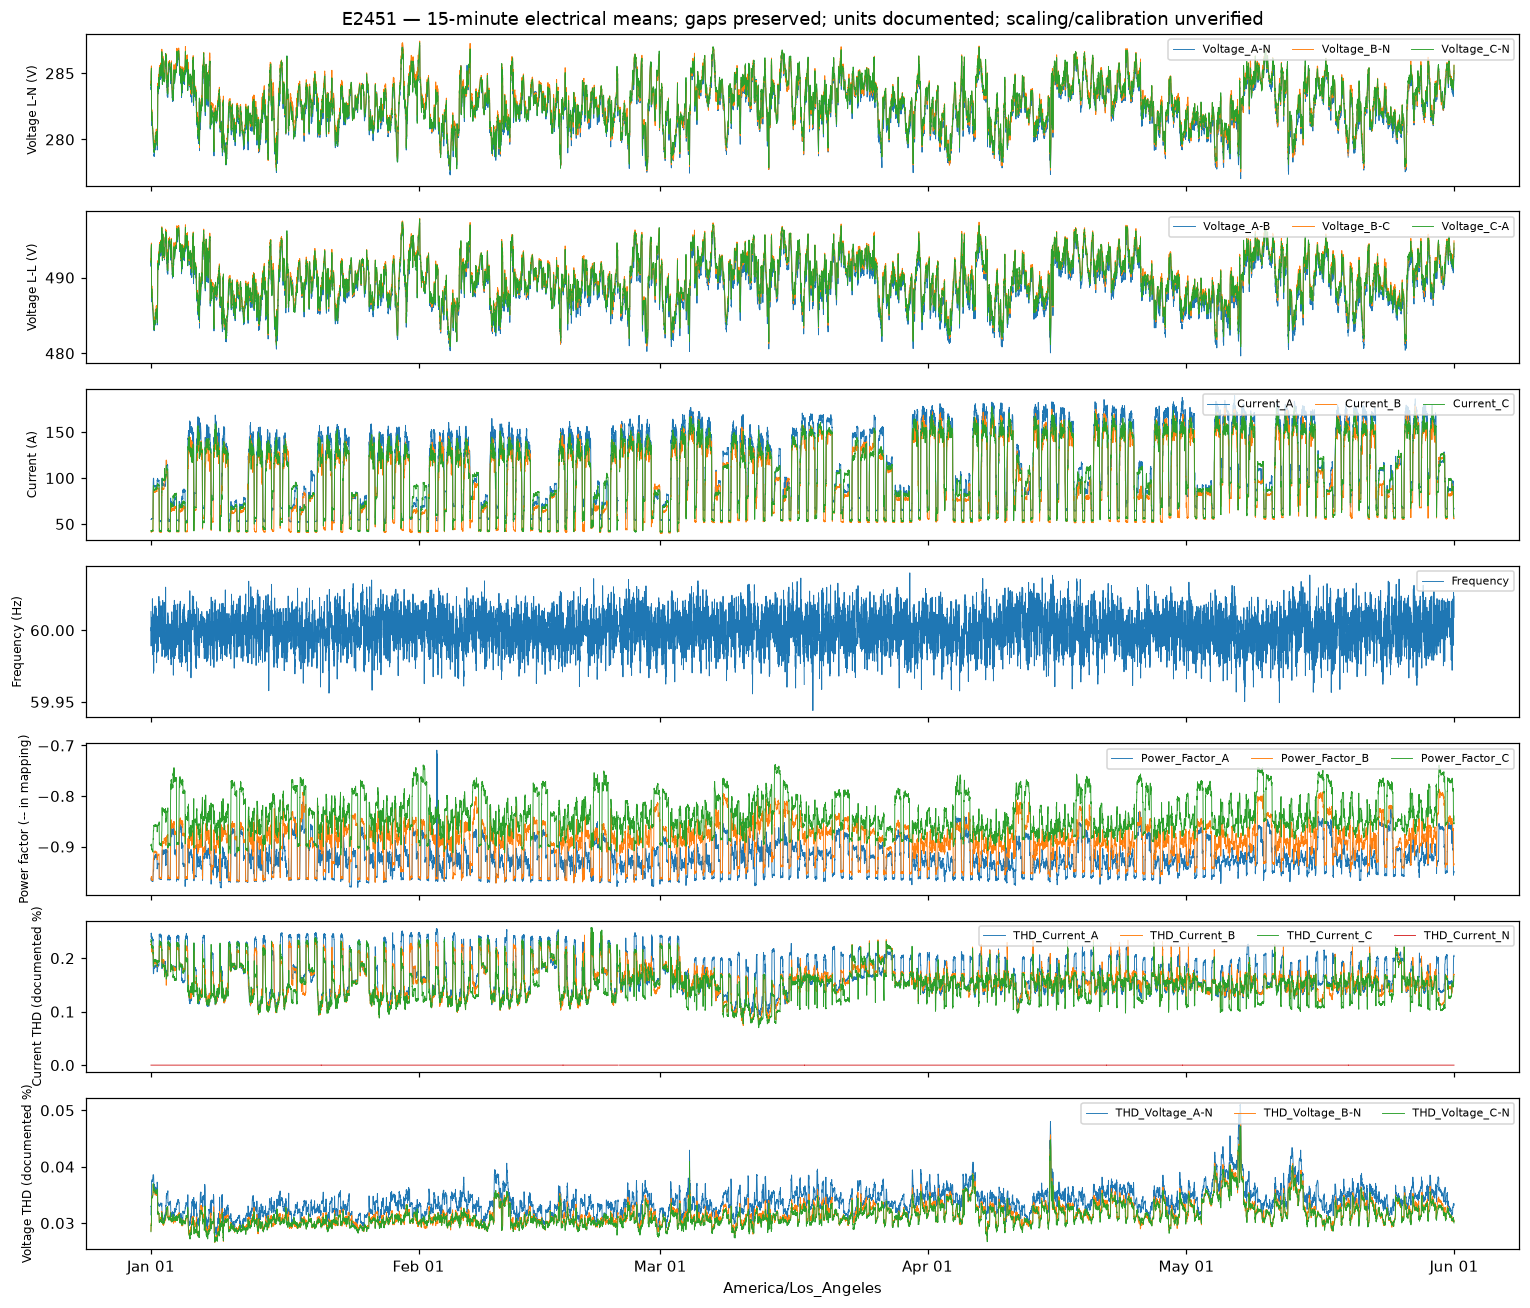

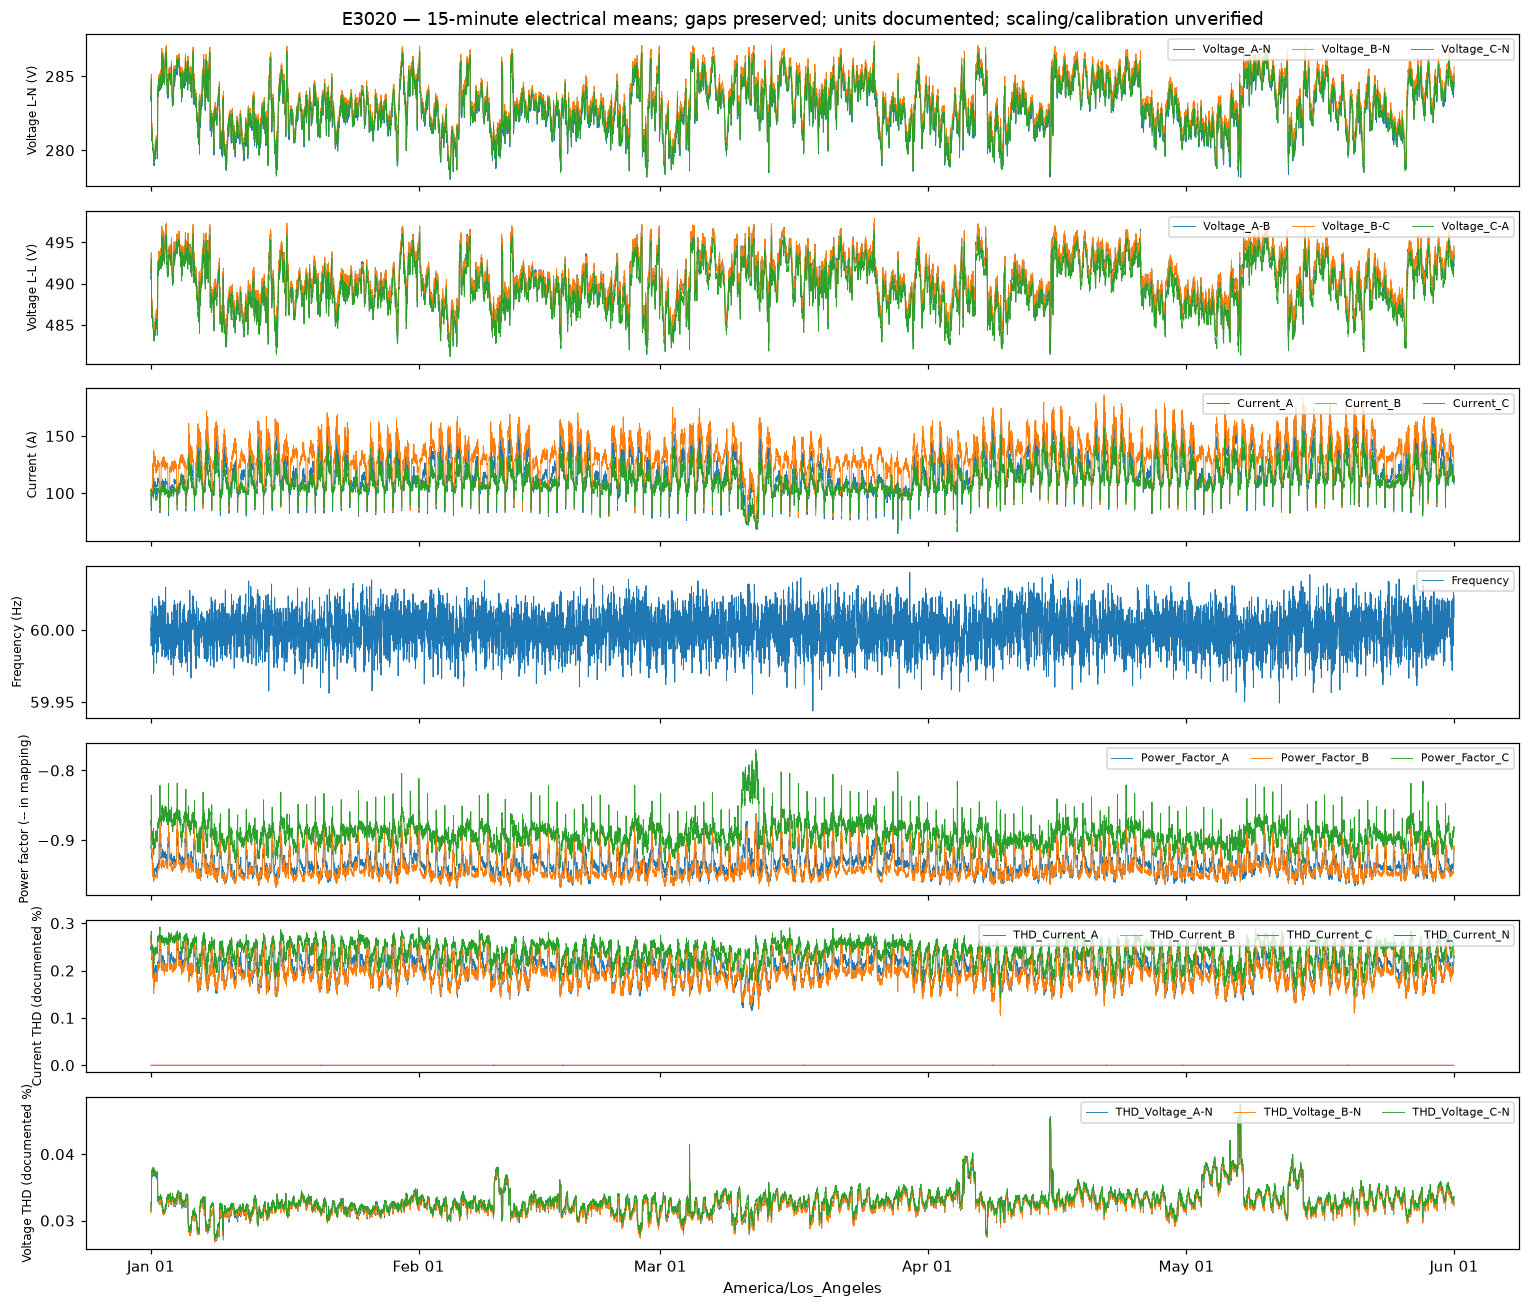

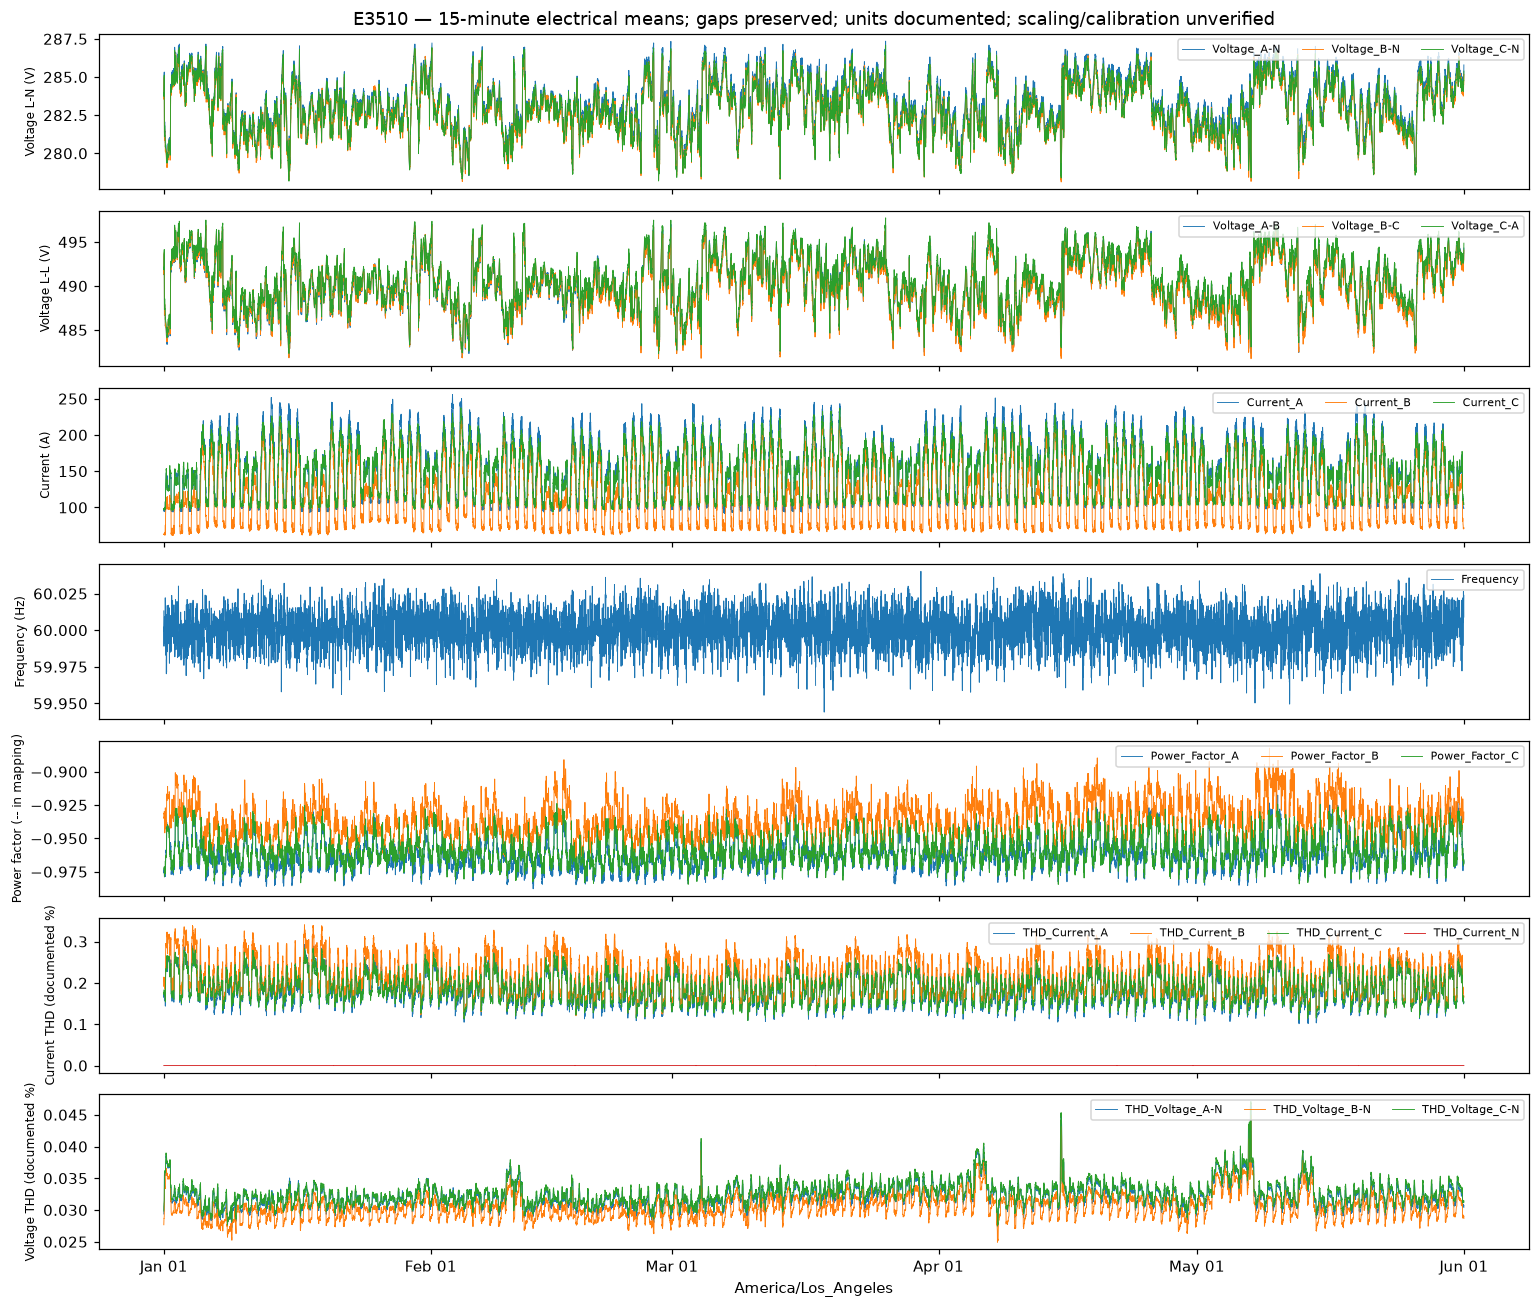

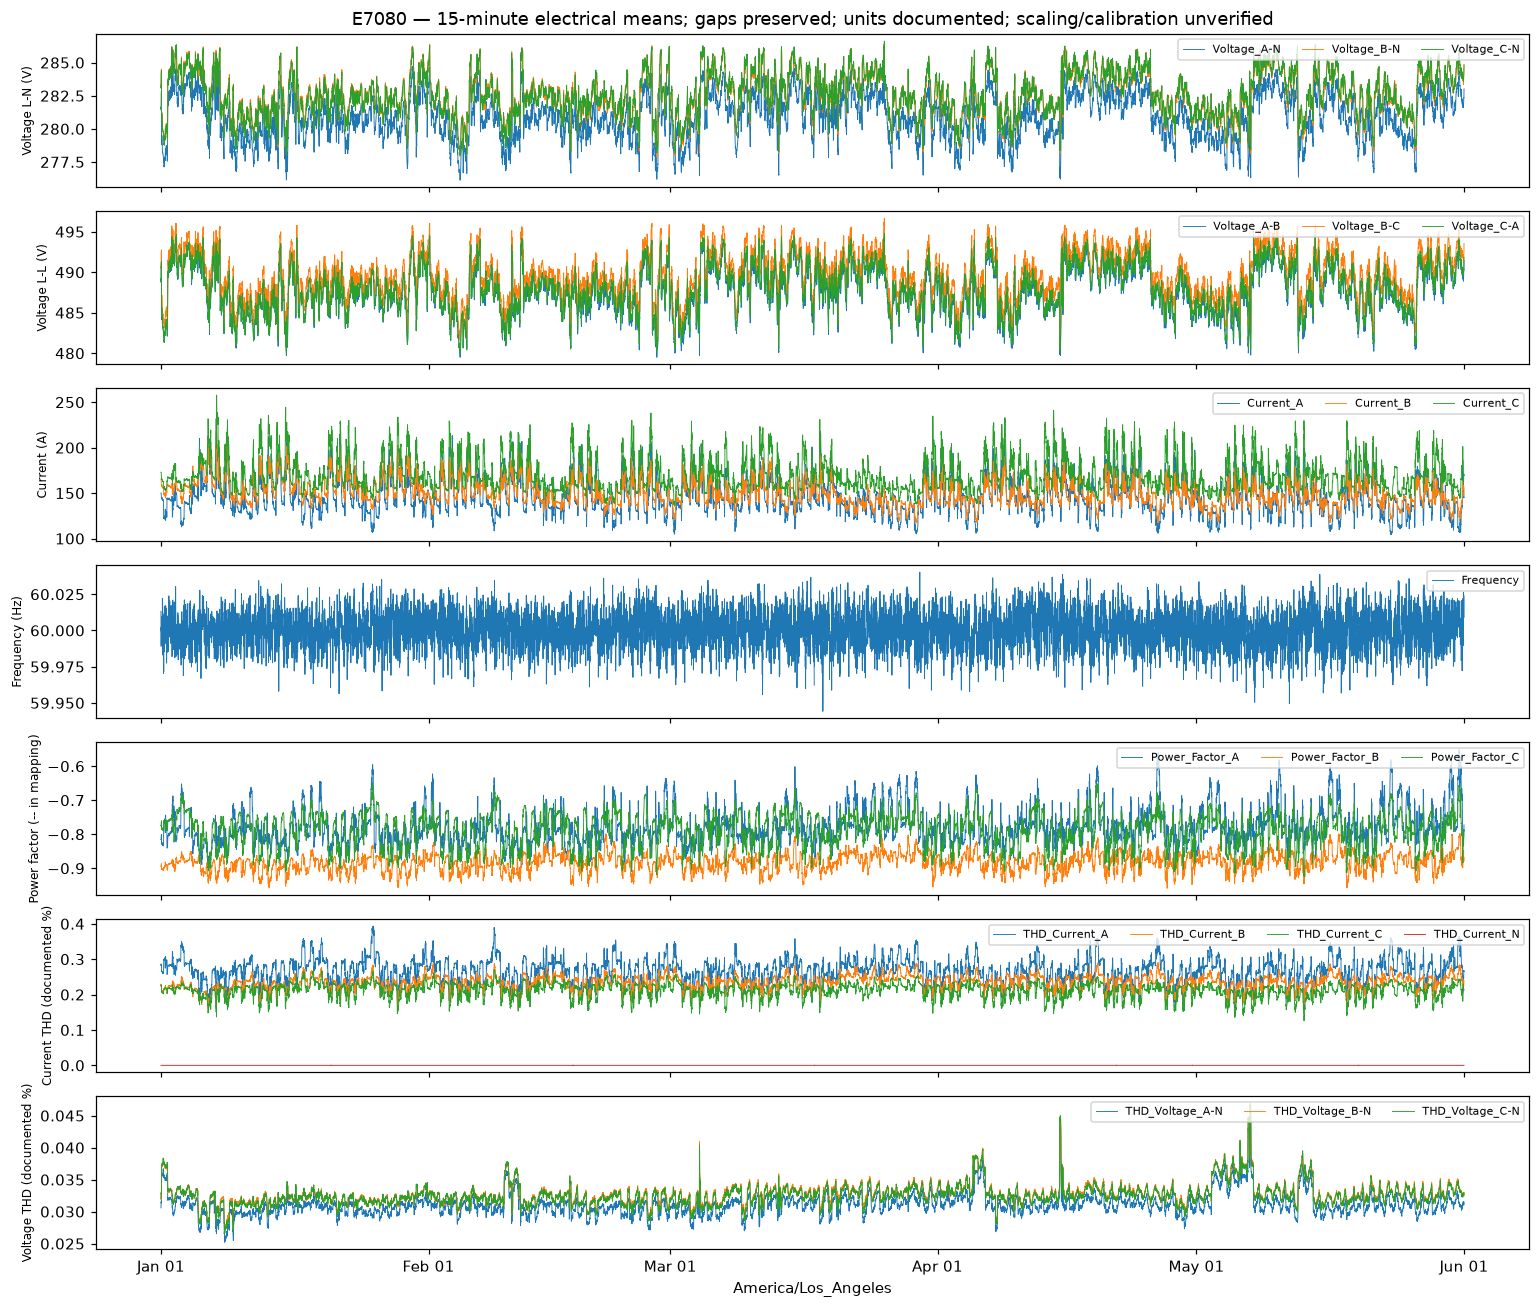

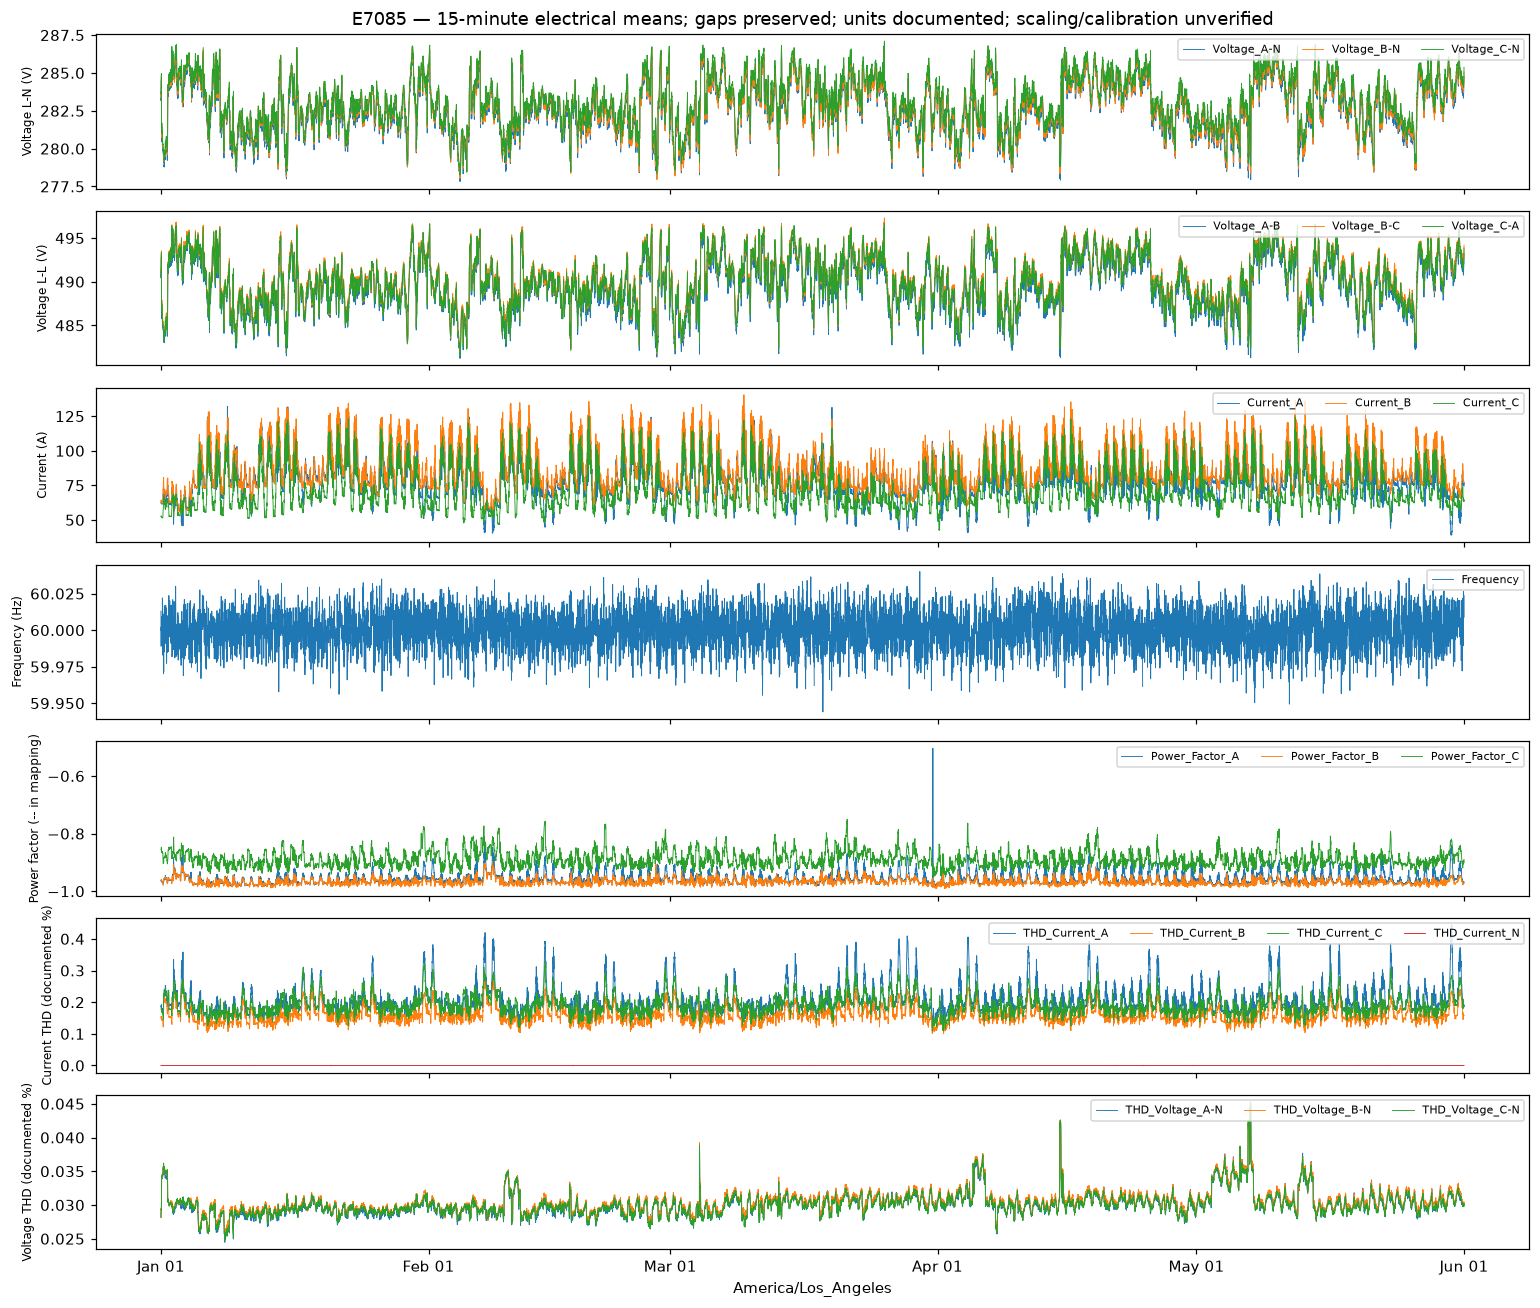

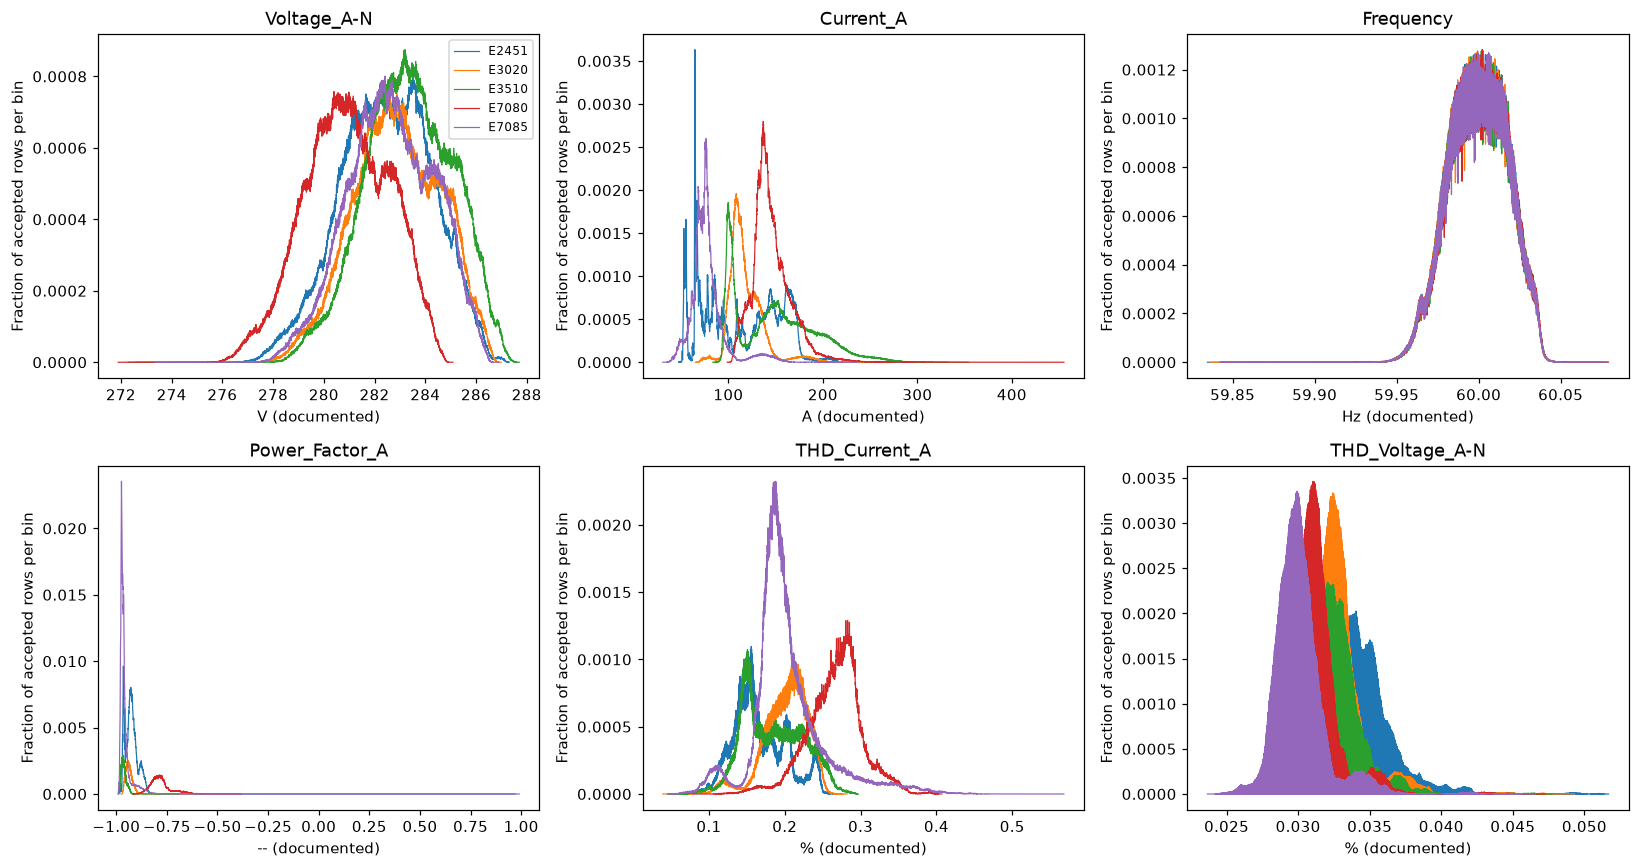

,device,measurement,paired_15min_bins,median_phase_mean_spread,p95_phase_mean_spread
0,E2451,Voltage L-N,14465,0.412143,0.740978
1,E2451,Current,14465,14.693052,29.885510
2,E2451,Power factor,14465,0.082308,0.135479
3,E3020,Voltage L-N,14478,0.545253,0.734140
4,E3020,Current,14478,22.809264,30.719953
5,E3020,Power factor,14478,0.050182,0.068651
6,E3510,Voltage L-N,14479,0.441286,0.692634
7,E3510,Current,14479,32.434366,42.173645
8,E3510,Power factor,14479,0.023460,0.049326
9,E7080,Voltage L-N,14480,1.782448,2.043330


**J — Channel review findings.** Registers with at least one constant or unavailable meter combination: `THD_Current_N`. Review the per-meter table before selecting channels; this is a usability review, not a fault classification.

**J — Computed findings.** 110/110 electrical meter/register combinations have accepted finite observations. 5 have constant accepted values; 0 have no accepted finite observations; the availability table identifies them individually. Phase-spread statistics compare simultaneous **bin means**, not instantaneous phase unbalance. They establish no electrical fault. These channels are candidates for later monitoring, but the Buildings Power quality card has no measurement renderer; current/PF/THD displays need frontend work in the inspected dashboard. Their existence alone does not make an existing feature ready.

In [30]:
if HL_EXTRA is not None:
    HL_ELECTRICAL_FAMILIES = {
        'Voltage L-N (V)': ['Voltage_'+p+'-N' for p in 'ABC'],
        'Voltage L-L (V)': ['Voltage_A-B', 'Voltage_B-C', 'Voltage_C-A'],
        'Current (A)': ['Current_'+p for p in 'ABC'],
        'Frequency (Hz)': ['Frequency'],
        'Power factor (-- in mapping)': ['Power_Factor_'+p for p in 'ABC'],
        'Current THD (documented %)': ['THD_Current_'+p for p in 'ABCN'],
        'Voltage THD (documented %)': ['THD_Voltage_'+p+'-N' for p in 'ABC'],
    }
    # One full-period phase-comparison figure per device, with a separate scale per family.
    for device in HL_DEVICES:
        bins = HL_EXTRA['aggregates'][device]
        fig, axes = plt.subplots(len(HL_ELECTRICAL_FAMILIES), 1, figsize=(14, 12), sharex=True)
        for ax, (family, registers) in zip(axes, HL_ELECTRICAL_FAMILIES.items()):
            plotted = False
            for register in registers:
                values = bins[register+'__mean']
                if values.notna().any():
                    ax.plot(bins.index, values, label=register, linewidth=.6); plotted = True
            if not plotted: ax.text(.5,.5,'Unavailable: no eligible finite bins',ha='center',transform=ax.transAxes)
            else: ax.legend(fontsize=7, loc='upper right', ncol=len(registers))
            ax.set_ylabel(family, fontsize=8)
        axes[0].set_title(device + ' — 15-minute electrical means; gaps preserved; units documented; scaling/calibration unverified')
        axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(tz=ZoneInfo(HL_TZ)))
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=ZoneInfo(HL_TZ)))
        axes[-1].set_xlabel(HL_TZ); plt.tight_layout(); plt.show()
    # Per-meter/per-register descriptive distributions; never mix incompatible units.
    selected = ['Voltage_A-N', 'Current_A', 'Frequency', 'Power_Factor_A', 'THD_Current_A', 'THD_Voltage_A-N']
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, register in zip(axes.flat, selected):
        for device in HL_DEVICES:
            hist, low, high = HL_EXTRA['histograms'][(device, register)]
            if hist.sum():
                centers = low + (np.arange(len(hist))+.5)*(high-low)/len(hist)
                ax.plot(centers, hist/hist.sum(), label=device, linewidth=.8)
        ax.set(title=register, xlabel=DOCUMENTED_UNITS[register]+' (documented)', ylabel='Fraction of accepted rows per bin')
    if axes[0,0].get_legend_handles_labels()[0]: axes[0,0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

    phase_rows = []
    for device, bins in HL_EXTRA['aggregates'].items():
        for stem, registers in [('Voltage L-N', ['Voltage_'+p+'-N' for p in 'ABC']),
                                ('Current', ['Current_'+p for p in 'ABC']),
                                ('Power factor', ['Power_Factor_'+p for p in 'ABC'])]:
            paired = bins[[r+'__mean' for r in registers]].dropna()
            spread = paired.max(axis=1) - paired.min(axis=1)
            phase_rows.append({'device':device,'measurement':stem,'paired_15min_bins':len(paired),
                               'median_phase_mean_spread':spread.median(),'p95_phase_mean_spread':spread.quantile(.95)})
    display(pd.DataFrame(phase_rows))
    constant = HL_ELECTRICAL_AVAILABILITY.query('constant or finite_rows == 0')
    constant_names = sorted(constant.register.unique())
    display(Markdown('**J — Channel review findings.** Registers with at least one constant or unavailable '
        'meter combination: '+(', '.join('`'+name+'`' for name in constant_names) if constant_names else 'none in this run')+
        '. Review the per-meter table before selecting channels; this is a usability review, not a fault classification.'))
    display(Markdown(f'**J — Computed findings.** {int(HL_ELECTRICAL_AVAILABILITY.finite_rows.gt(0).sum())}/{len(HL_ELECTRICAL_AVAILABILITY)} electrical meter/register combinations have accepted finite observations. {int(HL_ELECTRICAL_AVAILABILITY.constant.sum())} have constant accepted values; {int(HL_ELECTRICAL_AVAILABILITY.finite_rows.eq(0).sum())} have no accepted finite observations; '
        'the availability table identifies them individually. Phase-spread statistics compare simultaneous **bin means**, not instantaneous phase unbalance. '
        'They establish no electrical fault. These channels are candidates for later monitoring, but the Buildings Power quality card has no measurement renderer; current/PF/THD displays need frontend work '
        'in the inspected dashboard. Their existence alone does not make an existing feature ready.'))

## K — Cross-Meter Comparison

Unlike H's within-meter calendar descriptions, K restricts hourly power comparisons to the **intersection of eligible UTC hours across all selected meters**, reports how much of the union remains, and retains one phase at a time. Absolute mean and peak of hourly means describe scale. Dividing each meter by its own strictly positive median over that common window compares shape; it is not efficiency, per-area consumption, rated-capacity use or a verified total load. Nonpositive median normalization is withheld. No aggregate campus total or feeder relationship is inferred.

The classifications imported from A (`E2451` Instructional, `E3020` Mixed, `E3510/E7080/E7085` Office) are instructor-supplied context, not verified building mappings. One Instructional and one Mixed meter cannot establish class effects. Weather, holidays, floor area, occupancy, equipment ratings and wiring are unavailable for controlled comparisons. Different meters may overlap electrically, so they must not be summed by default.

Active_Power_A — common-hour statistics; power in kW. Peak is an hourly mean, not an instantaneous reading.


,mean,max,median,std,common_hours,union_hours,common_hours_pct,supplied_classification,building_mapping
E2451,29.772908,48.261876,29.098119,10.270265,3613,3623,99.723986,Instructional,Unverified
E3020,31.353292,44.068574,30.488557,4.276051,3613,3623,99.723986,Mixed,Unverified
E3510,40.979295,68.498164,40.034779,10.699306,3613,3623,99.723986,Office,Unverified
E7080,32.174824,52.474562,31.567274,5.722218,3613,3623,99.723986,Office,Unverified
E7085,21.042278,32.779939,20.996333,3.519937,3613,3623,99.723986,Office,Unverified


Active_Power_B — common-hour statistics; power in kW. Peak is an hourly mean, not an instantaneous reading.


,mean,max,median,std,common_hours,union_hours,common_hours_pct,supplied_classification,building_mapping
E2451,25.204630,43.114157,24.140462,9.352330,3613,3623,99.723986,Instructional,Unverified
E3020,34.901732,47.716502,35.439094,4.905641,3613,3623,99.723986,Mixed,Unverified
E3510,32.222222,58.994573,31.215406,11.428698,3613,3623,99.723986,Office,Unverified
E7080,37.587274,55.965905,36.789281,4.291052,3613,3623,99.723986,Office,Unverified
E7085,23.420792,34.022395,22.453322,3.941421,3613,3623,99.723986,Office,Unverified


Active_Power_C — common-hour statistics; power in kW. Peak is an hourly mean, not an instantaneous reading.


,mean,max,median,std,common_hours,union_hours,common_hours_pct,supplied_classification,building_mapping
E2451,24.982147,41.638993,24.481035,9.017848,3613,3623,99.723986,Instructional,Unverified
E3020,28.281004,39.403257,27.769650,2.971932,3613,3623,99.723986,Mixed,Unverified
E3510,40.119303,62.090093,40.348069,9.213504,3613,3623,99.723986,Office,Unverified
E7080,38.326148,59.183349,36.770502,6.325954,3613,3623,99.723986,Office,Unverified
E7085,18.022313,28.146154,17.130213,3.651390,3613,3623,99.723986,Office,Unverified


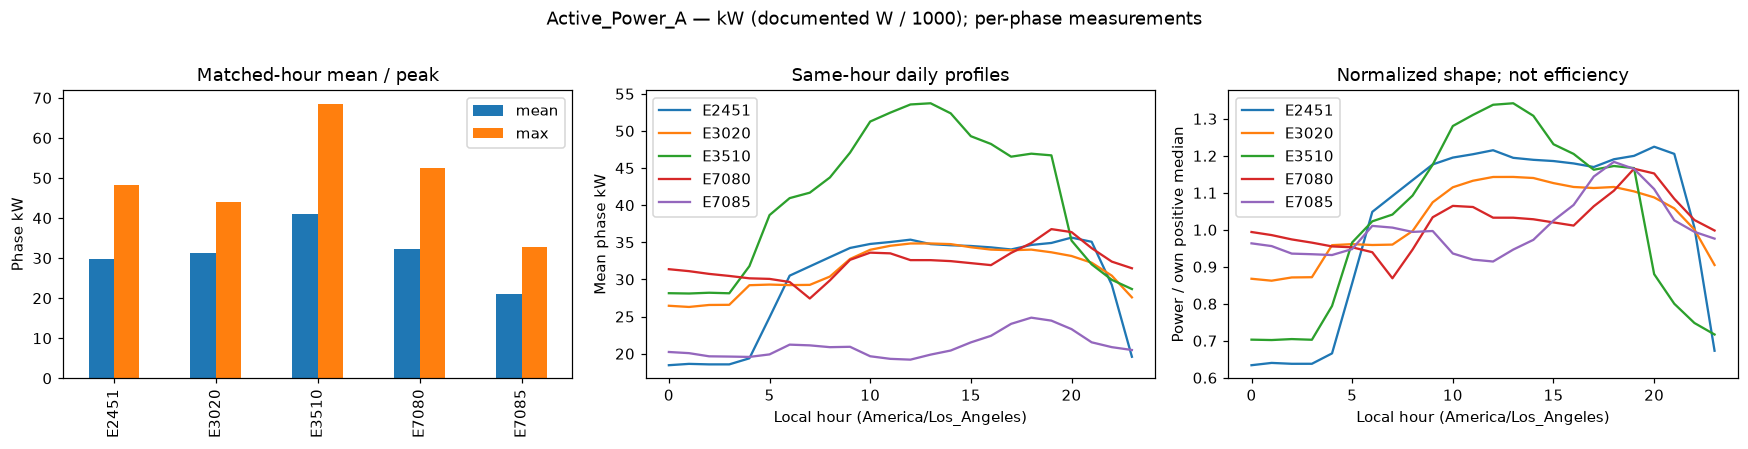

**K — Scale finding (Active_Power_A).** E3510 has the largest mean and E7085 the smallest mean over the common eligible hours. This ranking compares observed phase power only; it does not rank building efficiency or establish a classification effect.

**K — Computed scope.** 3,613 common eligible hours support the phase-power comparison. Absolute and normalized profiles separate scale from shape; classifications are annotations only. These summaries support adapting the measured traces in Investigation → Related-meter comparison, currently gated by event selection. They also inform Buildings comparison bars after physical meter/building and non-overlap metadata are verified.

,register,device,documented_unit,common_15min_bins,union_15min_bins,mean,peak_bin_mean,median,std
0,Current_A,E2451,A,14459,14492,114.492787,189.670481,113.899617,40.020622
1,Current_A,E3020,A,14459,14492,118.431612,168.480684,114.922881,15.390607
2,Current_A,E3510,A,14459,14492,150.627119,255.600837,149.185661,40.314392
3,Current_A,E7080,A,14459,14492,145.898852,215.585792,142.353694,18.965465
4,Current_A,E7085,A,14459,14492,77.944903,131.960642,76.898348,13.127045
...,...,...,...,...,...,...,...,...,...
105,Voltage_Unbalance_L-N_Worst,E2451,%,14459,14492,0.000874,0.002509,0.000855,0.000364
106,Voltage_Unbalance_L-N_Worst,E3020,%,14459,14492,0.001106,0.002063,0.001128,0.000259
107,Voltage_Unbalance_L-N_Worst,E3510,%,14459,14492,0.000898,0.002032,0.000891,0.000286
108,Voltage_Unbalance_L-N_Worst,E7080,%,14459,14492,0.004074,0.005379,0.004075,0.000355


No common finite bins means unavailable, not zero. Different register families have different common scopes.


In [31]:
if HL_READY:
    HL_MATCHED = {}
    for channel in FULL_RESULT['channels']:
        common, summary, normalized = matched_comparison(FULL_RESULT, channel)
        summary['supplied_classification'] = summary.index.map(METERS)
        summary['building_mapping'] = 'Unverified'
        HL_MATCHED[channel] = (common, summary, normalized)
        print(channel, '— common-hour statistics; power in kW. Peak is an hourly mean, not an instantaneous reading.')
        display(summary)
    common, summary, normalized = HL_MATCHED[HL_POWER_CHANNEL]
    if common.empty:
        print('No all-meter common eligible hours: comparisons withheld; do not infer similarity from unmatched periods.')
    else:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        fig.suptitle(HL_POWER_CHANNEL+' — kW (documented W / 1000); per-phase measurements', y=1.01)
        summary[['mean','max']].plot.bar(ax=axes[0]); axes[0].set(ylabel='Phase kW', title='Matched-hour mean / peak')
        local_hour = common.index.tz_convert(HL_TZ).hour
        common.groupby(local_hour).mean().reindex(range(24)).plot(ax=axes[1])
        axes[1].set(xlabel=f'Local hour ({HL_TZ})', ylabel='Mean phase kW', title='Same-hour daily profiles')
        normalized.groupby(local_hour).mean().reindex(range(24)).plot(ax=axes[2])
        axes[2].set(xlabel=f'Local hour ({HL_TZ})', ylabel='Power / own positive median', title='Normalized shape; not efficiency')
        plt.tight_layout(); plt.show()
        largest, smallest = summary['mean'].idxmax(), summary['mean'].idxmin()
        display(Markdown(f'**K — Scale finding ({HL_POWER_CHANNEL}).** {largest} has the largest mean '
            f'and {smallest} the smallest mean over the common eligible hours. This ranking compares observed '
            'phase power only; it does not rank building efficiency or establish a classification effect.'))
        display(Markdown(f'**K — Computed scope.** {len(common):,} common eligible hours support the phase-power comparison. '
            'Absolute and normalized profiles separate scale from shape; classifications are annotations only. '
            'These summaries support adapting the measured traces in Investigation → Related-meter comparison, currently gated by event selection. '
            'They also inform Buildings comparison bars after physical meter/building and non-overlap metadata are verified.'))
if HL_EXTRA is not None:
    # Electrical comparisons use per-register common 15-minute bins, not unequal per-meter histories.
    comparisons = []
    for register in ELECTRICAL:
        wide = pd.DataFrame({device: frame[register+'__mean'] for device, frame in HL_EXTRA['aggregates'].items()})
        common = wide.dropna(how='any')
        for device in wide.columns:
            comparisons.append(dict(register=register, device=device, documented_unit=DOCUMENTED_UNITS[register],
                common_15min_bins=len(common), union_15min_bins=len(wide),
                mean=common[device].mean(), peak_bin_mean=common[device].max(),
                median=common[device].median(), std=common[device].std(ddof=0)))
    HL_ELECTRICAL_COMPARISON = pd.DataFrame(comparisons)
    display(HL_ELECTRICAL_COMPARISON)
    print('No common finite bins means unavailable, not zero. Different register families have different common scopes.')

## L — Dashboard Feature Readiness and Integration Recommendations

### Part 1 — Assessment of the actual dashboard

Code inspected at base `aad7710b123b07c7ab9c83580618b5d839a1555e`, branch `feature/derconnect-dashboard-eda-addition`, November 11, 2026. This assessment comes from `js/sections/{overview,buildings,investigate,upload,models,export}.js`, `js/{store,charts,csv,reports,util}.js` and `index.html`, rather than README feature claims. The application has four main analysis sections **plus CSV Upload and Export Reports**. It uses static JavaScript globals, classic script order, shared `DC` selectors and SVG charts; no dashboard code is changed here.

**Readiness labels:** **Ready for integration** means required real measurements and semantics are sufficiently validated, not merely columns present. **Requires preparation or validation** means measurements exist but an adapter, semantics or metadata still needs work. **Not currently supported** means required data/metadata or an existing component is absent. **Requires anomaly detection** means the current feature depends on events, labels or model output (forecast-only overlays also need a forecaster, even without an event detector).

**No complete existing feature is declared Ready for integration yet.** Full-period observation availability is strong evidence for feasibility, but timezone/calendar assumptions, instrument scaling/calibration/signs (units now documented) and physical mappings are unresolved, and the current store expects synthetic hourly data. The measured parts of trends, profiles, peaks and completeness are the closest candidates. This is not a finding that measurements are unusable. Numerical availability/variation claims must come from the current H–K outputs; if those cells did not run, this remains a conditional source-code assessment.

`AP` below means exactly `Active_Power_A`, `Active_Power_B`, `Active_Power_C`, in the source's documented W; `_time` and `DeviceID` are required for every measurement feature. Each AP phase remains a separate channel. “Measured part” describes an adaptation to an existing card, not a claim that it already runs independently in the browser.

| Existing dashboard feature | Component / section (source) | Required DERCONNECT columns | Preparation / aggregation | Recommended visualization within existing component | Limitations / reason | Implementation readiness |
|---|---|---|---|---|---|---|
| Measured historical power trace | Overview → Actual vs. expected consumption (`overview.js`); Buildings → demand (`buildings.js`) | `_time`, `DeviceID`, AP | Source validation; phase-specific 15-min and hourly grids, coverage and nulls | Existing time-series measured line, optional observed min–max envelope | Remove/withhold expected and event layers for a measured-only view; total/physical mapping unresolved | **Requires preparation or validation** |
| Peak-demand numbers and daily peaks (measured part) | Overview demand summary; Buildings profile summary and advanced Peak demand analysis | `_time`, `DeviceID`, AP | Daily maxima of raw accepted rows and separately 15-min means, exact source time vs. interval start | Existing peak number and daily peak line, clearly labeled resolution | Highest recorded ≠ full-period or billing peak; no validated “normal” threshold; remove forecast/exceedance/event interpretation | **Requires preparation or validation** |
| Typical daily / weekday-weekend profiles | Buildings advanced → Typical daily profile | `_time`, `DeviceID`, AP | H hourly calendar groups, contributing days/hours and missingness | Existing weekday/weekend lines | Replace “clean history” with explicitly selected historical period; actual holidays/schedules unverified | **Requires preparation or validation** |
| Weekly trend and historical comparison | Buildings → Historical comparison; advanced → Load decomposition trend / weekly pattern | `_time`, `DeviceID`, AP | Matched local weeks, coverage-aware means; H is descriptive, not fitted baseline | Existing history text and trend/weekly line components | Decomposition's current centered window uses future observations and clean-history indexing; no clean period verified; H does not validate residual decomposition | **Requires preparation or validation** |
| Measured meter comparisons | Investigation → Related-meter comparison (`investigate.js`, `store.js`) | `_time`, `DeviceID`, same AP phase on all meters | K common UTC hours; units and optional own-median shape normalization | Existing aligned/small-multiple measured traces | Existing entry requires an event, and peer selection uses synthetic building/subgrid relationships; later add measured-only access and explicit meter choices | **Requires preparation or validation** |
| Building comparison / electricity-use totals | Overview → Electricity use by building; Buildings comparison bars/list/profile | `_time`, `DeviceID`, AP **or** `Active_Energy_in_Quadrant_I/II/III/IV`, verified mapping | Validate phase sums, energy-counter semantics/resets/rollovers or supported-duration integration; avoid overlap | Existing building bars/cards only after mapping; initially retain meter IDs | No verified building/main/PV/feeder relationships, area or non-overlap topology; H–K power means are not kWh | **Not currently supported** |
| Meter-data completeness / recording quality | Overview completeness KPI; Buildings completeness; Investigation data-quality strip; CSV Upload meter table | `_time`, `DeviceID`, AP / selected register, source manifest and expected cadence | Reuse F diagnostics; coverage per finite channel and timestamp slots; retain missing/duplicate/invalid reasons | Existing completeness KPI/table/quality strip after semantics change | Current `dq` conflates missing/zero and assigns stuck; real zero/constant is not automatically bad. F calendar/cadence need sign-off; Investigation access event-gated | **Requires preparation or validation** |
| Browser measured CSV preview | CSV Upload → Measured readings / Meters in this file (`upload.js`, `csv.js`) | Current browser format `timestamp,meter_id,kw`; raw inputs `_time,DeviceID` plus one validated AP channel | Small phase-declared 15-min/hourly preview; UTC ISO timestamps; bounded <20 MB CSV | Existing measured line + meter summary table | Raw archive schema not accepted; phase/provenance/coverage do not fit required 3 columns. Extras ignored; current preview completeness uses first/last observed cadence, not F's full-calendar coverage | **Requires preparation or validation** |
| Voltage/current monitoring requested in J | Buildings has a Power quality placeholder for voltage/frequency; current has no renderer | `Voltage_A-N/B-N/C-N`, `Voltage_A-B/B-C/C-A`, `Current_A/B/C`, `_time`, `DeviceID` | J accepted-row review, documented units plus scaling/calibration/wiring review, 15-min mean/min/max | Candidate later measurement trace, **not an existing supported feature** | Placeholder lacks a measurement renderer/channel contract; CT/PT, RMS/wiring and constant channels require validation | **Not currently supported** |
| Frequency / PF / THD monitoring requested in J | Buildings Power quality placeholder has no renderer; PF/THD have no active component | `Frequency`, `Power_Factor_A/B/C`, `THD_Current_A/B/C/N`, `THD_Voltage_A-N/B-N/C-N`, `_time`, `DeviceID` | J availability/constant-channel review; PF numeric convention, THD definition and resolution review (THD % is documented) | Later unit-specific traces, not anomaly-type distribution | Placeholder only; measurement semantics and usable channels unresolved; no validated engineering limits | **Not currently supported** |
| Raw/aggregated power distribution plot | No existing power-distribution panel; Overview distribution is **anomaly types**, not demand | `_time`, `DeviceID`, AP | I histograms or exact aggregate quantiles; label population and resolution | EDA-only distributions; do not repurpose anomaly-type chart silently | Useful EDA, but outside adapting an existing monitoring feature | **Not currently supported** |
| Sub-grid totals / health | Buildings advanced → Sub-grid health | AP + verified feeder membership and non-overlapping meter roles | Align timestamps, validate hierarchy before summing; separate DQ from events | Existing table measured columns only after metadata | Feeder topology absent; current table also contains event counts | **Not currently supported** |
| Solar generation context / weather / occupancy | Buildings advanced Solar; Investigation Context lens | Verified PV meter, weather irradiance/temp/cloud, occupancy/time alignment | Unit/sign validation, context joins and provenance | Existing context panels only with real supplied sources | These sources/roles are absent; never borrow synthetic context | **Not currently supported** |
| Actual–expected deviation heatmap, residuals, forecast bands | Buildings historical deviation heatmap; Overview/Investigation/Models expected and forecast views | Real forecasts q01/q10/q50/q90/q99 with origins/horizons/units, plus AP | Agree forecast contract and align observation/forecast pairs | Existing heatmap/bands only with model evidence | Observations alone cannot supply expected demand; no real forecasts supplied. Requires a forecaster, not necessarily event detection | **Requires anomaly detection** (model-output dependency) |
| Event review queue, type/severity plots, event heatmaps, explanations, status workflow | Overview / Investigation / Buildings anomalies | Real events, intervals, scores, priority/classification/provenance | Future detector/event contract and engineering review | Existing event components | No real detections/labels; unobserved ≠ false positive; EDA peaks are not events | **Requires anomaly detection** |
| Model performance / detection evaluation | Models (`models.js`) | Forecasts/scores/events, held-out labels/matches and provenance | Separate splits, calibrated thresholds and valid evaluation | Existing model/evaluation panels only with real evidence | No real labels/models; synthetic accuracy cannot transfer | **Requires anomaly detection** |
| PDF reports | Export Reports (`export.js`, `reports.js`) | Current reports combine real AP/mapping/DQ with events and model fields | Later measurement-only report model; provenance and unavailable sections | Existing PDF mechanism after report model review | Export renderer exists, but current complete reports are tied to synthetic store and event/model summaries | **Requires preparation or validation** for measured-only report; current event report **Requires anomaly detection** |

### Part 2 — Concrete preparation plans (recommendations, not implemented)

The following plans cover every measured feature/portion above that can operate independently of detection. Absent panels/topology are kept explicit; they are not proposed as immediate integration work.

**1. Historical measured traces — Overview and Buildings demand cards.** Require `_time`, `DeviceID`, `Active_Power_A/B/C`, source manifest and scaling/calibration/sign review (units documented). Reuse F's offset-aware UTC parsing, exact cross-file duplicate diagnostics, finite-number parsing and source-month/ID checks; quarantine ambiguous/naive timestamps and retain rejection reasons. Confirm filename-month timezone before excluding boundary observations. Preserve phase channels and signed zero/negative readings. Do not sum phases until the documented review passes, and do not infer meter roles. Use **hourly means for the five-month overview**, **15-minute means for ordinary selected ranges**, and optional existing five-minute summaries for detail; attach raw min/max so means do not disguise peaks. Only a bounded requested two-second window belongs in local engineering detail, not the entire static browser payload. Use the `measurement_bins` schema below, with null gaps and coverage. Remaining work: calendar and instrument scaling/calibration/sign review, adapter/version/offset/null tests and measured-only UI mode. **Requires preparation or validation**.

**2. Peak demand — measured Overview summary and Buildings peak card.** Same inputs as 1; retain accepted raw value and exact UTC timestamp for daily observed peaks, including earliest-tie rule and day coverage. Maintain a **separate** daily maximum of eligible **15-minute bin means**, timestamped by interval start. This is a fixed UTC-aligned statistic, not a utility demand tariff unless that definition is supplied. Monthly maxima are maxima of the corresponding daily statistic, with source coverage. Use `period_peaks(meter_id,channel,period_start_utc,period_end_utc,statistic,resolution_s,value,unit,peak_timestamp_utc,coverage_pct,eligible_bins,expected_bins,run_id)`. Show resolution in the existing number/line labels. Never import the current 99.5th “clean history” normal-peak threshold, exceedance stars or expected values from synthetic data. Source gaps limit observed maxima; tariff criteria and total-phase validation are pending. **Requires preparation or validation**.

**3. Typical daily profile, weekly trends and historical comparisons — Buildings.** Same AP inputs; use **hourly means** grouped by actual campus-local day/hour/day-of-week, not ID suffixes or index modulo 168. Report valid hours and day contributions for weekday/weekend/month; compare matched dates/resolutions. Retain 23/25-hour days and partial weeks. Use `calendar_profiles(meter_id,channel,calendar_tz,period_start_utc,period_end_utc,group_kind,local_hour,local_weekday,mean_kw,median_kw,valid_hours,expected_hours,run_id)` plus daily/weekly summary rows with half-open UTC bounds and eligible-hour fraction. For existing history text choose an explicit comparison date range, not a presumed clean prefix. H's weekly means can feed the existing trend portion after review; the current residual decomposition additionally needs a missing-aware method, clear retrospective label and a justified seasonal reference. Do not port its centered future-observation arithmetic as an online statistic. No verified holiday/occupancy schedule is available. **Requires preparation or validation**.

**4. Meter comparison — Investigation related-meter measured traces.** Require the same phase AP and UTC alignment for each selected `DeviceID`; keep IDs rather than fake building names. Start with **hourly matched timestamps** for five-month shape and **15-minute matched timestamps** for selected ranges; report common/union scope and avoid unqualified pairwise ranks over unequal windows. Reuse measurement bins; optional `comparison_scope(scope_id,meter_ids,channel,start_utc,end_utc,resolution_s,common_bins,union_bins,normalization,normalization_reference)` records own-positive-median normalization. Never treat that normalization as energy efficiency or facility size. Existing component needs independent meter/time selection because it is event-gated; building/subgrid peer groups await metadata. No cross-meter sums until electrical overlap is known. **Requires preparation or validation**.

**5. Data quality / completeness — existing Overview KPI, CSV meter table, later Buildings/Investigation quality strip.** Require `_time`, `DeviceID`, selected register(s), expected source file/month manifest and owner-confirmed cadence/calendar. Reuse F's diagnostics rather than rerun a competing quality policy; preserve raw invalid/naive/out-of-order/duplicate and missing-column counts separately from timeline coverage. Use **5/15/60-minute channel coverage**, plus daily/monthly rollups weighted by expected elapsed slots (DST-aware), not mean percentages. Propose `quality_bins(meter_id,channel,start_utc,end_utc,expected_slots,observed_slots,finite_slots,duplicate_rows,invalid_values,absent_column_rows,reason_codes,run_id)` and source-file diagnostics. Leave physical zeros valid unless source evidence says otherwise; label constant channels “review” rather than “stuck fault.” Existing `dq=1/2` meaning and event-gated navigation require later revision; browser preview completeness needs its denominator made explicit. **Requires preparation or validation**.

**6. Browser CSV preview — CSV Upload.** With W documented, after the chosen phase identity/sign and source scaling are reviewed, prepare a **small 15-minute/hourly selected-scope** file with exactly `timestamp,meter_id,kw` for compatibility; UTC timestamps must fit the parser's supported ISO millisecond precision. A filename/visible source declaration and companion manifest must state the single phase, kW conversion, aggregation, source hashes and coverage filtering. The current parser ignores extra columns and does not preserve per-bin coverage or channel metadata; three-column preview is therefore a limited review checkpoint, not the canonical table. Do not fabricate new physical meter IDs for phases. Gaps must remain explicit null rows on a regular grid, with an explicit start/end period; current preview metrics use observed bounds rather than expected calendar completeness. Require human review of that information loss before using the preview as quality evidence. Enforce existing **20 MB** limit. No conversion/export is performed here. **Requires preparation or validation**.

**7. Electricity-use / building overview / feeder totals — existing comparison bars and cards, deferred.** Require verified `DeviceID`→physical building/main/PV/feeder mapping, topology with overlap rules, phase units/additivity and import/export signs. For counters require exact `Active_Energy_in_Quadrant_I/II/III/IV` definitions, cumulative-versus-interval semantics, scale, reset/rollover behavior and which quadrants represent import/export. Counter behavior was not analyzed in H–K; numerical presence alone does not validate kWh. If using power instead, agree time integration, supported sample duration and gap boundaries; do not multiply an incomplete mean by a whole day or sum irregular kW readings as kWh. Prepare daily/monthly `energy_periods(...,observed_energy_kwh,covered_duration_s,expected_duration_s,method,sign_convention,completeness,run_id)` only after this review; missing energy remains unavailable. Registry fields include source reference, validity dates, verified role and optional classification (area/capacity only if supplied). Building names must remain unavailable now. **Not currently supported**; meter-only power is covered by plans 1–4.

**8. Measurement-only PDF summaries — existing Export Reports mechanism, later.** Require validated bins, peaks, coverage, source provenance and any physical mapping actually used; no extra raw scan. Summarize **hourly/daily** selected-range measurements and list resolution/coverage/assumptions. Use the same measurement summary tables in a later measurement-only report model; withhold expected demand, severity, event status, excess energy and model accuracy unless corresponding real evidence exists. Current report builders consume synthetic `DC` state and are not an interchangeable real-data endpoint. **Requires preparation or validation**; current anomaly-specific reports remain detector-dependent.

**Electrical channels from J — validation backlog, not an existing-panel integration plan.** Exact fields and documented units are in J's checklist. Reuse UTC/ID/duplicate/finite handling, exclude no channel solely because it is constant, and get the instrument manual/CT/PT/sign/THD/PF definitions. Use a channel registry to distinguish RMS line-neutral/line-line, percent/ratio and validity at low current. Candidate 15-minute mean/min/max bins can use the schema below, with five-minute or bounded raw detail when engineering requirements justify it. These are descriptive displays, not formal power-quality compliance statistics; standard-specific measurement methods/limits are not supplied. The existing voltage/frequency placeholder needs a measurement renderer; current/PF/THD need separately scoped frontend functionality. **Not currently supported** as an existing feature.

**Proposed shared data structure (design only).** Partitioned **Parquet** by meter/month is recommended for offline processed tables, because this is a multi-million-row input; a later bounded **JSON** payload with strict `null` (never NaN/Infinity) can serve the existing static browser architecture without a backend. Do not send 32.6 million rows or load all raw files in memory. No Parquet engine is required to run this notebook and no adapter, file export or schema acceptance is implemented.

| Proposed table | Key and fields |
|---|---|
| `measurement_bins` | Unique `(dataset_version,meter_id,channel,bin_start_utc,resolution_s)`; `bin_end_utc` exclusive, `mean,min,max,std`, validated `unit`, `finite_rows`, `finite_slots`, `expected_slots`, `timestamp_coverage_pct`, `valid_coverage_pct`, `duplicate_count`, `quality_reasons`, `run_id`. Power in validated kW; other channels retain their own validated units. Statistics method and coverage policy version required. |
| `channel_registry` | `(meter_id,channel,valid_from_utc)`; raw register, documented unit, source reference and separate engineering validation status, scale, sign convention, phase/wiring/CT/PT, expected cadence, usable/constant-review status, source reference. Unknown fields stay null. |
| `meter_registry` | Stable raw `DeviceID`, optional verified physical building/role/feeder, classification and provenance/validity dates; unknown associations null. Never import synthetic relationships. |
| `run_manifest` | Schema version, source file names and SHA-256 content hashes, source row counts, calendar/display timezone, UTC bounds, cadence/jitter/duplicate/coverage policy, aggregation method, code commit and dependency versions, unit/mapping review references. Supplemental scan prints a ZIP-name/CRC/size fingerprint for run comparison; **that is not a substitute for source SHA-256**. |

No forecast/label/event fields are required for these measurement tables. If such evidence arrives later, store it separately with its own provenance and half-open bounds. Preserve the stable chart interface at a future boundary adapter; do not write independent copies of filtering/time/quality logic in each section. Current `DC.store` requires building relationships, detector selection and fixed hourly indices; `DC.energy` assumes one-hour kW and zero-fills, `DC.time` uses synthetic wall-time-as-UTC and weekly modulo logic, and missing/constant real channels do not map to synthetic `dq` policy. A later adapter must explicitly address those assumptions, null handling, UTC/display time and measured-only availability before any real payload replaces synthetic globals.

### Part 3 — Prioritized implementation sequence

1. **Agree the measurement-only contract and produce verified summaries first.** Record the documented units; confirm scaling/calibration/signs, timestamp/filename calendar, cadence/duplicate policy, source manifest and phase semantics; use F and H–K output tables to select usable channels. Validate nulls, irregular/duplicate/out-of-order times, DST, mapping and schema compatibility with fixtures. This is the prerequisite for honest measurements and quality indicators; it is not a model project.
2. **Integrate measured per-phase historical trends together with completeness.** Adapt Overview's existing measured trace and quality KPI, with meter-ID scope. Hourly overview/15-minute range data fit existing SVG components and give managers useful history while engineers can see missing periods. If a preview is needed before shared-store work, the bounded CSV Upload pathway is the smallest preparatory checkpoint, with its phase/coverage limitations declared.
3. **Add measured daily/15-minute peaks and historical peak comparisons.** Existing Buildings peak/summary components are close matches; preserve observed raw maxima/time separately from sustained interval demand and remove unsupported normal/expected/event meaning. Useful for demand review without any detector.
4. **Populate daily weekday/weekend profiles, weekly means and explicit historical comparisons.** Reuse Buildings components after local calendar/coverage validation. These need only validated power and support scheduling questions; defer clean-history residual decomposition until its separate assumptions are reviewed.
5. **Make the existing measured meter comparison accessible without an event.** Reuse common-window K summaries and measured comparison traces; keep phase/scale/normalization clear and meter selection explicit. Requires more routing/peer-selection preparation than simple trends.
6. **Enable building-level consumption and feeder summaries only after metadata and energy validation.** Ask the data owner for physical mapping, topology/roles and register/counter documentation; test phase additivity or supported-duration energy integration. Their usefulness is high, but present inputs cannot support credible building kWh totals.
7. **Reuse PDF export for measurement-only summaries after the above data model is stable.** This adds review value without new models but requires report content/provenance changes; it should not precede trustworthy live measurement views.

Electrical voltage/current/frequency/PF/THD monitoring is a **validation backlog**, not an immediate existing-feature integration: verify J's channels and definitions before separately scoping UI additions. Weather/occupancy/PV context, detection events, classifications, priority queues, forecast bands and model evaluation remain unavailable for real data. No model work is needed to complete priorities 1–5 or a later validated measurement-only report.

**H–L conclusion.** H supports period/profile choices; I distinguishes observed instantaneous and aggregated demand with explicit distributions; J identifies electrical-channel candidates and validation gaps; K compares meters on matched scopes; L maps only actual existing components to a conditional, concrete plan. The code-generated findings above are the empirical evidence for this run. Stable/low/missing measurements and high demand are not evidence of faults, missing labels are not false positives, and no simulated result establishes real-world detection performance.

# Section M — EDA Summary and Dashboard Integration Readiness

A short guide to the completed A–L findings and the next real-data pilot. Numerical power examples describe individual phases, not total building consumption.

## 1. Summary of EDA findings

| Section | What was analyzed | Important findings |
|---|---|---|
| **A — Dataset overview** | File inventory, meters and dates. | 25 CSVs from five meters, January–May 2026; about 3.51 GB compressed and 11.95 GB uncompressed. |
| **B — Schema and units** | Columns and the meter reading mapping. | One 37-column schema; all 35 documented registers match all 25 file headers. Active power is W; kW = W / 1,000. |
| **C — Timestamps** | Timestamp format and sampling. | Offset-aware timestamps, approximately two-second sampling with jitter; UTC conversion is supported. |
| **D — Availability** | Sampled missing, invalid and constant values. | All mapped registers appear across the five meters; some channels are constant and need usability review. |
| **E — Initial plots** | Short power traces and phase comparisons. | Phase differences and fluctuations are visible, but roughly 67-minute prefixes cannot establish daily schedules. |
| **F — Full-data quality** | Archive-wide completeness and recording gaps. | 32,580,214 rows; 99.704% slot coverage under the configured schedule/calendar; zero exact timestamp duplicates; 207 recording gaps, longest about 3 h 40 min. |
| **G — Aggregation** | Five-minute, 15-minute and hourly summaries. | Larger bins simplify trends but hide short peaks; min/max and coverage preserve useful context. |
| **H — Demand patterns** | Hourly, weekday/weekend and longer-period demand. | Phase A weekend means are lower at all five meters; daily shapes and monthly patterns differ by meter. |
| **I — Distributions and peaks** | Power variability and observed/aggregated peaks. | E2451 phase A: recorded maximum 69.86 kW versus maximum eligible 15-minute mean 49.29 kW. Raw quantiles are bounds. |
| **J — Electrical channels** | Voltage, current, frequency, PF, THD and phases. | All 110 electrical meter/register combinations have finite observations; neutral-current THD is constant at all five meters. THD is documented %; PF is `--`. |
| **K — Meter comparison** | Same-phase demand over common periods. | 3,613 common eligible hours; E3510 has the highest and E7085 the lowest phase-A mean on that scope. Normalized shape is not efficiency. |
| **L — Feature readiness** | Existing dashboard components and requirements. | Measured views can use observations; anomaly/forecast views require separate outputs. Power quality is currently a placeholder. |

## 2. Which dashboard features can use real DERCONNECT data?

**Standard preprocessing** turns raw readings into dashboard-usable data:

1. **Clean:** handle invalid values, duplicate timestamps and missing readings; keep gaps visible rather than filling them with zero.
2. **Transform:** apply documented conversions such as W to kW; organize readings by meter, phase and UTC timestamp.
3. **Aggregate:** create 15-minute/hourly summaries with counts and completeness, accounting for missing readings.
4. **Verify:** compare results with original CSV readings and completed EDA to check calculations.

These shared steps apply across the supported features and are not repeated below. Existing F–K helpers can be reused.

**“Yes” means measurements are available to support the feature after standard preprocessing—not that frontend integration is complete.** Connecting real data through the shared frontend and providing a clearly labeled measured-only mode is still implementation work. All measurement features need `_time` and `DeviceID`; **phase power** means a separate `Active_Power_A`, `Active_Power_B` or `Active_Power_C` channel.

| Existing dashboard feature | Can use real DERCONNECT data without anomaly detection models? | Required measurements | Additional requirements beyond standard preprocessing |
|---|---|---|---|
| **Historical measured trends** — Overview/Buildings demand charts | Yes | Phase power | None. |
| **Peak demand** — Overview summary/Buildings peak card | Yes | Phase power | Show measured peaks; omit unsupported “normal” thresholds and forecast/event overlays. |
| **Daily/weekly profiles and history** — Buildings | Yes | Phase power | Replace synthetic “clean history” and weekday assumptions with explicit observed reference periods/calendar grouping. |
| **Data completeness** — Overview KPI/meter tables | Yes | Timestamps, selected register and expected cadence | Replace fixture quality labels; real zero/constant readings are not automatically bad data. |
| **Meter comparisons** — Investigation related-meter view | Yes, with additional work | Same phase power across chosen meters | Add access without an anomaly event and explicit meter selection; physical peer groups need verified relationships. |
| **Building-level electricity use** — Overview/Buildings summaries | Yes, with additional work | Phase power or energy-quadrant registers | Need physical building/main-meter mappings and supported phase/energy semantics before reporting building kWh. |
| **Power quality** — Buildings placeholder | Yes, with additional work | Voltage channels and `Frequency` | Placeholder only: implement a measurement renderer; operating-range/fault interpretations need engineering criteria. |
| **CSV upload/preview** | Yes | One declared phase in `timestamp,meter_id,kw` format | File must be below 20 MB; declare phase/source separately because extra channel/coverage columns are ignored. |
| **Anomaly and forecasting visualizations** — Overview/Investigation/Models | No | Real events/scores/forecasts; labels for evaluation | Detector/forecaster outputs are required; measurements alone cannot populate these views. |

**Remaining interpretation limits:** DERCONNECT information is still needed for calibration/additional scaling, power direction, phase aggregation and physical meter-to-building relationships. These do not prevent a clearly labeled individual-channel pilot, but they do prevent unsupported claims about building totals, import/export or physical identity. Use UTC and label any assumed campus calendar explicitly while its convention is confirmed.

## 3. Why start with Active_Power_A?

`Active_Power_A` is documented active power in **W** and directly supports existing trends, peaks and load profiles. Starting with one meter, such as **E2451**, lets us test preprocessing, verification and display with less complexity, catch pipeline/frontend issues early, and avoid assuming that phases form a validated building total.

This is an initial test, **not a final dashboard limitation**. Expand the reusable approach to B/C, other meters, and voltage/current/frequency/PF where dashboard components support them. Processing all three power phases separately from the beginning is also reasonable if straightforward; summing them still needs supporting documentation.

## 4. Recommended next steps: Preprocess → Verify → Integrate

1. **Preprocess:** prepare a small E2451 phase-A sample covering weekdays/weekend. Convert W to kW, handle timestamp/data issues, and generate 15-minute/hourly summaries. Preserve meter/phase IDs, timestamps, gaps, completeness and source information; make the approach reusable across channels.
2. **Verify:** reconcile conversions, averages, counts, extrema and missing intervals against original CSV readings and existing F–K results. Reuse the EDA rather than repeating the full analysis.
3. **Integrate:** connect the sample to the existing historical measured-power chart, labeling meter, phase, units and period. Keep real data separate from synthetic/forecast/anomaly outputs. Check values, gaps and filters, then expand to completeness, peaks, profiles, comparisons and other supported channels.

**We can begin this work now without waiting for anomaly models or additional physical metadata**, provided channels and assumptions are labeled accurately. Building totals need metadata, power-quality rendering needs frontend work, and anomaly/forecast views need model outputs. This section recommends future work; it does not implement it.